# `sopfsl` — Second-order descriptors for training-free cross-domain few-shot learning

Companion notebook of the manuscript. It contains the complete code that produced the reported
results, with the outputs of the final run kept where they were recorded (environment, data
gates, in-sample λ summary, sensitivity split, figure production). Six target domains, five
frozen backbones (38 feature cells), thirteen descriptor methods (3 second-order statistics × 4
normalization levels + a first-order mean baseline), 600 episodes per condition.

## Workflow

The notebook is a pipeline of nine sections. **§0–§8 only define** functions, constants and
gates and run in seconds. **§9 does the work**, calling those definitions in order. Each code
cell is preceded by a short markdown note saying what it defines and which artefacts it reads
and writes.

```
§1 data            raw/<domain>/          ─► index/<domain>.json          gates K1–K6
§2 episodes        index/                 ─► episodes/pool__*, *__*shot    gates E1–E5, I1–I5
§3 features        images + pools         ─► feats/<cell>.npy + manifest  gates F1–F7
§4 descriptors     X ∈ R^{n×d}            ─► one d×d matrix per image     gates M1–M6
§5 scoring         feats + episodes       ─► results/<cell>.npz, .json    gates R1–R6
§6 cost            models                 ─► results/costs.json           gates P1–P6
§7 sensitivity     variants of §2         ─► results/<cell>@by_index|no_groups   gates V1–V5
§8 statistics      results/               ─► tests.json, raw_*.csv, figs/  gates T1–T8, H1–H6
§9 driver cells    run §9.1 → §9.15 in order, each ends with READY FOR STEP N or FAIL
```

Every artefact carries a hash of its inputs (`index_hash → pool_hash → feature_key →
result_key`), so a stale artefact is rebuilt rather than silently reused, and an interrupted
session resumes where it stopped.

## How to run

1. Google Colab, GPU runtime, high-RAM (see the warning below for the exact configuration).
2. Secrets, once per session: `secrets/kaggle.json` under the working directory (Kaggle API
   token, for crop disease and the ChestX sample) and a Colab secret `HF_TOKEN` with the two
   DINOv3 checkpoint licences accepted on Hugging Face (§3.3 prints the steps if missing).
3. `Runtime → Restart and run all`. Do not continue past a `FAIL` line in §9.

> ## ⚠️ Warning: configuration and run time
>
> **Reference configuration.** Every recorded output comes from Google Colab, Tesla T4 (16 GB),
> high-RAM runtime, torch 2.11 (CUDA 12.8), transformers ≥ 4.56, 202 GB of free disk at start.
> A full reproduction needs **a GPU runtime and at least 100 GB of free disk**. A CPU-only
> runtime is not practical: extraction and the `eigh` of the spectral levels become many times
> slower.
>
> **Disk.** Raw datasets take about 12 GB, the feature cache **49.2 GB** (§9.5 prints this budget
> before writing). The λ sweep (§9.12) adds temporary buffers that spill to disk when they exceed
> `RAM_LIMIT / LAM_CHUNK`: up to about 30 GB for crop disease at d = 1024 with `LAM_CHUNK = 4`.
> Peak use is therefore about 90 GB. A smaller `LAM_CHUNK` lowers the peak but repeats the `eigh`.
>
> **Run time on the reference configuration.**
>
> | Step | Wall clock | Source |
> |---|---|---|
> | §9.1 download and index | about 23 min (ISIC 13 min, ChestX 5 min) | recorded |
> | §9.3 to §9.4 pools, episodes, audits | about 2 min | recorded |
> | §9.5 feature extraction, 38 cells | about 21 min | recorded |
> | §9.8 scoring grid | about 3.3 h | recorded |
> | §9.10 sensitivity runs | about 30 min | recorded (26 min for 20 of 24 cells) |
> | §9.11 tests, 50,000 bootstrap replicates | about 10 min | recorded |
> | §9.12 λ sweep | about 2 to 4 h | estimate, not timed |
> | §9.6, §9.9, §9.13 to §9.15 | minutes each | estimate |
>
> The total, about 7 to 9 hours, **exceeds what a single Colab session reliably provides**.
>
> **Sessions.** Everything under `/content/sopfsl` is lost when the runtime is recycled. Every §9
> step resumes from the artefacts already on disk, so run the notebook over several sessions and
> back up the light artefacts to Google Drive between them:
>
> ```
> !tar -C /content/sopfsl -czf /content/drive/MyDrive/sopfsl_light.tar.gz index episodes results
> !tar -xzf /content/drive/MyDrive/sopfsl_light.tar.gz -C /content/sopfsl      # next session
> ```
>
> **Do not change the following between sessions**, or the run fails or silently mixes two
> numerical regimes:
>
> * `CONFIG` (especially `SEED`) and the `*_FORMAT` constants: any change invalidates the hash
>   chain and recomputes pools, episodes, features and results.
> * `BATCH_SIZE = 16` of §9.5 and the GPU type: resuming a half-extracted feature cell with
>   another batch size or GPU is refused (manifest check in §3.5).
> * If `results/` is restored but `feats/` is not, re-extract on the **same GPU type, torch
>   version and batch size**. Features from another configuration differ in the last bits, and
>   the bit-exact anchors of §8.4 (λ = 0 and λ = 0.1 against the canonical arrays) then fail.
>
> **Upgrades.** If §0.2 upgrades `transformers`, restart the session and run again from the top.
>
> **Other GPUs.** On a GPU other than the T4 the fp16 features differ in the last bits (gate F4b),
> so accuracies can deviate from the recorded tables in the last decimals. The conclusions rest
> on paired tests within one run and are expected to hold.

## Outputs and where they appear in the manuscript

| File | Cell | Used for |
|---|---|---|
| `results/raw_results.csv` | §9.13 | accuracy and AUROC tables, Pareto frontier figure |
| `results/raw_axis.csv` | §9.13 | boundary map and per-condition verdicts |
| `results/raw_confirm.csv` | §9.13 | confirmatory family (Holm), resolution pairs |
| `results/raw_second_vs_mean.csv` | §9.13 | second-order vs mean counts |
| `results/raw_sensitivity.csv` | §9.13, §8.5b | sampling-protocol sensitivity |
| `results/raw_lambda.csv` | §9.13, §8.5c | λ sweep (the λ=1 anchor is exported as well) |
| `results/tests.json` | §9.11 | every p-value and q-value in the paper |
| `results/costs.json` | §9.9 | MAC table and the cost axis of the frontier |
| `results/figs/`, `results/figs/final/` | §9.14, §9.15 | the four combined figures (Fig1–Fig4) |

All randomness derives from `CONFIG["SEED"]` through hashed sub-keys, so pools and episodes are
bit-identical on any machine (gate E4). The seed value itself carries no meaning: it is hashed
with a sub-key before seeding any generator.

## Datasets

| Domain | Source | Licence |
|---|---|---|
| `pallet` | HF `jjldo21/IndustrialLateralLoads` (DOI 10.57967/hf/4799) | MIT |
| `cropdisease` | Kaggle `saroz014/plant-disease` | see Kaggle |
| `eurosat` | `torchvision.datasets.EuroSAT` | MIT |
| `dtd` | `torchvision.datasets.DTD` | research use only |
| `isic` | ISIC 2018 Task 3 (public S3 of the challenge) | CC BY-NC, no image in figures |
| `chestx` | Kaggle `nih-chest-xrays/sample` (official 5% sample) | NIH |

---
# §0 — Environment

**§0.1** Protocol constants (`CONFIG`: seed, 5-way, 15 queries, 5 unknown classes, shots 1/5/10, 600 episodes, pool cap 200, random support/query split) and the working directories under `/content/sopfsl`.

In [ ]:
#@title §0.1 Configuration and paths
import os, sys, json, time, random, hashlib, shutil, subprocess, zipfile
from pathlib import Path

CONFIG = {
    "SEED":           20260822,
    "N_WAY":          5,           # known classes per episode
    "N_QUERY":        15,          # query images per class, known and unknown alike
    "N_OPEN":         5,           # unknown classes per open-set episode
    "SHOTS":          [1, 5, 10],
    "N_EPISODES":     600,         # episodes per cell (domain × regime × shot)
    "POOL_PER_CLASS": 200,         # cap on images per class that can enter episodes
    "SPLIT_POLICY":   "random",    # "random" (protocol) | "by_index" (only to measure its bias, §7)
}
# 600 episodes × 15 queries follow BSCD-FSL and the open-set line (PEELER, SnaTCHer, GEL).
# The per-class pool cap bounds feature extraction and is declared in the Methods with the seed.

WORK = Path("/content/sopfsl")

DIRS = {k: WORK / k for k in ("raw", "index", "episodes", "feats", "env", "secrets")}
for p in DIRS.values():
    p.mkdir(parents=True, exist_ok=True)

print(f"WORK {WORK}")

WORK /content/sopfsl


## Library versions

Nothing is pinned. Only missing packages are installed, with a single lower bound
(`transformers >= 4.56`, needed to load DINOv3), and the versions actually running are recorded
in `env/env.json`. Gate F5 (§3.6) warns when the environment drifts from the one that extracted
the features.

**Fonts.** Installs the Microsoft core fonts so that Arial is available to matplotlib. The figure gate H4 (§8.6) stops without it.

In [ ]:
# Arial (Microsoft core fonts) for the journal figures: §8.6 refuses to save a figure without it.
!apt-get update -qq
!echo "ttf-mscorefonts-installer msttcorefonts/accepted-mscorefonts-eula select true" | sudo debconf-set-selections
!apt-get install -y ttf-mscorefonts-installer
!fc-cache -f -v

**§0.2** Installs the packages Colab may lack (`kaggle`, `huggingface_hub`), enforces `transformers >= 4.56` (DINOv3), and records the running environment (`env/env.json`) for the Implementation details.

In [ ]:
#@title §0.2 Install missing packages and record the environment
# Arial for the figures (§8.6), then the packages the data layer imports that Colab may lack.
!echo "ttf-mscorefonts-installer msttcorefonts/accepted-mscorefonts-eula select true" | sudo debconf-set-selections
!apt-get install -y -qq ttf-mscorefonts-installer > /dev/null 2>&1 && fc-cache -f > /dev/null

import importlib.util
NEEDED = [("kaggle", "kaggle"), ("huggingface_hub", "huggingface_hub")]
MIN_VERSIONS = {"transformers": (4, 56)}      # DINOv3 support entered transformers in 4.56


def _version_tuple(v: str):
    out = []
    for part in str(v).split("."):
        digits = "".join(ch for ch in part if ch.isdigit())
        if not digits:
            break
        out.append(int(digits))
    return tuple(out)


def ensure_packages():
    missing = [spec for mod, spec in NEEDED if importlib.util.find_spec(mod) is None]
    if missing:
        print("installing:", " ".join(missing))
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

    stale = []
    for mod, floor in MIN_VERSIONS.items():
        try:
            have = _version_tuple(__import__(mod).__version__)
        except Exception:
            stale.append(f"{mod}>={'.'.join(map(str, floor))}")
            continue
        if have < floor:
            print(f"{mod} {'.'.join(map(str, have))} < {'.'.join(map(str, floor))} — upgrading")
            stale.append(f"{mod}>={'.'.join(map(str, floor))}")
    if stale:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", *stale], check=True)
        print("LIBRARIES UPGRADED — Runtime > Restart session, then run again from the top.")

    if not missing and not stale:
        print("nothing to install")


def env_snapshot(save: bool = True) -> dict:
    """Versions, GPU and CUDA actually running, written to env/env.json."""
    snap = {"timestamp": time.strftime("%Y-%m-%dT%H:%M:%S"),
            "python": sys.version.split()[0]}
    for mod in ("torch", "torchvision", "transformers", "numpy", "pandas", "PIL"):
        try:
            snap[mod] = __import__(mod).__version__
        except Exception:
            snap[mod] = None
    try:
        import torch
        snap["gpu"] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
        snap["cuda"] = torch.version.cuda
    except Exception:
        snap["gpu"] = snap["cuda"] = None
    if save:
        (DIRS["env"] / "env.json").write_text(json.dumps(snap, indent=2))
    return snap


ensure_packages()
ENV = env_snapshot()
for k, v in ENV.items():
    print(f"{k:>12} : {v}")
print(f"{'free disk':>12} : {shutil.disk_usage(WORK).free / 1e9:.1f} GB")

không cần cài gì thêm
   timestamp : 2026-09-13T01:54:10
      python : 3.13.15
       torch : 2.11.0+cu128
 torchvision : 0.26.0+cu128
transformers : 5.16.1
       numpy : 2.1.3
      pandas : 2.2.3
         PIL : 11.3.0
         gpu : Tesla T4
        cuda : 12.8
   đĩa trống : 202.1 GB


**§0.3** Utilities used everywhere: timestamped `log`, deterministic `sha256_obj` (the hash chain), atomic `write_json`, `read_json`, byte formatting.

In [ ]:
#@title §0.3 Utilities
_T0 = time.time()

def log(msg: str, *args) -> None:
    print(f"[{time.time() - _T0:6.1f}s] " + (msg % args if args else msg), flush=True)


def sha256_obj(obj) -> str:
    """Deterministic SHA-256 of a JSON-serialisable structure (sorted keys)."""
    blob = json.dumps(obj, sort_keys=True, ensure_ascii=False, separators=(",", ":"))
    return hashlib.sha256(blob.encode("utf-8")).hexdigest()


def write_json(path, payload, indent: int = 2) -> Path:
    """Atomic write: temporary file, then rename."""
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(payload, indent=indent, ensure_ascii=False), encoding="utf-8")
    tmp.replace(path)
    return path


def read_json(path, default=None):
    path = Path(path)
    return json.loads(path.read_text(encoding="utf-8")) if path.exists() else default


def human_bytes(n: float) -> str:
    for unit in ("B", "KB", "MB", "GB", "TB"):
        if abs(n) < 1024:
            return f"{n:.1f} {unit}"
        n /= 1024
    return f"{n:.1f} PB"


def dir_size(path) -> int:
    return sum(f.stat().st_size for f in Path(path).rglob("*") if f.is_file())

---
# §1 — Data

Six domains, one index per domain (`index/{domain}.json`): a sorted list of `(relative path,
class)` items with its hash. EuroSAT and DTD are downloaded and MD5-checked by torchvision.
ISIC is CC BY-NC: numbers are reported, no image appears in a figure.

**§1.1** The six domains with declared class counts, expected image counts (gate K5) and licences. Open-set eligibility is derived from `|C| ≥ N_WAY + N_OPEN`, not declared: ISIC and ChestX (7 classes) run closed-set only.

In [ ]:
#@title §1.1 Six domains and the constraints derived from the protocol
"""Declares the six domains. Whether a domain runs open-set is DERIVED from its class
count and the protocol parameters (R1, R2 below), not set as a flag."""

CHESTX_CLASSES = ["Atelectasis", "Cardiomegaly", "Effusion", "Infiltration",
                  "Mass", "Nodule", "Pneumothorax"]
ISIC_CLASSES = ["MEL", "NV", "BCC", "AKIEC", "BKL", "DF", "VASC"]   # ground-truth column order

# `n_items_expected`: index size observed on the first complete run, then locked. K5 in §1.4
# compares the index with it. For chestx it is the count AFTER single-label filtering.
DOMAINS = {
    "pallet":      dict(n_classes=11, n_items_expected=949,
                        hf_repo="jjldo21/IndustrialLateralLoads",
                        license="MIT", doi="10.57967/hf/4799"),
    "cropdisease": dict(n_classes=38, n_items_expected=43456,
                        kaggle_id="saroz014/plant-disease",
                        license="see Kaggle", doi=None),
    "eurosat":     dict(n_classes=10, n_items_expected=27000, license="MIT", doi=None),
    "dtd":         dict(n_classes=47, n_items_expected=5640,
                        license="research use only", doi=None),
    "isic":        dict(n_classes=7,  n_items_expected=10015, license="CC BY-NC", doi=None),
    "chestx":      dict(n_classes=7,  n_items_expected=1305,
                        kaggle_id="nih-chest-xrays/sample",
                        license="NIH", doi=None),
}

# (R1) known and unknown classes are drawn without replacement from one class set, so
#      open-set needs |C| >= N_way + n_open. Computed here on the DECLARED class count,
#      §2 recomputes it on the classes that actually hold enough images.
# (R2) every usable class needs K_max + Q images (support and query without replacement).
_MIN_POOL = max(CONFIG["SHOTS"]) + CONFIG["N_QUERY"]
assert CONFIG["POOL_PER_CLASS"] >= _MIN_POOL, "pool cap is smaller than one episode"

for _name, _cfg in DOMAINS.items():
    _cfg["max_n_open"] = _cfg["n_classes"] - CONFIG["N_WAY"]              # (R1)
    _cfg["open_set"]   = _cfg["max_n_open"] >= CONFIG["N_OPEN"]
    _cfg["n_open"]     = CONFIG["N_OPEN"] if _cfg["open_set"] else 0
    _cfg["min_pool_required"] = _MIN_POOL                                 # (R2)

_open = [n for n, c in DOMAINS.items() if c["open_set"]]
print(f"closed-set : {len(DOMAINS)} domains — {', '.join(DOMAINS)}")
print(f"open-set   : {len(_open)} domains — {', '.join(_open)}")
print(f"closed only: {', '.join(n for n in DOMAINS if n not in _open)} "
      f"(|C| - N_way < {CONFIG['N_OPEN']})")

closed-set : 6 miền — pallet, cropdisease, eurosat, dtd, isic, chestx
open-set   : 4 miền — pallet, cropdisease, eurosat, dtd
chỉ closed : isic, chestx (|C| - N_way < 5)


**§1.2** One fetcher per domain. Pallet is materialised from the Hugging Face dataset to `<class>/<image>` files, EuroSAT and DTD go through torchvision (MD5 checked), crop disease and ChestX through the Kaggle CLI, ISIC from the public S3 bucket of the challenge with zip validation and resume.

In [ ]:
#@title §1.2 Data fetching — each domain returns the root directory holding its images
"""Fetchers only materialize images on disk. Splits and pools belong to Step 2."""

class NeedsManualStep(Exception):
    """An action only the user can take (missing `secrets/kaggle.json`). A dedicated
    class so that §9 catches exactly this case and every other error keeps its traceback."""

def _kaggle_download(dataset_id: str, dest) -> Path:
    """Kaggle CLI download, credentials copied from `secrets/` to ~/.kaggle."""
    key = DIRS["secrets"] / "kaggle.json"
    if not key.exists():
        raise NeedsManualStep(
            f"Missing {key}. Obtain it at kaggle.com → Settings → API → Create New Token, "
            f"then upload it to the path above.")
    home = Path.home() / ".kaggle"; home.mkdir(exist_ok=True)
    shutil.copy(key, home / "kaggle.json"); (home / "kaggle.json").chmod(0o600)

    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    subprocess.run(["kaggle", "datasets", "download", "-d", dataset_id,
                    "-p", str(dest), "--unzip"], check=True)
    return dest


def _fetch_zip(url: str, root: Path, name: str) -> None:
    """Download one zip into `root` with resume (`wget -c -P`), verify it by opening it,
    retry once on a corrupt archive, then extract."""
    zpath = root / f"{name}.zip"

    # A zip fetched manually into the working directory is reused instead of re-downloaded.
    stray = Path.cwd() / f"{name}.zip"
    if not zpath.exists() and stray.exists():
        log("found %s in %s — moving it into %s instead of downloading again", stray.name, stray.parent, root)
        shutil.move(str(stray), str(zpath))

    for attempt in (1, 2):
        subprocess.run(["wget", "-c", "--progress=dot:giga", "-P", str(root), url], check=True)
        try:
            with zipfile.ZipFile(zpath) as z:
                z.extractall(root)
        except zipfile.BadZipFile:
            log("%s.zip is corrupt or incomplete (attempt %d) — deleting and downloading from scratch", name, attempt)
            zpath.unlink(missing_ok=True)
            continue
        zpath.unlink()
        return
    raise RuntimeError(f"{name}.zip is still corrupt after two downloads. Check the free disk space.")


def _hf_revision(repo: str):
    """Commit sha of the dataset, or (None, reason) if the API call fails. Pinning is a
    manuscript requirement, not a condition for the download."""
    try:
        from huggingface_hub import HfApi
        return HfApi().dataset_info(repo).sha, None
    except Exception as e:
        reason = f"{type(e).__name__}: {e}"
        log("could NOT pin the revision (%s). Download continues, but Methods will lack an "
            "invariant dataset identifier — resolve before submission.", reason)
        return None, reason


def _load_hf_split(repo: str, revision, cache_dir: str):
    """Return (split, split name, revision actually used). Pinned load first, unpinned fallback."""
    import datasets
    from datasets import load_dataset

    attempts = ([("with pinned revision", {"revision": revision})] if revision else []) + \
               [("unpinned", {})]
    last = None
    for label, kw in attempts:
        try:
            dd = load_dataset(repo, cache_dir=cache_dir, **kw)
            name = next(iter(dd))
            return dd[name], name, kw.get("revision")
        except Exception as e:
            last = e
            log("loading %s failed — %s: %s", label, type(e).__name__, str(e)[:160])

    msg = str(last).lower()
    hint = ""
    if any(k in msg for k in ("script", "trust_remote_code", "arbitrary python")):
        hint = (f"\nThis dataset uses a loading script, which datasets >= 4.0 no longer supports. "
                f"The running version is {datasets.__version__}. Install 'datasets<4' and restart the session.")
    elif any(k in msg for k in ("401", "403", "gated", "authentication")):
        hint = ("\nThe repo requires authentication. Run huggingface_hub.login() or set the "
                "HF_TOKEN environment variable.")
    raise RuntimeError(f"could not load {repo}.{hint}") from last


def fetch_pallet(cfg):
    """Materialize the Hugging Face pallet set as a <class>/<image> tree, so all six domains
    share one data contract (`base_dir` plus relative path).

    Original bytes are written via `Image(decode=False)` whenever available, otherwise the
    image is decoded and saved as PNG. The file name is the dataset row index.
    """
    from datasets import Image as HFImage

    repo = cfg["hf_repo"]
    out = DIRS["raw"] / "pallet"
    marker = out / ".materialized.json"

    sha, pin_error = _hf_revision(repo)
    prev = read_json(marker)
    if prev and prev.get("hf_revision") == sha and prev.get("n_images"):
        log("pallet already materialized @ %s (%d images)", str(sha)[:8], prev["n_images"])
        return out, prev
    if prev:
        log("re-materializing (%s -> %s)", str(prev.get("hf_revision"))[:8], str(sha)[:8])
        shutil.rmtree(out, ignore_errors=True)

    ds, split, used_rev = _load_hf_split(repo, sha, str(DIRS["raw"] / "_hf_cache"))
    feats = list(ds.features)
    log("pallet @ %s | split=%s | %d rows | columns: %s", str(used_rev)[:8], split, len(ds), feats)

    assert "image" in feats, f"no 'image' column: {feats}"
    label_col = next((c for c in ("class_id", "label", "class") if c in feats), None)
    assert label_col, f"no label column among: {feats}"

    # Localization columns are reported, never used to crop.
    localization = [c for c in feats
                    if any(k in c.lower() for k in ("bbox", "box", "mask", "segment"))]
    if localization:
        log("NOTE: the dataset has localization columns %s. Using them to crop would be an "
            "oracle-localization assumption that the other five domains do not have, and "
            "must be declared in Methods. This function does NOT crop.", localization)

    names = getattr(ds.features[label_col], "names", None)
    if names:
        bad = [n for n in names if "/" in n or "\\" in n or n.startswith(".") or not n.strip()]
        assert not bad, f"class names unusable as directory names: {bad}"
    else:
        log("column '%s' is not a ClassLabel, naming classes by index", label_col)

    # Unused image columns are dropped BEFORE iterating: `datasets` decodes every image
    # column on each row access.
    drop = [c for c in feats if c not in ("image", label_col)]
    if drop:
        log("dropping unused columns while materializing: %s", drop)
        ds = ds.remove_columns(drop)

    try:
        raw = ds.cast_column("image", HFImage(decode=False))
    except Exception as e:
        log("raw bytes unavailable (%s), will decode and save PNG", type(e).__name__)
        raw = None

    w, h = ds[0]["image"].size
    log("source image size: %dx%d", w, h)
    if raw is None:
        log("WARNING: saving PNG at %dx%d for %d images takes about %s of disk, many times the original.",
            w, h, len(ds), human_bytes(len(ds) * w * h * 3 * 0.35))

    n_bytes = n_png = 0
    for i in range(len(ds)):
        cell = raw[i] if raw is not None else ds[i]
        cid = cell[label_col]
        cls = names[int(cid)] if names else f"class_{int(cid):02d}"
        (out / cls).mkdir(parents=True, exist_ok=True)

        img = cell["image"]
        blob = img.get("bytes") if isinstance(img, dict) else None
        if blob:
            ext = (Path(img.get("path") or "").suffix.lower()) or ".jpg"
            (out / cls / f"{i:06d}{ext}").write_bytes(blob); n_bytes += 1
        else:
            ds[i]["image"].save(out / cls / f"{i:06d}.png"); n_png += 1

    log("materialized: %d images with original bytes, %d images re-encoded as PNG", n_bytes, n_png)

    meta = {"hf_repo": repo, "hf_revision": used_rev, "hf_pin_error": pin_error,
            "hf_split": split, "hf_features": feats, "label_column": label_col,
            "class_names_from": "ClassLabel" if names else "index",
            "localization_columns": localization, "source_image_size": [w, h],
            "n_images": n_bytes + n_png, "n_reencoded_png": n_png}
    write_json(marker, meta)
    return out, meta


def fetch_eurosat(cfg):
    """EuroSAT RGB via torchvision (download, extract, MD5). Layout: <raw>/eurosat/2750/<class>/*.jpg"""
    from torchvision.datasets import EuroSAT
    EuroSAT(root=str(DIRS["raw"]), download=True)   # creates <raw>/eurosat/2750/
    return DIRS["raw"] / "eurosat", {}


def fetch_dtd(cfg):
    """DTD via torchvision. All original splits form one pool, Step 2 makes the known/unknown division."""
    from torchvision.datasets import DTD
    DTD(root=str(DIRS["raw"]), split="train", download=True)   # creates <raw>/dtd/dtd/images/
    return DIRS["raw"] / "dtd", {}


def fetch_cropdisease(cfg):
    """PlantVillage via Kaggle. Layout: <root>/train/<class name>/*.jpg"""
    return _kaggle_download(cfg["kaggle_id"], DIRS["raw"] / "cropdisease"), {}


def fetch_chestx(cfg):
    """NIH ChestX-ray14, official random 5% sample (5,606 images) via Kaggle."""
    root = _kaggle_download(cfg["kaggle_id"], DIRS["raw"] / "chestx")
    return root, {"subset": "official random 5% sample, 5,606 images"}


def fetch_isic(cfg):
    """ISIC 2018 Task 3 from the organizers' public S3, two zips through `_fetch_zip`.

    The resume branch checks COMPLETE, not PRESENT: a directory counts as done only when
    it reaches the file-count lower bound locked from the first complete extraction
    (Input 10,015 images + ATTRIBUTION.txt + LICENSE.txt, GroundTruth 3 files).
    """
    root = DIRS["raw"] / "isic"
    root.mkdir(parents=True, exist_ok=True)
    base_url = "https://isic-challenge-data.s3.amazonaws.com/2018/"
    names = {"ISIC2018_Task3_Training_Input": 10_015,
             "ISIC2018_Task3_Training_GroundTruth": 3}

    def _n_files(name):
        got = next((p for p in sorted(root.rglob(name)) if p.is_dir()), None)
        return got, (sum(1 for _ in got.iterdir()) if got else 0)

    for name, n_min in names.items():
        got, n_have = _n_files(name)
        if n_have >= n_min:
            log("%s already present (%d files)", name, n_have)
            continue
        if got:
            log("%s has only %d/%d files — partial extraction from an earlier run, deleting and redoing",
                name, n_have, n_min)
            shutil.rmtree(got)
        log("downloading %s.zip", name)
        _fetch_zip(base_url + f"{name}.zip", root, name)
        got, n_have = _n_files(name)
        assert n_have >= n_min, (
            f"{name}: {n_have} files after extraction, need >= {n_min}. Most likely the disk "
            f"filled up midway — check the free space and rerun §9.1.")
        log("extracted %s: %d files", name, n_have)

    return root, {"source_urls": [base_url + f"{n}.zip" for n in names]}


FETCHERS = {"pallet": fetch_pallet, "cropdisease": fetch_cropdisease,
            "eurosat": fetch_eurosat, "dtd": fetch_dtd,
            "isic": fetch_isic, "chestx": fetch_chestx}


def fetch(domain: str):
    log("=== fetching %s ===", domain)
    root, extra = FETCHERS[domain](DOMAINS[domain])
    root = Path(root)
    log("%s: %s (%s)", domain, root, human_bytes(dir_size(root)))
    return root, extra

**§1.3** Builds the index `index/<domain>.json`: a sorted list of `(relative path, class)` items, a content fingerprint of (path, size), and `index_hash`, the root of the hash chain. ChestX keeps single-label images of the seven BSCD-FSL classes; ISIC labels come from the one-hot ground-truth CSV.

In [ ]:
#@title §1.3 Building the index — (path, label)
"""The index is the only output of Step 1 that later steps read: a flat list
[(relative path, class name), ...] in a deterministic order, relative to `raw/<domain>`."""

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def walk_class_folders(images_root, rel_to):
    """Layout <images_root>/<class name>/<image>, paths relative to `rel_to`. Sorted at both
    levels because directory traversal order is not guaranteed."""
    images_root, rel_to = Path(images_root), Path(rel_to)
    return [(str(img.relative_to(rel_to)), d.name)
            for d in sorted(p for p in images_root.iterdir() if p.is_dir())
            for img in sorted(d.iterdir()) if img.suffix.lower() in IMAGE_EXTS]


def index_pallet(root):
    return walk_class_folders(root, root)

def index_cropdisease(root):
    """Kaggle layout <root>/dataset/dataset/{train,test}/. `train` is the BSCD-FSL directory."""
    return walk_class_folders(_subdir(root, "dataset", "dataset", "train"), root)

def _subdir(root, *parts):
    """Resolve a fixed sub-path and report the actual contents on a mismatch."""
    base = Path(root).joinpath(*parts)
    assert base.is_dir(), (f"directory {base} not found. Contents of {root}: "
                           f"{[p.name for p in Path(root).iterdir()][:8]}")
    return base

def index_eurosat(root):
    return walk_class_folders(_subdir(root, "2750"), root)

def index_dtd(root):
    return walk_class_folders(_subdir(root, "dtd", "images"), root)


def index_isic(root):
    """Labels from the one-hot ground-truth CSV (checked to be one-hot before argmax).
    CSV and image directory are located with rglob. Images missing on disk are dropped and counted."""
    import pandas as pd
    root = Path(root)
    csvs = list(root.rglob("ISIC2018_Task3_Training_GroundTruth.csv"))
    assert csvs, (f"no label file found in {root}. Contents: "
                  f"{[p.name for p in root.iterdir()][:8]}")
    img_dirs = [p for p in root.rglob("ISIC2018_Task3_Training_Input") if p.is_dir()]
    assert img_dirs, f"no image directory found in {root}"
    csv, img_dir = sorted(csvs)[0], sorted(img_dirs)[0]

    df = pd.read_csv(csv)
    onehot = df[ISIC_CLASSES].to_numpy()
    assert (onehot.sum(axis=1) == 1).all(), "a ground-truth row is not one-hot"

    items, missing = [], 0
    for name, row in zip(df["image"], onehot):
        f = img_dir / f"{name}.jpg"
        if f.exists():
            items.append((str(f.relative_to(root)), ISIC_CLASSES[row.argmax()]))
        else:
            missing += 1
    if missing:
        log("isic: %d images listed in the CSV but not found on disk", missing)
    return items


def _unique_image_paths(root, pattern: str = "*.png", n_hash_check: int = 10):
    """Table file name -> path for archives holding several copies of each image.

    Duplicates are grouped by name, checked for equal size, a sample of `n_hash_check`
    names is content-hashed, then the lexicographically smallest path is kept. A size
    mismatch means two DIFFERENT images share a name and stops the run.
    """
    from collections import defaultdict
    groups = defaultdict(list)
    for p in Path(root).rglob(pattern):
        groups[p.name].append(p)
    assert groups, f"no {pattern} images found in {root}"

    dup = {n: sorted(ps) for n, ps in groups.items() if len(ps) > 1}
    if dup:
        mismatched = [n for n, ps in dup.items()
                      if len({q.stat().st_size for q in ps}) > 1]
        assert not mismatched, (
            f"{len(mismatched)} file names map to images of different sizes, e.g. "
            f"{mismatched[:3]}. These are DIFFERENT images sharing a name, not copies, "
            f"and no copy can be chosen automatically.")
        for n in sorted(dup)[:n_hash_check]:
            digests = {hashlib.sha256(q.read_bytes()).hexdigest() for q in dup[n]}
            assert len(digests) == 1, f"'{n}' has equal size but different content"
        log("archive repeats %d names (at most %d copies per name). Hashed %d samples confirmed as "
            "true copies, keeping one", len(dup), max(len(ps) for ps in dup.values()),
            min(n_hash_check, len(dup)))

    return {n: ps[0] if len(ps) == 1 else sorted(ps)[0] for n, ps in groups.items()}


def index_chestx(root):
    """BSCD-FSL rule: keep only images with EXACTLY ONE label among the seven classes.
    Labels come from `sample_labels.csv` (5% sample) or `Data_Entry_2017.csv` (full set)."""
    import pandas as pd
    found = [p for pat in ("sample_labels*.csv", "Data_Entry_2017*.csv")
             for p in sorted(root.rglob(pat))]   # rglob does not guarantee an order
    assert found, (f"no label file found in {root}. Available csv files: "
                   f"{[p.name for p in root.rglob('*.csv')][:8]}")
    csv = found[0]
    df = pd.read_csv(csv)
    labels = df["Finding Labels"].str.split("|")
    keep = labels.apply(lambda ls: len(ls) == 1 and ls[0] in CHESTX_CLASSES)
    df = df[keep].copy()
    df["cls"] = labels[keep].apply(lambda ls: ls[0])

    location = _unique_image_paths(root)
    items = [(str(location[f].relative_to(root)), c)
             for f, c in zip(df["Image Index"], df["cls"]) if f in location]
    n_missing = len(df) - len(items)
    if n_missing:
        log("chestx: %d images listed in the CSV but not found on disk", n_missing)
    return items


INDEXERS = {"pallet": index_pallet, "cropdisease": index_cropdisease,
            "eurosat": index_eurosat, "dtd": index_dtd,
            "isic": index_isic, "chestx": index_chestx}


INDEX_FORMAT = 3   # bump whenever the index structure changes. v3 adds `content_fp`,
                   # items are unchanged so index_hash and everything above it stay valid


def _content_fp(base, items) -> str:
    """(path, size) fingerprint of every indexed image: the disk -> index link of the hash
    chain. A deleted file counts as size -1. Images ADDED upstream are deliberately not caught."""
    out = []
    for rel, _ in items:
        p = Path(base) / rel
        out.append([rel, p.stat().st_size if p.exists() else -1])
    return sha256_obj(out)


def build_index(domain: str, root, extra: dict = None, force: bool = False) -> dict:
    """Build or reuse `index/<domain>.json`. `base_dir` is always `raw/<domain>`, paths are
    relative to it, items are sorted by (class, path)."""
    out = DIRS["index"] / f"{domain}.json"
    cached = read_json(out)
    if cached and not force:
        # The fingerprint is compared on EVERY cache hit, since data is re-downloaded each
        # session while the index survives. `or` short-circuits, so the stat calls run last.
        stale = (cached.get("index_format") != INDEX_FORMAT
                 or not cached["n_items"]
                 or not Path(cached["base_dir"]).is_dir()
                 or cached.get("content_fp") != _content_fp(cached["base_dir"],
                                                            cached["items"]))
        if not stale:
            log("index already present: %s", out.name)
            return cached
        log("existing index has a different format, is empty, points to a missing directory, "
            "or the files on disk changed since it was built — rebuilding")

    from collections import Counter
    root = Path(root)
    items = sorted(INDEXERS[domain](root), key=lambda t: (t[1], t[0]))
    payload = {
        "domain": domain,
        "index_format": INDEX_FORMAT,
        "base_dir": str(root),
        "n_items": len(items),
        "content_fp": _content_fp(root, items),
        "classes": sorted({c for _, c in items}),
        "class_counts": dict(Counter(c for _, c in items)),
        "items": items,
        "license": DOMAINS[domain]["license"],
        "doi": DOMAINS[domain]["doi"],
        "built_at": time.strftime("%Y-%m-%dT%H:%M:%S"),
        **(extra or {}),
    }
    payload["index_hash"] = sha256_obj({"domain": domain, "items": items})
    write_json(out, payload)
    log("%s: %d images, %d classes, hash %s",
        domain, len(items), len(payload["classes"]), payload["index_hash"][:8])
    return payload

**§1.4** Gate K1–K6 on each index: non-empty, class count matches, enough classes with at least `K_max + Q` images, images open, image count matches the locked number, files unchanged since indexing.

In [ ]:
#@title §1.4 Gate — six checks
def verify_domain(domain: str, n_sample: int = 5) -> dict:
    """K1  index empty
       K2  class count ≠ declared
       K3  fewer than N_WAY classes reach K_max + Q images (a thin class alone is a NOTE,
           §2 drops thin classes and continues)
       K4  sampled images do not open
       K5  image count ≠ the number locked in §1.1 (a depleted index, which K1-K4 miss)
       K6  (path, size) fingerprint on disk ≠ `content_fp` stored in the index
    """
    from PIL import Image
    idx = read_json(DIRS["index"] / f"{domain}.json")
    assert idx is not None, f"{domain}: index missing"
    cfg, base = DOMAINS[domain], Path(idx["base_dir"])
    problems, notes = [], []

    if idx["n_items"] == 0:                                                       # K1
        problems.append("K1 empty index — most likely a wrong directory level")

    if len(idx["classes"]) != cfg["n_classes"]:                                   # K2
        problems.append(f"K2 {len(idx['classes'])} classes, declared {cfg['n_classes']} "
                        f"— {idx['classes'][:4]}...")

    exp = cfg.get("n_items_expected")                                             # K5
    if exp is not None and idx["n_items"] != exp:
        problems.append(f"K5 {idx['n_items']} images, locked number is {exp} — data "
                        f"missing/extra relative to the first audit (partial extraction? upstream change?)")

    fp = idx.get("content_fp")                                                    # K6
    if fp and fp != _content_fp(base, idx["items"]):
        problems.append("K6 (path, size) fingerprint differs — files on disk changed "
                        "after the index was built")

    if idx["class_counts"]:                                                       # K3
        need = cfg["min_pool_required"]
        thin = {c: n for c, n in sorted(idx["class_counts"].items(), key=lambda t: t[1])
                if n < need}
        usable = len(idx["class_counts"]) - len(thin)
        if usable < CONFIG["N_WAY"]:
            problems.append(f"K3 only {usable} classes reach >= {need} images (= K_max + Q), at "
                            f"least {CONFIG['N_WAY']} are needed to build one closed-set episode")
        elif thin:
            n_open_need = CONFIG["N_WAY"] + CONFIG["N_OPEN"]
            tail = ""
            if cfg["open_set"]:
                tail = (f". Open-set needs {n_open_need} classes, so it "
                        f"{'still runs' if usable >= n_open_need else 'WILL SWITCH ITSELF OFF'}")
            notes.append(f"K3 §2 will drop {len(thin)} classes below {need} images: {thin}. "
                         f"{usable}/{len(idx['class_counts'])} classes remain usable{tail}")

    rng = random.Random(CONFIG["SEED"])                                           # K4
    sample = rng.sample(idx["items"], min(n_sample, len(idx["items"]))) if idx["items"] else []
    sizes, modes = [], set()
    for rel, _ in sample:
        try:
            with Image.open(base / rel) as im:
                im.verify()
            with Image.open(base / rel) as im:
                sizes.append(im.size); modes.add(im.mode)
        except Exception as e:
            problems.append(f"K4 cannot open {rel}: {type(e).__name__}")

    ok = not problems
    print(f"{'OK  ' if ok else 'FAIL'} {domain:<12} {idx['n_items']:>7} img "
          f"{len(idx['classes']):>3} cls  mode={sorted(modes)}  "
          f"size≈{sizes[0] if sizes else '?'}")
    for p in problems:
        print(f"       └─ {p}")
    for n in notes:
        print(f"       ·  {n}")
    return {"ok": ok, "problems": problems, "notes": notes, "n_items": idx["n_items"],
            "n_classes": len(idx["classes"]), "sample_modes": sorted(modes)}


def verify_all() -> bool:
    results = {}
    for d in DOMAINS:
        if (DIRS["index"] / f"{d}.json").exists():
            results[d] = verify_domain(d)
        else:
            print(f"SKIPPED {d:<12} index missing")
    write_json(DIRS["index"] / "_verify.json", results)
    n_notes = sum(len(r["notes"]) for r in results.values())
    if n_notes:
        print(f"\n{n_notes} notes above (marked ·) — non-blocking, but they change the number of "
              f"classes actually used, which must match the number written in the manuscript.")
    return bool(results) and all(r["ok"] for r in results.values())

**§1.5** Data audit for pallet: near-duplicate detection by correlation of 32×32 thumbnails (within and across classes, transitive groups), and a bbox-based measurement of how much of the frame the object occupies. Diagnostic only, nothing is cropped.

In [ ]:
#@title §1.5 Data audit — duplicates and localization
"""Two diagnostics the index layer cannot answer, run for pallet.

ONE: near-duplicate images within a class (same object re-photographed) would make
support and query measure re-identification rather than generalization.
TWO: how much of the frame the object covers, measured from the bbox. The bbox is never
used to CROP, since the other five domains have no such information.
"""


def _thumbs(paths, size: int = 32):
    """32x32 grayscale vector per image, mean-subtracted and unit-normed, so that the dot
    product of two vectors IS their correlation coefficient."""
    import numpy as np
    from PIL import Image
    X = np.zeros((len(paths), size * size), dtype=np.float32)
    for i, p in enumerate(paths):
        with Image.open(p) as im:
            v = np.asarray(im.convert("L").resize((size, size), Image.BILINEAR),
                           dtype=np.float32).ravel()
        v -= v.mean()
        n = float(np.linalg.norm(v))
        X[i] = v / n if n > 0 else v
    return X


def _drop_common(X):
    """Remove the shared background component (column mean) and renormalize."""
    import numpy as np
    Xr = X - X.mean(axis=0, keepdims=True)
    n = np.linalg.norm(Xr, axis=1, keepdims=True)
    return Xr / np.where(n > 0, n, 1.0)


def _pairs_above(X, thr: float, block: int = 512):
    """All pairs (i, j > i) with correlation >= thr, computed in blocks of `block` rows."""
    import numpy as np
    n, out = len(X), []
    for s in range(0, n, block):
        S = X[s:s + block] @ X.T
        for r in range(S.shape[0]):
            S[r, :s + r + 1] = -1.0
            for j in np.nonzero(S[r] >= thr)[0]:
                out.append((s + r, int(j), round(float(S[r, j]), 4)))
    return out


def _nn_corr(X, block: int = 512):
    import numpy as np
    n = len(X)
    nn = np.zeros(n, dtype=np.float32)
    for s in range(0, n, block):
        S = X[s:s + block] @ X.T
        for r in range(S.shape[0]):
            S[r, s + r] = -1.0
        nn[s:s + block] = S.max(axis=1)
    return nn


def _components(n: int, pairs):
    """Transitive merge of matching pairs (union-find)."""
    parent = list(range(n))

    def find_root(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    for i, j, _ in pairs:
        a, b = find_root(i), find_root(j)
        if a != b:
            parent[a] = b
    from collections import defaultdict
    g = defaultdict(list)
    for i in range(n):
        g[find_root(i)].append(i)
    return sorted(g.values(), key=len, reverse=True)


def audit_duplicates(domain: str, thr: float = 0.98, size: int = 32) -> dict:
    """Near-duplicate pairs WITHIN a class (leakage) and ACROSS classes (label doubt), at
    threshold `thr` on background-removed thumbnail correlation. Groups go to JSON only."""
    import numpy as np
    idx = read_json(DIRS["index"] / f"{domain}.json")
    assert idx is not None, f"{domain}: index missing"
    base = Path(idx["base_dir"])
    items = idx["items"]
    labels = [c for _, c in items]

    log("%s: reading %d images as %dx%d grayscale", domain, len(items), size, size)
    X = _thumbs([base / rel for rel, _ in items], size=size)
    Xr = _drop_common(X)

    for name, M in (("raw", X), ("common background removed", Xr)):
        q = np.percentile(_nn_corr(M), [50, 90, 99, 100])
        print(f"nearest-neighbour correlation ({name}): "
              f"median {q[0]:.3f}  p90 {q[1]:.3f}  p99 {q[2]:.3f}  max {q[3]:.3f}")

    pairs = _pairs_above(Xr, thr)
    same = [(i, j, s) for i, j, s in pairs if labels[i] == labels[j]]
    cross = [(i, j, s) for i, j, s in pairs if labels[i] != labels[j]]
    print(f"\nat threshold {thr}: {len(same)} SAME-class pairs, {len(cross)} CROSS-class pairs")
    for i, j, s in sorted(same, key=lambda t: -t[2])[:5]:
        print(f"   {s:.4f}  {items[i][0]}  ~  {items[j][0]}")
    for i, j, s in sorted(cross, key=lambda t: -t[2])[:5]:
        print(f"   {s:.4f}  [{labels[i]}] {items[i][0]}  ~  [{labels[j]}] {items[j][0]}")

    comps = _components(len(items), same)
    groups = [g for g in comps if len(g) > 1]
    from collections import Counter
    eff = Counter()
    for g in comps:
        eff[labels[g[0]]] += 1          # each group contributes one independent unit

    need_known = _MIN_POOL
    need_unknown = CONFIG["N_QUERY"]
    raw_counts = idx["class_counts"]
    print(f"\n{'class':<16} {'images':>6} {'indep. groups':>13}  (threshold {thr})")
    for c in sorted(raw_counts):
        mark = ""
        if eff[c] < need_known:
            mark = f"  <-- below {need_known}, cannot serve as a known class"
        print(f"{c:<16} {raw_counts[c]:>6} {eff[c]:>13}{mark}")

    n_known = sum(1 for c in raw_counts if eff[c] >= need_known)
    n_any = sum(1 for c in raw_counts if eff[c] >= need_unknown)
    print(f"\nIF merged by group: {n_known}/{len(raw_counts)} classes still usable as known "
          f"(>= {need_known}), {n_any} classes still usable as unknown (>= {need_unknown}).")
    if not groups:
        print("No groups — at this threshold the data has no near-duplicate images.")
    else:
        print(f"{len(groups)} groups of 2+ images, largest group {len(groups[0])} images.")

    out = {"domain": domain, "threshold": thr, "thumb_size": size,
           "index_hash": idx["index_hash"],
           "n_pairs_same_class": len(same), "n_pairs_cross_class": len(cross),
           "cross_class_pairs": [[items[i][0], items[j][0], s] for i, j, s in cross[:200]],
           "groups": [[items[k][0] for k in g] for g in groups],
           "effective_counts": dict(eff), "raw_counts": raw_counts,
           "built_at": time.strftime("%Y-%m-%dT%H:%M:%S")}
    write_json(DIRS["index"] / f"_audit_dup_{domain}.json", out)
    return out


def audit_pallet_localization() -> dict:
    """Frame fraction covered by the bbox, and whether `mask_rgb_color` can serve as a grouping key.

    The bbox order is undocumented, so the area is computed under both xywh and xyxy and
    the reading whose ratio lies in (0, 1] for every row is reported. Image columns are
    dropped before any row is touched.
    """
    import numpy as np
    import datasets as hfds

    marker = read_json(DIRS["raw"] / "pallet" / ".materialized.json")
    assert marker, "pallet not materialized — run §9.1 first"
    ds, split, _ = _load_hf_split(DOMAINS["pallet"]["hf_repo"], marker.get("hf_revision"),
                                  str(DIRS["raw"] / "_hf_cache"))
    feats = dict(ds.features)
    img_cols = [k for k, v in feats.items() if isinstance(v, hfds.Image)]
    log("image columns (dropped before iterating): %s | remaining columns: %s",
        img_cols, [k for k in feats if k not in img_cols])
    cols = ds.remove_columns(img_cols)[:] if img_cols else ds[:]

    out = {"n_rows": len(ds), "split": split, "columns": list(feats),
           "image_columns": img_cols, "source_image_size": marker.get("source_image_size")}

    # ---- bbox ----------------------------------------------------------------
    if "bbox" in cols:
        b = np.asarray(cols["bbox"], dtype=np.float64)
        W, H = marker.get("source_image_size") or (None, None)
        print(f"bbox: {b.shape}, per-component min {np.round(b.min(0), 2).tolist()}, "
              f"max {np.round(b.max(0), 2).tolist()}")
        print(f"first three rows: {np.round(b[:3], 2).tolist()}")
        normalized = bool(b.max() <= 1.5)
        denom = 1.0 if normalized else (W * H if W and H else None)
        print(f"read as {'normalized coordinates' if normalized else 'absolute pixels'}"
              + ("" if denom else " but the source image size is MISSING, so no ratio can be derived"))
        if denom:
            for label, area in (("xywh", b[:, 2] * b[:, 3]),
                                ("xyxy", (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1]))):
                cov = area / denom
                good = bool(np.all((cov > 0) & (cov <= 1)))
                q = np.percentile(cov, [5, 50, 95])
                print(f"  reading {label}: frame fraction p5 {q[0]:.3f}  median {q[1]:.3f}  "
                      f"p95 {q[2]:.3f}   {'valid' if good else 'IMPLAUSIBLE VALUES -> not this reading'}")
                if good:
                    out["bbox_reading"] = label
                    out["coverage_pct"] = [round(float(x) * 100, 2) for x in q]
                    side = np.sqrt(q[1])
                    print(f"     at the median the object spans ~{side:.2f} of the frame side, i.e. "
                          + ", ".join(f"{side * R:.0f}px (~{side * R / 14:.1f} patches) at resize {R}"
                                      for R in (224, 518)))
    else:
        print("no bbox column")

    # ---- mask_rgb_color ------------------------------------------------------
    key = "mask_rgb_color"
    if key in img_cols:
        print(f"\n'{key}' is an IMAGE column, unusable as an object grouping key.")
    elif key in cols:
        vals = [json.dumps(v, sort_keys=True) if isinstance(v, (list, dict)) else v
                for v in cols[key]]
        lab = cols.get("class_id", [None] * len(vals))
        from collections import Counter, defaultdict
        per = defaultdict(set)
        for v, c in zip(vals, lab):
            per[c].add(v)
        print(f"\n'{key}': {len(set(vals))} distinct values over {len(vals)} rows")
        print(f"   images per value: median {np.median(list(Counter(vals).values())):.0f}, "
              f"largest {max(Counter(vals).values())}")
        print(f"   distinct values per class: {dict(sorted((k, len(v)) for k, v in per.items()))}")
        print(f"   -> if each value is ONE physical object, this is the grouping key to use, and "
              f"the numbers above are the true count of independent objects per class.")
        out["mask_rgb_color_distinct"] = len(set(vals))
        out["mask_rgb_color_per_class"] = {str(k): len(v) for k, v in per.items()}
    else:
        print(f"\nno '{key}' column")

    write_json(DIRS["index"] / "_audit_pallet_localization.json", out)
    return out

**§1.6** Two more audits: whether consecutive row indices of pallet are more similar than random (temporal/session structure), and how much of the annotated object a square center-crop would remove (the reason §3.2 resizes without cropping).

In [ ]:
#@title §1.6 Additional audit — temporal structure and crop loss
"""Two follow-ups to §1.5, for pallet.

ONE: capture-session structure. The file name is the dataset row index, so the check is
whether thumbnail correlation decays with index distance Δ. Self-calibrated statistic:
among pairs with Δ <= 5, the fraction above the class's own 95th percentile. With no
index-order information it sits near 5 percent, the verdict threshold is 15 percent.
TWO: fraction of the bbox a square center-crop retains (a measurement, not a crop).
"""


def audit_index_locality(domain: str, size: int = 32) -> dict:
    import numpy as np
    from collections import defaultdict
    idx = read_json(DIRS["index"] / f"{domain}.json")
    assert idx is not None, f"{domain}: index missing"
    items, base = idx["items"], Path(idx["base_dir"])
    stems = [Path(rel).stem for rel, _ in items]
    if not all(s.isdigit() for s in stems):
        print(f"{domain}: file names are not row indices, this check does not apply.")
        return {}

    row = np.array([int(s) for s in stems])
    labels = [c for _, c in items]

    # Run count equal to the class count means one continuous capture session per class.
    order = np.argsort(row)
    seq = [labels[k] for k in order]
    runs = 1 + sum(1 for a, b in zip(seq, seq[1:]) if a != b)
    print(f"in original row order: {runs} contiguous label runs for {len(set(labels))} classes"
          + ("  -> one continuous session per class" if runs == len(set(labels))
             else "  -> classes are interleaved"))

    log("%s: reading %d images as %dx%d grayscale", domain, len(items), size, size)
    X = _drop_common(_thumbs([base / rel for rel, _ in items], size=size))

    by = defaultdict(list)
    for k, c in enumerate(labels):
        by[c].append(k)

    EDGES = [1, 5, 10, 20, 50, 100, 10 ** 9]
    NAMES = ["Δ=1", "Δ 2-5", "Δ 6-10", "Δ 11-20", "Δ 21-50", "Δ 51-100", "Δ >100"]
    sums = [0.0] * len(EDGES)
    cnts = [0] * len(EDGES)
    near_hits = near_tot = 0

    for c, ks in by.items():
        ks = np.asarray(ks)
        if len(ks) < 3:
            continue
        S = X[ks] @ X[ks].T
        D = np.abs(row[ks][:, None] - row[ks][None, :])
        iu = np.triu_indices(len(ks), 1)
        s, d = S[iu], D[iu]
        b = np.searchsorted(EDGES, d, side="left")
        for k in range(len(EDGES)):
            m = b == k
            sums[k] += float(s[m].sum()); cnts[k] += int(m.sum())
        p95 = float(np.percentile(s, 95))          # per-class threshold
        near = d <= 5
        near_hits += int((s[near] > p95).sum()); near_tot += int(near.sum())

    print(f"\n{'index gap':<20} {'#pairs':>8} {'mean corr':>14}")
    means = {}
    for name, sm, ct in zip(NAMES, sums, cnts):
        if ct:
            means[name] = sm / ct
            print(f"{name:<20} {ct:>8,} {sm / ct:>14.3f}")

    pct = 100 * near_hits / near_tot if near_tot else float("nan")
    print(f"\nPairs with Δ<=5 above their class's 95th percentile: {near_hits}/{near_tot} = {pct:.1f}%")
    print("If index order carries no information, this number should sit around 5%.")
    structured = pct >= 15
    print("VERDICT: " + ("capture-session structure PRESENT. Adjacent images are more alike "
                         "than chance, so drawing support and query from the same adjacent "
                         "window is a leakage invisible in the results table."
                         if structured else
                         "NO capture-session structure found. Index order carries no "
                         "information, so random sampling within a class is valid."))

    out = {"domain": domain, "index_hash": idx["index_hash"], "label_runs": runs,
           "n_classes": len(set(labels)), "mean_corr_by_gap": means,
           "near_above_p95_pct": round(pct, 2), "structured": bool(structured),
           "built_at": time.strftime("%Y-%m-%dT%H:%M:%S")}
    write_json(DIRS["index"] / f"_audit_locality_{domain}.json", out)
    return out


def audit_pallet_crop_loss() -> dict:
    """Fraction of each bbox retained by the central square of side min(W, H). A plain
    resize keeps everything and distorts every image by the same W/H."""
    import numpy as np
    import datasets as hfds

    marker = read_json(DIRS["raw"] / "pallet" / ".materialized.json")
    assert marker, "pallet not materialized — run §9.1 first"
    W, H = marker.get("source_image_size") or (None, None)
    assert W and H, "source_image_size missing from .materialized.json"

    ds, _, _ = _load_hf_split(DOMAINS["pallet"]["hf_repo"], marker.get("hf_revision"),
                              str(DIRS["raw"] / "_hf_cache"))
    feats = dict(ds.features)
    img_cols = [k for k, v in feats.items() if isinstance(v, hfds.Image)]
    cols = ds.remove_columns(img_cols)[:] if img_cols else ds[:]
    assert "bbox" in cols, "no bbox column"

    b = np.asarray(cols["bbox"], dtype=np.float64)          # absolute xywh, confirmed in §1.5
    side = min(W, H)
    cx0, cy0 = (W - side) / 2, (H - side) / 2
    cx1, cy1 = cx0 + side, cy0 + side

    ix0 = np.maximum(b[:, 0], cx0); iy0 = np.maximum(b[:, 1], cy0)
    ix1 = np.minimum(b[:, 0] + b[:, 2], cx1); iy1 = np.minimum(b[:, 1] + b[:, 3], cy1)
    inter = np.clip(ix1 - ix0, 0, None) * np.clip(iy1 - iy0, 0, None)
    keep = inter / (b[:, 2] * b[:, 3])

    q = np.percentile(keep, [5, 50, 95])
    print(f"frame {W}x{H}, aspect {W / H:.2f}. The central square keeps {side}/{W} = "
          f"{100 * side / W:.1f}% of the width")
    print(f"\nsquare center-crop — fraction of the OBJECT retained:")
    print(f"   p5 {q[0]:.3f}   median {q[1]:.3f}   p95 {q[2]:.3f}   min {keep.min():.3f}")
    for t in (1.0, 0.9, 0.75, 0.5):
        n = int((keep < t).sum())
        print(f"   lose at least {100 * (1 - t):>2.0f}%: {n:>4}/{len(keep)} images ({100 * n / len(keep):.1f}%)")
    print(f"\nplain resize — keeps 100% of the content for every image, uniform {W / H:.2f}x distortion.")
    verdict = ("center-crop truncates the object in most images and does so UNEVENLY, so it "
               "introduces a bias between support and query. Use plain resize."
               if float(q[1]) < 0.95 else
               "center-crop barely touches the object, either option is usable.")
    print("VERDICT: " + verdict)

    out = {"source_image_size": [W, H], "crop_side": side,
           "keep_pct": [round(float(x) * 100, 2) for x in q],
           "keep_min_pct": round(float(keep.min()) * 100, 2),
           "n_below_100pct": int((keep < 1.0).sum()), "n_rows": len(keep),
           "built_at": time.strftime("%Y-%m-%dT%H:%M:%S")}
    write_json(DIRS["index"] / "_audit_pallet_crop.json", out)
    return out

**§1.7** ChestX patient-level leakage: expected number of support/query pairs from the same patient per episode, from the `Patient ID` column.

In [ ]:
#@title §1.7 ChestX audit — patient-level leakage
"""`index_chestx` ignores `Patient ID`, so two scans of one patient can land in support
and query of the same episode. This cell measures the expected number of such pairs.
Reference implementation: `audit_groups("chestx")` in §1.8 must reproduce these numbers.
"""


def audit_chestx_patients() -> dict:
    import numpy as np
    import pandas as pd
    from collections import Counter, defaultdict
    from math import comb

    idx = read_json(DIRS["index"] / "chestx.json")
    assert idx is not None, "chestx index missing — run §9.1 first"
    root = Path(idx["base_dir"])

    found = [p for pat in ("sample_labels*.csv", "Data_Entry_2017*.csv")
             for p in root.rglob(pat)]
    assert found, f"no label file found in {root}"
    df = pd.read_csv(found[0])
    assert "Patient ID" in df.columns, \
        f"CSV has no 'Patient ID' column. Available columns: {list(df.columns)[:8]}"
    pid = dict(zip(df["Image Index"], df["Patient ID"].astype(str)))

    items = idx["items"]
    groups = [pid.get(Path(rel).name) for rel, _ in items]
    n_missing = sum(g is None for g in groups)
    assert n_missing == 0, f"{n_missing} indexed images have no Patient ID"
    labels = [c for _, c in items]

    per_pat = Counter(groups)
    pat_classes = defaultdict(set)
    for g, c in zip(groups, labels):
        pat_classes[g].add(c)
    n_multi_img = sum(1 for v in per_pat.values() if v > 1)
    n_multi_cls = sum(1 for v in pat_classes.values() if len(v) > 1)

    print(f"{len(items)} images, {len(per_pat)} distinct patients "
          f"({len(items) / len(per_pat):.2f} images per patient)")
    print(f"images per patient: median {np.median(list(per_pat.values())):.0f}, "
          f"largest {max(per_pat.values())}. "
          f"{100 * n_multi_img / len(per_pat):.1f}% of patients have more than one image")
    print(f"{n_multi_cls} patients appear in more than one class")

    k = _MIN_POOL
    K, Q = max(CONFIG["SHOTS"]), CONFIG["N_QUERY"]
    cross = 2 * K * Q / (k * (k - 1))

    by_class = defaultdict(list)
    for g, c in zip(groups, labels):
        by_class[c].append(g)

    print(f"\n{'class':<16} {'images':>6} {'patients':>11} {'same-patient':>12} {'leak':>8}")
    rows, leak_total = {}, 0.0
    for c in sorted(by_class):
        gs = by_class[c]
        n, npat = len(gs), len(set(gs))
        within = sum(comb(s, 2) for s in Counter(gs).values())
        pairs = comb(k, 2) * within / comb(n, 2) if n > 1 else 0.0
        leak = pairs * cross
        leak_total += leak
        mark = f"  <-- below {k}, cannot serve as a known class" if npat < k else ""
        print(f"{c:<16} {n:>6} {npat:>11} {pairs:>12.3f} {leak:>8.3f}{mark}")
        rows[c] = {"n_images": n, "n_patients": npat,
                   "exp_same_patient_pairs": round(pairs, 4),
                   "exp_leaking_pairs": round(leak, 4)}

    per_episode = leak_total / len(by_class) * CONFIG["N_WAY"]
    n_known = sum(1 for c in by_class if len(set(by_class[c])) >= k)
    n_any = sum(1 for c in by_class if len(set(by_class[c])) >= Q)
    print(f"\nOn average each {CONFIG['N_WAY']}-way {K}-shot episode has {per_episode:.2f} "
          f"support–query pairs from the same patient.")
    print(f"IF merged by patient: {n_known}/{len(by_class)} classes still usable as known (>= {k}), "
          f"{n_any} classes still usable as unknown (>= {Q}).")

    out = {"domain": "chestx", "index_hash": idx["index_hash"], "csv": str(found[0].name),
           "n_images": len(items), "n_patients": len(per_pat),
           "pct_patients_multi_image": round(100 * n_multi_img / len(per_pat), 2),
           "n_patients_multi_class": n_multi_cls,
           "exp_leaking_pairs_per_episode": round(per_episode, 4),
           "classes_usable_as_known": n_known, "classes_usable_as_unknown": n_any,
           "per_class": rows, "built_at": time.strftime("%Y-%m-%dT%H:%M:%S")}
    write_json(DIRS["index"] / "_audit_chestx_patients.json", out)
    return out

**§1.8** Generic group table `group_map(domain)` ({image: group key}: patient for ChestX, lesion for ISIC via the lesion groupings or HAM10000 metadata) and `audit_groups`, the expected leaking pairs per episode (E[pairs] = R·K·Q). §2 draws by group.

In [ ]:
#@title §1.8 Non-independent image groups — shared lookup table
"""`group_map` returns {image: group key} for domains with grouped images (ChestX patient,
ISIC lesion), `audit_groups` measures the consequences. §2.1 reuses `group_map` unchanged.

The leakage ratio is invariant to the pool size (same-group pairs and all pairs both scale
by p² when a class is cut to a fraction p), and C(k,2) cancels, giving

    E[leaking pairs] = R · K · Q,    R = fraction of same-group pairs within the class

Linear in the shot count, so it is measured once at K_max and divided.
"""
ISIC_GROUP_URL = ("https://isic-challenge-data.s3.amazonaws.com/2018/"
                  "ISIC2018_Task3_Training_LesionGroupings.csv")

_GROUP_CACHE: dict = {}


def _ensure_isic_groups() -> Path:
    """ISIC lesion-grouping file: local copy, then S3, then HAM10000 metadata on Kaggle
    (its `lesion_id` column is the same grouping)."""
    root = DIRS["raw"] / "isic"
    for pat in ("ISIC2018_Task3_Training_LesionGroupings.csv", "HAM10000_metadata*.csv"):
        hit = next(iter(sorted(root.rglob(pat))), None)
        if hit:
            return hit

    try:
        subprocess.run(["wget", "-q", "-P", str(root), ISIC_GROUP_URL], check=True)
        got = root / Path(ISIC_GROUP_URL).name
        if got.exists() and got.stat().st_size > 1000:
            log("grouping file downloaded from S3 (%s)", human_bytes(got.stat().st_size))
            return got
        got.unlink(missing_ok=True)
        log("S3 returned an empty or too small file")
    except subprocess.CalledProcessError:
        log("S3 has no grouping file — switching to HAM10000 on Kaggle")

    d = _kaggle_download("kmader/skin-cancer-mnist-ham10000", root / "_ham")
    hit = next(iter(sorted(Path(d).rglob("HAM10000_metadata*.csv"))), None)
    if hit:
        return hit
    raise NeedsManualStep(
        "Could not obtain the ISIC lesion groups. Download HAM10000_metadata.csv (with a lesion_id column) "
        f"and place it in {root}.")


def group_map(domain: str):
    """{relative path: group key}, or None if the domain has no notion of groups (None, not
    an empty dict, so the caller can tell the two apart). Cached per (domain, index_hash)."""
    import pandas as pd
    idx = read_json(DIRS["index"] / f"{domain}.json")
    assert idx is not None, f"{domain}: index missing"

    ck = (domain, idx["index_hash"])
    if ck in _GROUP_CACHE:
        return _GROUP_CACHE[ck]

    root = Path(idx["base_dir"])
    if domain == "chestx":
        src = (next(iter(sorted(root.rglob("sample_labels*.csv"))), None)
               or next(iter(sorted(root.rglob("Data_Entry_2017*.csv"))), None))
        assert src, f"no label file found in {root}"
    elif domain == "isic":
        src = _ensure_isic_groups()
    else:
        _GROUP_CACHE[ck] = None
        return None

    df = pd.read_csv(src)
    kc = next((c for c in ("Image Index", "image", "image_id", "isic_id")
               if c in df.columns), None)
    gc = next((c for c in ("Patient ID", "lesion_id", "lesion") if c in df.columns), None)
    assert kc and gc, f"{src.name}: unrecognized columns. Available: {list(df.columns)[:10]}"
    table = {str(k): str(g) for k, g in zip(df[kc], df[gc])}
    log("%s: groups from %s, column '%s' -> '%s', %d rows", domain, src.name, kc, gc, len(table))

    # CSV keys carry the file extension or not, so both forms are tried.
    out, miss = {}, []
    for rel, _ in idx["items"]:
        p = Path(rel)
        g = table.get(p.name) or table.get(p.stem)
        out[rel] = g if g else miss.append(rel)
    assert not miss, (f"{len(miss)} images have no group, e.g. {miss[:3]}. "
                      f"Sample CSV keys: {list(table)[:3]}")
    _GROUP_CACHE[ck] = out
    return out


def audit_groups(domain: str) -> dict:
    """Expected number of same-group support-query pairs per episode, by class."""
    import numpy as np
    from collections import Counter, defaultdict
    from math import comb

    gm = group_map(domain)
    if gm is None:
        print(f"{domain}: no notion of groups in the metadata.")
        return {"domain": domain, "has_groups": False}

    idx = read_json(DIRS["index"] / f"{domain}.json")
    items = idx["items"]
    groups = [gm[rel] for rel, _ in items]
    labels = [c for _, c in items]

    per = Counter(groups)
    grp_classes = defaultdict(set)
    for g, c in zip(groups, labels):
        grp_classes[g].add(c)
    n_multi = sum(1 for v in per.values() if v > 1)
    n_cross = sum(1 for v in grp_classes.values() if len(v) > 1)

    print(f"{len(items)} images, {len(per)} distinct groups ({len(items)/len(per):.2f} images/group)")
    print(f"images per group: median {np.median(list(per.values())):.0f}, "
          f"largest {max(per.values())}. {100*n_multi/len(per):.1f}% of groups have more than one image")
    print(f"{n_cross} groups appear in several classes")

    k, K, Q = _MIN_POOL, max(CONFIG["SHOTS"]), CONFIG["N_QUERY"]
    cross = 2 * K * Q / (k * (k - 1))

    by_class = defaultdict(list)
    for g, c in zip(groups, labels):
        by_class[c].append(g)

    print(f"\n{'class':<16} {'images':>6} {'groups':>7} {'same-grp pairs':>14} {'leak':>8}")
    rows, leak_total = {}, 0.0
    for c in sorted(by_class):
        gs = by_class[c]
        n, ng = len(gs), len(set(gs))
        within = sum(comb(s, 2) for s in Counter(gs).values())
        pairs = comb(k, 2) * within / comb(n, 2) if n > 1 else 0.0
        leak = pairs * cross
        leak_total += leak
        mark = f"  <-- below {k}, cannot serve as a known class" if ng < k else ""
        print(f"{c:<16} {n:>6} {ng:>7} {pairs:>14.3f} {leak:>8.3f}{mark}")
        rows[c] = {"n_images": n, "n_groups": ng,
                   "exp_same_group_pairs": round(pairs, 4),
                   "exp_leaking_pairs": round(leak, 4)}

    per_ep = leak_total / len(by_class) * CONFIG["N_WAY"]
    n_known = sum(1 for c in by_class if len(set(by_class[c])) >= k)
    n_any = sum(1 for c in by_class if len(set(by_class[c])) >= Q)
    print(f"\nOn average each {CONFIG['N_WAY']}-way {K}-shot episode has {per_ep:.4f} "
          f"support-query pairs from the same group.")
    print(f"By E[pairs] = R·K·Q this number is linear in the shot count: "
          + ", ".join(f"{s}-shot {per_ep * s / K:.3f}" for s in CONFIG["SHOTS"]))
    print(f"IF merged by group: {n_known}/{len(by_class)} classes still usable as known (>= {k}), "
          f"{n_any} classes still usable as unknown (>= {Q}).")

    out = {"domain": domain, "has_groups": True, "index_hash": idx["index_hash"],
           "n_images": len(items), "n_groups": len(per), "n_groups_multi_class": n_cross,
           "pct_groups_multi_image": round(100 * n_multi / len(per), 2),
           "exp_leaking_pairs_per_episode": round(per_ep, 4),
           "classes_usable_as_known": n_known, "classes_usable_as_unknown": n_any,
           "per_class": rows, "built_at": time.strftime("%Y-%m-%dT%H:%M:%S")}
    write_json(DIRS["index"] / f"_audit_groups_{domain}.json", out)
    return out

---
# §2 — Pools, episodes, invariants

Reads `index/{domain}.json`, writes `episodes/`. Episodes are generated once, independently of
the method, so every comparison in the grid is paired. Parameters: `SHOTS = [1, 5, 10]`,
`N_EPISODES = 600`, `N_QUERY = 15` (BSCD-FSL and open-set conventions), `POOL_PER_CLASS = 200`.

**§2.1** `build_pool`: per class, at most `POOL_PER_CLASS` images chosen with a seed-derived RNG, with the group key of every image. Eligibility is counted in groups: a known class needs `K_max + Q` groups, an unknown class needs `Q`. Writes `episodes/pool__<domain>.json` with `pool_hash`.

In [ ]:
#@title §2.1 Pool — per-class cap, seed-locked, with groups
"""Per-domain pool: which images of a class may enter an episode, and the independent GROUP
each image belongs to (patient for chestx, lesion for isic, otherwise one group per image).
One pool serves all shot levels and both regimes. The cap P cuts by image, not by group.
Eligibility is decided on the group count after the cut, split by role: a known class needs
K_max + Q groups, an unknown class only Q.
"""
POOL_FORMAT = 3


def _derived_rng(*parts) -> random.Random:
    """RNG seeded from sha256(SEED | parts), so any episode can be regenerated in isolation."""
    key = "|".join(str(p) for p in (CONFIG["SEED"], *parts))
    return random.Random(int(hashlib.sha256(key.encode("utf-8")).hexdigest()[:16], 16))


def group_index(pool: dict, cls: str) -> dict:
    """{group key: [image indices]} for one class, keys sorted so `rng.sample` sees a fixed order."""
    out: dict = {}
    for i, g in zip(pool["pool"][cls], pool["groups"][cls]):
        out.setdefault(g, []).append(i)
    return {g: out[g] for g in sorted(out)}


def build_pool(domain: str, force: bool = False) -> dict:
    out = DIRS["episodes"] / f"pool__{domain}.json"
    idx = read_json(DIRS["index"] / f"{domain}.json")
    assert idx is not None, f"{domain}: index missing, run §9.1 first"

    gm = group_map(domain)
    groups_hash = sha256_obj(gm) if gm else "none"

    cached = read_json(out)
    if cached and not force:
        stale = (cached.get("pool_format") != POOL_FORMAT
                 or cached.get("index_hash") != idx["index_hash"]
                 or cached.get("groups_hash") != groups_hash
                 or cached.get("pool_per_class") != CONFIG["POOL_PER_CLASS"]
                 or cached.get("min_pool_required") != _MIN_POOL
                 # SEED feeds `_derived_rng` in the cut, so it is a parameter of the pool content.
                 or cached.get("seed") != CONFIG["SEED"])
        if not stale:
            return cached
        log("%s: cached pool does not match the current index, groups, or parameters, rebuilding", domain)

    from collections import defaultdict
    by_class = defaultdict(list)
    for i, (_, c) in enumerate(idx["items"]):
        by_class[c].append(i)

    P, pool, n_truncated = CONFIG["POOL_PER_CLASS"], {}, 0
    for c in sorted(by_class):
        ids = by_class[c]
        if len(ids) > P:
            ids = list(ids)
            _derived_rng("pool", domain, c).shuffle(ids)
            ids, n_truncated = sorted(ids[:P]), n_truncated + 1
        pool[c] = ids

    # Group keys parallel to `pool`. Without groups each image is its own group, named by index.
    rel_of = [rel for rel, _ in idx["items"]]
    grp = {c: ([gm[rel_of[i]] for i in ids] if gm else [f"i{i}" for i in ids])
           for c, ids in pool.items()}
    n_groups = {c: len(set(v)) for c, v in grp.items()}

    elig_known = sorted(c for c in pool if n_groups[c] >= _MIN_POOL)          # K_max + Q
    elig_unknown = sorted(c for c in pool if n_groups[c] >= CONFIG["N_QUERY"])  # Q only
    thin = {c: n_groups[c] for c in sorted(pool) if c not in elig_known}

    payload = {
        "domain": domain, "pool_format": POOL_FORMAT,
        "index_hash": idx["index_hash"], "groups_hash": groups_hash,
        "has_groups": gm is not None, "seed": CONFIG["SEED"],
        "pool_per_class": P, "min_pool_required": _MIN_POOL,
        "classes": sorted(pool),
        "eligible_known": elig_known, "eligible_unknown": elig_unknown,
        "thin_classes": thin,
        "pool_counts": {c: len(v) for c, v in pool.items()}, "group_counts": n_groups,
        "n_truncated_classes": n_truncated,
        "pool": pool, "groups": grp,
        "built_at": time.strftime("%Y-%m-%dT%H:%M:%S"),
    }
    payload["pool_hash"] = sha256_obj({"domain": domain, "pool": pool, "groups": grp})
    write_json(out, payload)

    smallest = min(elig_known, key=lambda c: n_groups[c]) if elig_known else None
    log("%s: %d classes | %d usable as known, %d usable as unknown | fewest groups '%s'=%d | "
        "%d classes capped to %d images | hash %s",
        domain, len(pool), len(elig_known), len(elig_unknown),
        smallest, n_groups[smallest] if smallest else 0, n_truncated, P,
        payload["pool_hash"][:8])
    if thin:
        log("%s: %d classes below %d groups, not usable as known: %s",
            domain, len(thin), _MIN_POOL, thin)
    return payload

**§2.2** The episode sampler: groups are drawn without replacement and one image per group, group exclusion is global within the episode, the drawn set is cut at random into support and query (`by_index` keeps the index-ordered split for §7). `check_episode` asserts the five invariants I1–I5 on every episode.

In [ ]:
#@title §2.2 Episode sampler — group-wise, deterministic
"""Closed-set episode: N_WAY classes, K support and Q query images each. Open-set episode:
additionally N_OPEN classes with Q query images and no support (PEELER / SnaTCHer / GEL
layout, 2N classes, half known, half unknown).
Groups are drawn without replacement, then one image per group, so no two images of one
group appear anywhere in the episode. Group exclusion is global across classes (chestx has
patients in more than one class). Returned values are indices into the index `items`.
"""


def _take(rng, gidx: dict, used: set, n: int, cls: str, what: str):
    """Draw n unused groups, then one image per group. Updates `used` in place.

    The caller slices `take[:shot]` as support and the rest as query, so the return order
    decides the split: `rng.sample` order is a random split, index order puts the support
    at the smallest (file-name-ordered) indices.
    """
    avail = [g for g in gidx if g not in used]
    assert len(avail) >= n, (
        f"'{cls}' ran out of groups while drawing {what}: {len(avail)} left, {n} needed. "
        f"The groups were consumed by another class in the same episode.")
    keys = rng.sample(avail, n)
    used.update(keys)
    picked = [rng.choice(gidx[g]) for g in keys]
    # Both policies consume the same random stream and pick the same images, only the order differs.
    return sorted(picked) if CONFIG["SPLIT_POLICY"] == "by_index" else picked


def sample_episode(pool: dict, regime: str, shot: int, e: int) -> dict:
    """Generate episode `e` as a pure function of (domain, regime, shot, e)."""
    domain = pool["domain"]
    n_way, n_query = CONFIG["N_WAY"], CONFIG["N_QUERY"]
    n_open = CONFIG["N_OPEN"] if regime == "open" else 0

    rng = _derived_rng("ep", domain, regime, shot, e)
    known = rng.sample(pool["eligible_known"], n_way)
    rest = [c for c in pool["eligible_unknown"] if c not in known]
    unknown = rng.sample(rest, n_open) if n_open else []

    used: set = set()
    support, query = [], []
    for c in known:
        take = _take(rng, group_index(pool, c), used, shot + n_query, c, "support+query")
        support.append(sorted(take[:shot]))
        query.append(sorted(take[shot:]))

    ep = {"known": known, "support": support, "query": query}
    if n_open:
        ep["unknown"] = unknown
        # Sorted here, not in `_take`: open queries are not split, so their order is cosmetic.
        ep["open_query"] = [sorted(_take(rng, group_index(pool, c), used, n_query, c,
                                         "open query")) for c in unknown]
    return ep


def group_of(pool: dict) -> dict:
    """{class: {image index: group key}}, built once and reused for all episodes."""
    return {c: dict(zip(pool["pool"][c], pool["groups"][c])) for c in pool["pool"]}


def check_episode(ep: dict, pool: dict, regime: str, shot: int,
                  gof: dict = None) -> None:
    """Five invariants, run on every episode at generation time.
    I1  support and query of one class are disjoint
    I2  unknown classes do not overlap known classes
    I3  every index lies in the pool of its assigned class
    I4  no index appears twice in the episode
    I5  no group appears twice in the episode, including across classes
    """
    n_way, n_query = CONFIG["N_WAY"], CONFIG["N_QUERY"]
    known = ep["known"]
    assert len(known) == len(set(known)) == n_way, f"known classes repeated or wrong count: {known}"

    gof = group_of(pool) if gof is None else gof
    seen, seen_g = [], []

    for c, s, q in zip(known, ep["support"], ep["query"]):
        assert len(s) == shot and len(q) == n_query, f"'{c}': {len(s)} support, {len(q)} query"
        assert not (set(s) & set(q)), f"I1 '{c}': {sorted(set(s) & set(q))} on both sides"   # I1
        assert set(s) | set(q) <= set(pool["pool"][c]), f"I3 '{c}': index outside pool"      # I3
        seen += s + q
        seen_g += [gof[c][i] for i in s + q]

    if regime == "open":
        unknown = ep["unknown"]
        assert len(unknown) == len(set(unknown)) == CONFIG["N_OPEN"]
        assert not (set(unknown) & set(known)), f"I2 shared classes: {set(unknown) & set(known)}"  # I2
        for c, oq in zip(unknown, ep["open_query"]):
            assert len(oq) == n_query, f"'{c}': {len(oq)} open query"
            assert set(oq) <= set(pool["pool"][c]), f"I3 '{c}': open query outside pool"       # I3
            seen += oq
            seen_g += [gof[c][i] for i in oq]
    else:
        assert "unknown" not in ep and "open_query" not in ep

    assert len(seen) == len(set(seen)), "I4 an image appears twice in the same episode"     # I4
    assert len(seen_g) == len(set(seen_g)), (                                                # I5
        "I5 a group appears twice in the same episode: two images of the same patient or "
        "lesion are being treated as two independent observations")

**§2.3** `build_episodes` writes `episodes/<domain>__<regime>__<shot>shot.json` (600 episodes, `episodes_hash`), recomputing when the pool, seed, protocol parameters or `EPISODE_FORMAT` changed. `regimes_for` derives closed/open from the eligible classes.

In [ ]:
#@title §2.3 Build and write episodes
EPISODE_FORMAT = 3   # support/query split is random, not index-ordered


def regimes_for(pool: dict) -> list:
    """Regimes derived from the eligible class counts, not from the §1.1 flag: open-set needs
    N_WAY classes eligible as known and, after removing them, N_OPEN eligible as unknown."""
    n_known = len(pool["eligible_known"])
    out = ["closed"] if n_known >= CONFIG["N_WAY"] else []
    if out and len(pool["eligible_unknown"]) - CONFIG["N_WAY"] >= CONFIG["N_OPEN"]:
        out.append("open")
    return out


def build_episodes(domain: str, regime: str, shot: int, force: bool = False) -> dict:
    pool = build_pool(domain)
    out = DIRS["episodes"] / f"{domain}__{regime}__{shot}shot.json"

    cached = read_json(out)
    if cached and not force:
        stale = (cached.get("episode_format") != EPISODE_FORMAT
                 or cached.get("pool_hash") != pool["pool_hash"]
                 or cached.get("n_episodes") != CONFIG["N_EPISODES"]
                 or cached.get("split_policy") != CONFIG["SPLIT_POLICY"]
                 # The four parameters below shape the episodes but are not in pool_hash.
                 or cached.get("seed") != CONFIG["SEED"]
                 or cached.get("n_way") != CONFIG["N_WAY"]
                 or cached.get("n_query") != CONFIG["N_QUERY"]
                 or cached.get("n_open") != (CONFIG["N_OPEN"] if regime == "open" else 0))
        if not stale:
            return cached

    assert regime in regimes_for(pool), (
        f"{domain}/{regime}: cannot run. {len(pool['eligible_known'])} classes eligible as known, "
        f"{len(pool['eligible_unknown'])} eligible as unknown. Thin classes: {pool['thin_classes']}")

    gof = group_of(pool)
    eps = []
    for e in range(CONFIG["N_EPISODES"]):
        ep = sample_episode(pool, regime, shot, e)
        check_episode(ep, pool, regime, shot, gof)
        eps.append(ep)

    payload = {
        "domain": domain, "regime": regime, "shot": shot,
        "episode_format": EPISODE_FORMAT,
        "index_hash": pool["index_hash"], "pool_hash": pool["pool_hash"],
        "has_groups": pool["has_groups"], "seed": CONFIG["SEED"], "n_episodes": len(eps),
        "split_policy": CONFIG["SPLIT_POLICY"],
        "n_way": CONFIG["N_WAY"], "n_query": CONFIG["N_QUERY"],
        "n_open": CONFIG["N_OPEN"] if regime == "open" else 0,
        "eligible_known": pool["eligible_known"],
        "eligible_unknown": pool["eligible_unknown"],
        "built_at": time.strftime("%Y-%m-%dT%H:%M:%S"),
        "episodes": eps,
    }
    payload["episodes_hash"] = sha256_obj(eps)
    write_json(out, payload, indent=None)
    log("%s/%s/%d-shot: %d episodes, hash %s",
        domain, regime, shot, len(eps), payload["episodes_hash"][:8])
    return payload


def build_all_episodes(force: bool = False) -> dict:
    made, skipped = {}, {}
    for d in DOMAINS:
        if not (DIRS["index"] / f"{d}.json").exists():
            skipped[d] = "index missing"
            continue
        pool = build_pool(d, force=force)
        regimes = regimes_for(pool)
        declared = ["closed"] + (["open"] if DOMAINS[d]["open_set"] else [])
        if set(regimes) != set(declared):
            log("%s: regimes derived from data %s DIFFER from the §1.1 declaration %s", d, regimes, declared)
        for r in regimes:
            for k in CONFIG["SHOTS"]:
                made[(d, r, k)] = build_episodes(d, r, k, force=force)
    if skipped:
        print(f"skipped: {skipped}")
    print(f"\n{len(made)} episode cells built.")
    return made

**§2.4** Gate E1–E5 on every episode file: count, pool hash, content hash, regeneration of probe episodes (determinism), and exchangeability of support and query (mean normalized rank). `episode_report` prints class partitions and group reuse per domain.

In [ ]:
#@title §2.4 Gate — four checks for the episode layer
def _rank_balance(rec: dict, pool: dict) -> dict:
    """Mean normalized pool rank of support versus query images over the whole file, plus the
    number of distinct images that ever served as support. An exchangeable split gives
    delta ≈ 0, an index-ordered split about -0.50."""
    rank = {c: {i: k / max(len(ids) - 1, 1) for k, i in enumerate(ids)}
            for c, ids in pool["pool"].items()}
    s, q = [], []
    for ep in rec["episodes"]:
        for c, sup, qry in zip(ep["known"], ep["support"], ep["query"]):
            r = rank[c]
            s += [r[i] for i in sup]
            q += [r[i] for i in qry]
    ms, mq = sum(s) / len(s), sum(q) / len(q)
    uniq = len({i for ep in rec["episodes"] for sup in ep["support"] for i in sup})
    return {"support": ms, "query": mq, "delta": ms - mq,
            "n_support": len(s), "unique_support": uniq}


def verify_episodes(domain: str, regime: str, shot: int, n_probe: int = 3,
                    rank_tol: float = 0.05) -> dict:
    """E1  episode count ≠ N_EPISODES
       E2  `pool_hash` ≠ pool rebuilt from the current index
       E3  content ≠ `episodes_hash`
       E4  a probed episode regenerates differently or violates I1-I5
       E5  support and query not exchangeable: |mean rank delta| > rank_tol (random policy only)
    """
    f = DIRS["episodes"] / f"{domain}__{regime}__{shot}shot.json"
    rec = read_json(f)
    assert rec is not None, f"missing {f.name}"
    pool, problems, notes = build_pool(domain), [], []

    if rec["n_episodes"] != CONFIG["N_EPISODES"]:                                   # E1
        problems.append(f"E1 {rec['n_episodes']} episodes, need {CONFIG['N_EPISODES']}")

    if rec["pool_hash"] != pool["pool_hash"]:                                       # E2
        problems.append("E2 pool_hash mismatch: episodes were built from an old pool")

    if sha256_obj(rec["episodes"]) != rec["episodes_hash"]:                         # E3
        problems.append("E3 content does not match episodes_hash: file edited or partially written")

    probe = [0, rec["n_episodes"] // 2, rec["n_episodes"] - 1][:n_probe]
    for e in probe:                                                                 # E4
        if sample_episode(pool, regime, shot, e) != rec["episodes"][e]:
            problems.append(
                f"E4 episode {e} regenerates differently. If §2.2 was just edited, this is an "
                f"OLD file not yet refreshed: check EPISODE_FORMAT and the `stale` block in §2.3, "
                f"then rerun §9.3 until the line 'N episodes, hash ...' is printed")
            break
        try:
            check_episode(rec["episodes"][e], pool, regime, shot)
        except AssertionError as err:
            problems.append(f"E4 episode {e}: {err}")
            break

    bal = _rank_balance(rec, pool)                                                  # E5
    policy = rec.get("split_policy", "by_index")
    if policy == "random":
        if abs(bal["delta"]) > rank_tol:
            problems.append(
                f"E5 mean rank support {bal['support']:.3f} vs query "
                f"{bal['query']:.3f} (delta {bal['delta']:+.3f} > {rank_tol}): the "
                f"support/query split depends on index order instead of being random")
    else:
        notes.append(f"E5 not blocking: file built with split_policy='{policy}', delta "
                     f"{bal['delta']:+.3f} is INTENDED to measure the bias")

    ok = not problems
    print(f"{'OK  ' if ok else 'FAIL'} {domain:<12} {regime:<6} {shot:>2}-shot  "
          f"{rec['n_episodes']:>4} ep  hash={rec['episodes_hash'][:8]}  "
          f"rank s/q {bal['support']:.3f}/{bal['query']:.3f}  "
          f"sup {bal['unique_support']:>4} img")
    for p in problems:
        print(f"       └─ {p}")
    for t in notes:
        print(f"       ·  {t}")
    return {"ok": ok, "problems": problems, "notes": notes, "balance": bal}


def verify_all_episodes(**kw) -> bool:
    results = {}
    for f in sorted(DIRS["episodes"].glob("*__*shot.json")):
        d, r, s = f.stem.split("__")
        results[f.stem] = verify_episodes(d, r, int(s.replace("shot", "")), **kw)
    return bool(results) and all(v["ok"] for v in results.values())


def episode_report() -> None:
    """Per domain, counted in groups: distinguishable class splits (closed and open), the
    repetition factor N_EPISODES / splits, and `reuse` ≈ (K+Q)² / min group count, the mean
    number of groups two episodes with the same class share at the largest shot."""
    from math import comb
    n_way, n_open, P = CONFIG["N_WAY"], CONFIG["N_OPEN"], CONFIG["POOL_PER_CLASS"]
    T, k = CONFIG["N_EPISODES"], max(CONFIG["SHOTS"]) + CONFIG["N_QUERY"]

    def short(n):
        return "—" if n == 0 else (f"{n:,}" if n < 1_000_000 else f"{n:.1e}")

    print(f"{'domain':<12} {'cls':>4} {'known':>6} {'unk':>4} {'min grp':>9} "
          f"{'closed splits':>16} {'open splits':>15} {'rep':>6} {'reuse':>9}")
    tight, heavy = [], []
    for d in DOMAINS:
        if not (DIRS["index"] / f"{d}.json").exists():
            print(f"{d:<12} index missing")
            continue
        pool = build_pool(d)
        ek, eu = pool["eligible_known"], pool["eligible_unknown"]
        K_, U_ = len(ek), len(eu)
        smallest = min((pool["group_counts"][c] for c in ek), default=0)
        n_closed = comb(K_, n_way) if K_ >= n_way else 0
        n_open_s = (comb(K_, n_way) * comb(U_ - n_way, n_open)
                    if K_ >= n_way and U_ - n_way >= n_open else 0)
        binding = min([x for x in (n_closed, n_open_s) if x] or [0])
        rep = T / binding if 0 < binding < T else 0
        reuse = k * k / smallest if smallest else float("nan")
        if rep:
            tight.append(d)
        if reuse == reuse and reuse > 0.5 * k:
            heavy.append(f"{d} ({reuse:.0f}/{k})")
        print(f"{d:<12} {len(pool['classes']):>4} {K_:>6} {U_:>4} {smallest:>9} "
              f"{short(n_closed):>16} {short(n_open_s):>15} "
              f"{(f'{rep:.0f}x' if rep else '—'):>6} {reuse:>9.1f}")

    print(f"\npool cap P={P} images, each episode uses {k} GROUPS/class at the largest shot level "
          f"({max(CONFIG['SHOTS'])}+{CONFIG['N_QUERY']}), {T} episodes per cell.")
    if tight:
        print(f"\nNOTE 1, repeated class configurations: {', '.join(tight)} have FEWER class splits than "
              f"{T} episodes. Between-episode variance in those domains comes only from image "
              f"selection, no longer from class selection.")
    if heavy:
        print(f"\nNOTE 2, group overlap: {', '.join(heavy)} share MORE THAN HALF of their groups "
              f"between any two episodes containing the same class. At that level {T} episodes are not "
              f"{T} independent observations, even with a paired test. Report an effective sample "
              f"size and do not let the main conclusion rest on these domains alone.")
    if tight or heavy:
        print("\nBoth are facts that belong in Methods, not errors to fix.")

---
# §3 — Backbones and the feature cache

The only bridge between pixels and numbers. A feature is the patch-token matrix `X ∈ R^{n×d}`,
cached in fp16. With `G = XᵀX` and `μ` the column mean, `(G, μ, n)` is sufficient for all three
statistics (bilinear `G/n`, covariance `G/n − μμᵀ`, BDC from `G_ii + G_jj − 2G_ij`), so §3
knows nothing about the methods of §4. `open_features(domain, backbone, res)` returns
`(tokens, cls, manifest)` with row `k` ↔ index item `manifest["rows"][k]`.

**§3.1** The five backbones (DINOv2-B/14, DINOv3-B/16, DINOv3-L/16 as the `scale` grid, CLIP-B/16 and ViT-B/16 IN-21k as `objective` probes), the seven feature configurations (`FEATURE_CELLS`, with @256 on all domains and @448 on pallet and texture), `expand_cells`, and the disk budget `feature_plan`.

In [ ]:
#@title §3.1 Backbones, resolution, and disk budget
"""Five backbones, seven feature configurations. Core grid ("scale" group): three DINO
backbones at 224 plus two control cells that separate rank deficiency (n/d) from
high-norm artifact tokens, which decrease together across the three core backbones:

    dinov3_b16@256   n = (256/16)² = 256 matches dinov2_b14@224, norm differs  -> isolates artifact tokens
    dinov3_l16@448   norm unchanged, n/d raised 4x within one model            -> isolates n/d

The @256 cell runs on all six domains, the @448 cell on CONTRAST_DOMAINS only.
"objective" group: CLIP and ViT-IN21k probes at @224, same ViT-B/16, d=768, 196 patches as
dinov3_b16 (which adds 4 registers). They are outside the pre-declared BH families (§8.2)
and the resolution contrast. `expand_cells(core_only=True)` excludes them.
"""
# `group`: "scale" = main grid, "objective" = training-objective probe. `final_ln`: "builtin" =
# `last_hidden_state` has passed the final LayerNorm, "post_layernorm" = §3.3 must apply it
# (measured at load time). `native_res`: fixed positional embeddings, one resolution only.
BACKBONES = {
    "dinov2_b14": dict(hf="facebook/dinov2-base",
                       family="dinov2", patch=14, dim=768,
                       group="scale", final_ln="builtin"),
    "dinov3_b16": dict(hf="facebook/dinov3-vitb16-pretrain-lvd1689m",
                       family="dinov3", patch=16, dim=768,
                       group="scale", final_ln="builtin"),
    "dinov3_l16": dict(hf="facebook/dinov3-vitl16-pretrain-lvd1689m",
                       family="dinov3", patch=16, dim=1024,
                       group="scale", final_ln="builtin"),
    "clip_b16":   dict(hf="openai/clip-vit-base-patch16",
                       family="clip", patch=16, dim=768,
                       group="objective", final_ln="post_layernorm", native_res=224),
    "vit_b16":    dict(hf="google/vit-base-patch16-224-in21k",
                       family="vit", patch=16, dim=768,
                       group="objective", final_ln="builtin", native_res=224),
}

FEATURE_LAYER = -1          # last layer, part of FeatureKey, so changing it invalidates the cache
STORE_DTYPE = "float16"

CONTRAST_DOMAINS = ("pallet", "dtd")   # domains for the @448 cell only

# `None` = all six domains. "Core" = runs on the whole table and is in the "scale" group.
FEATURE_CELLS = [
    ("dinov2_b14", 224, None),
    ("dinov3_b16", 224, None),
    ("dinov3_l16", 224, None),
    ("dinov3_b16", 256, None),               # n/d matches dinov2_b14@224, norm differs 4x
    ("dinov3_l16", 448, CONTRAST_DOMAINS),   # raises n/d 4x within the same model
    ("clip_b16", 224, None),                 # objective probe: language supervision (objective group)
    ("vit_b16", 224, None),                  # objective probe: label supervision    (objective group)
]


def n_tokens(backbone: str, res: int) -> int:
    p = BACKBONES[backbone]["patch"]
    assert res % p == 0, f"{backbone}: {res} is not divisible by patch {p}"
    return (res // p) ** 2


def expand_cells(core_only: bool = False, group: str = None) -> list:
    """(domain, backbone, resolution) list. `core_only` keeps whole-table "scale" cells,
    `group` filters by backbone group, the default returns every cell."""
    out = []
    for bb, res, doms in FEATURE_CELLS:
        g = BACKBONES[bb]["group"]
        if core_only and (doms is not None or g != "scale"):
            continue
        if group is not None and g != group:
            continue
        for d in (DOMAINS if doms is None else doms):
            out.append((d, bb, res))
    return out


def _pool_rows(domain: str):
    """Union of pool indices over classes, read from the file so planning has no side effects."""
    p = read_json(DIRS["episodes"] / f"pool__{domain}.json")
    return sorted({i for ids in p["pool"].values() for i in ids}) if p else None


def cell_bytes(domain: str, backbone: str, res: int) -> int:
    rows = _pool_rows(domain)
    if rows is None:
        return 0
    d = BACKBONES[backbone]["dim"]
    return len(rows) * (n_tokens(backbone, res) + 1) * d * 2   # +1 for CLS


def feature_plan(core_only: bool = False) -> dict:
    """Disk budget table, printed before extraction."""
    cells = expand_cells(core_only)
    by_cell, total = {}, 0
    print(f"{'backbone':<12} {'res':>4} {'group':>10} {'n/d':>6} {'tok':>5} {'dom':>5} {'img':>7} {'GB':>7}")
    seen = {}
    for d, bb, res in cells:
        seen.setdefault((bb, res), []).append(d)
    for (bb, res), doms in seen.items():
        nb_, dim = n_tokens(bb, res), BACKBONES[bb]["dim"]
        n_img = sum(len(_pool_rows(d) or []) for d in doms)
        b = sum(cell_bytes(d, bb, res) for d in doms)
        total += b
        by_cell[(bb, res)] = b
        print(f"{bb:<12} {res:>4} {BACKBONES[bb]['group']:>10} {nb_/dim:>6.3f} {nb_:>5} "
              f"{len(doms):>5} {n_img:>7} {b/1e9:>7.1f}")

    free = shutil.disk_usage(WORK).free
    have = dir_size(DIRS["feats"]) if DIRS["feats"].exists() else 0
    print(f"\nneed {total/1e9:.1f} GB | have {have/1e9:.1f} GB | disk free {free/1e9:.1f} GB")
    if total - have > free * 0.9:
        print("NOT ENOUGH DISK for the full plan. Run `core_only=True` first, or drop the 448 cell.")
    return {"cells": cells, "bytes_total": total, "free": free}

**§3.2** Preprocessing as a pure function: resize to a square (no crop), bicubic, grayscale to RGB, mean/std read from each model's processor. The rule is hashed into `FeatureKey`.

In [ ]:
#@title §3.2 Preprocessing — one pure function, part of FeatureKey
"""Resize to (res, res) bicubic, no crop (unlike the `AutoImageProcessor` default, which is
only borrowed for mean/std), 'L' images replicated to RGB, /255, ImageNet normalization
with the processor's own mean/std. The rule and the mean/std used are hashed into
FeatureKey, so any change invalidates the cache.
"""
import numpy as np
import torch
from PIL import Image

PREPROC_RULE = {
    "geometry":      "resize_square",      # to exactly (res, res), no aspect ratio, no crop
    "interpolation": "bicubic",
    "to_rgb":        True,                 # 'L' images replicated to three channels
    "scale":         "div255",
    "normalize":     "imagenet_from_processor",
}

_RESAMPLE = Image.BICUBIC


class PoolImages(torch.utils.data.Dataset):
    """Row k of the feature array corresponds to `paths[k]` (DataLoader with `shuffle=False`)."""

    def __init__(self, paths, res: int, mean, std):
        self.paths, self.res = list(paths), res
        self.mean = torch.tensor(mean, dtype=torch.float32).view(3, 1, 1)
        self.std = torch.tensor(std, dtype=torch.float32).view(3, 1, 1)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, k):
        im = Image.open(self.paths[k]).convert("RGB").resize(
            (self.res, self.res), _RESAMPLE)
        x = torch.from_numpy(np.array(im, dtype=np.uint8))       # (H, W, 3)
        x = x.permute(2, 0, 1).float().div_(255.0)
        return (x - self.mean) / self.std

**§3.3** `load_backbone`: frozen model in eval mode, register-token count read from the config (asserted for DINOv3), measurement of whether `last_hidden_state` already passed the final LayerNorm (CLIP does not, so `forward_tokens` applies `post_layernorm`), fixed native resolution for CLIP and ViT. `forward_tokens` returns patch tokens and CLS.

In [ ]:
#@title §3.3 Loading backbones — register tokens and the final LayerNorm
"""Two layout facts that change the covariance without any crash.
Register tokens: DINOv3 lays out `last_hidden_state` as [CLS | registers | patches], so
`num_register_tokens` must be read from the config (never defaulted to 0) and the observed
sequence length must equal 1 + n_reg + (res/patch)².
Final LayerNorm: DINOv2, DINOv3 and ViT return `last_hidden_state` after the final LN, CLIP
applies `post_layernorm` to the pooled output only. Tokens are taken at the same position
for every backbone, after the final LN, so `forward_tokens` applies it for CLIP.
`_probe_final_ln` measures this at load time and `load_backbone` stops when the measurement
differs from the `final_ln` flag of §3.1. CLIP and ViT have fixed positional embeddings
(`native_res`=224) and refuse other resolutions.
"""
import re

_BB_CACHE: dict = {}


def ensure_hf_auth() -> str:
    """DINOv3 checkpoints are gated. Token from the environment, then Colab Secrets, never printed."""
    tok = os.environ.get("HF_TOKEN") or os.environ.get("HUGGING_FACE_HUB_TOKEN")
    if not tok:
        try:
            from google.colab import userdata
            tok = userdata.get("HF_TOKEN")
        except Exception:
            tok = None
    if not tok:
        raise NeedsManualStep(
            "DINOv3 needs a Hugging Face token. Three steps, once per account:\n"
            "  1. Open BOTH pages and accept the terms (each repo is approved separately):\n"
            "       https://huggingface.co/facebook/dinov3-vitb16-pretrain-lvd1689m\n"
            "       https://huggingface.co/facebook/dinov3-vitl16-pretrain-lvd1689m\n"
            "  2. Create a read token at https://huggingface.co/settings/tokens\n"
            "  3. Colab: key icon on the left > add a secret named HF_TOKEN, enable "
            "Notebook access. Then rerun §9.5.\n"
            "Manual approval can take a few minutes, a persisting 401 means the request is still pending.")
    os.environ["HF_TOKEN"] = tok
    return tok


def _hf_error_hint(name: str, err: Exception) -> str:
    return (f"Could not load {BACKBONES[name]['hf']}.\n"
            f"Two common causes:\n"
            f"  1. Token present but repo not yet approved: open "
            f"https://huggingface.co/{BACKBONES[name]['hf']} and accept the terms.\n"
            f"  2. transformers too old: >= 4.56 is needed for the dinov3_vit architecture.\n"
            f"Original error: {type(err).__name__}: {err}")


def load_hf_model(name: str, **kw):
    """Picks the model class by family. CLIP loads the image tower as CLIPVisionModel, since
    `AutoModel` would return the two-tower CLIPModel."""
    from transformers import AutoModel
    spec = BACKBONES[name]
    if spec["family"] == "clip":
        from transformers import CLIPVisionModel
        return CLIPVisionModel.from_pretrained(spec["hf"], **kw)
    return AutoModel.from_pretrained(spec["hf"], **kw)


_BLOCK_LN = re.compile(r"(^|\.)(layer|layers|blocks)\.\d+(\.|$)")


def _probe_final_ln(model, res: int, device: str):
    """Hook every top-level LayerNorm (outside encoder blocks), run one image, and test whether
    the last one to fire returns exactly `last_hidden_state`.
    -> ("builtin" | "post_layernorm" | "none", module name, module)."""
    fired, hooks = [], []
    for name, m in model.named_modules():
        if isinstance(m, torch.nn.LayerNorm) and not _BLOCK_LN.search(name):
            hooks.append(m.register_forward_hook(
                lambda mod, inp, out, name=name: fired.append((name, out))))
    try:
        with torch.inference_mode():
            out = model(pixel_values=torch.zeros(1, 3, res, res, device=device))
    finally:
        for h in hooks:
            h.remove()
    h_last = out.last_hidden_state if hasattr(out, "last_hidden_state") else out[0]
    if not fired:
        return "none", None, None
    name, y = fired[-1]
    same = y.shape == h_last.shape and torch.equal(y, h_last)
    return ("builtin" if same else "post_layernorm"), name, dict(model.named_modules())[name]


def load_backbone(name: str) -> dict:
    """Frozen model in eval mode, with everything FeatureKey needs to know about it."""
    if name in _BB_CACHE:
        return _BB_CACHE[name]

    import transformers
    from transformers import AutoImageProcessor

    spec = BACKBONES[name]
    if spec["family"] == "dinov3":
        ensure_hf_auth()
    if spec["family"] == "dinov3" and _version_tuple(transformers.__version__) < (4, 56):
        raise NeedsManualStep(
            f"transformers {transformers.__version__} cannot load DINOv3. "
            f"Rerun §0.2 and then restart the session.")

    try:
        model = load_hf_model(name)
        proc = AutoImageProcessor.from_pretrained(spec["hf"])
    except Exception as err:
        raise NeedsManualStep(_hf_error_hint(name, err)) from err

    cfg = model.config
    assert cfg.hidden_size == spec["dim"], \
        f"{name}: config reports dim {cfg.hidden_size}, table declares {spec['dim']}"
    assert cfg.patch_size == spec["patch"], \
        f"{name}: config reports patch {cfg.patch_size}, table declares {spec['patch']}"
    if spec.get("native_res") is not None:
        assert getattr(cfg, "image_size", spec["native_res"]) == spec["native_res"], \
            f"{name}: config image_size={cfg.image_size}, table declares native_res={spec['native_res']}"

    n_reg = getattr(cfg, "num_register_tokens", None)
    if spec["family"] == "dinov3":
        assert n_reg is not None, (
            f"{name}: config has no `num_register_tokens`. NOT defaulting to 0: "
            f"register tokens leaking into X would silently corrupt the covariance. "
            f"Available keys: {sorted(cfg.to_dict())[:12]}")
    n_reg = int(n_reg or 0)

    model.eval().requires_grad_(False)
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    model.to(dev)

    probed, ln_name, ln_mod = _probe_final_ln(model, spec.get("native_res") or 224, dev)
    if probed != spec["final_ln"]:
        raise NeedsManualStep(
            f"{name}: §3.1 declares final_ln='{spec['final_ln']}' but '{probed}' was measured "
            f"(last top-level LayerNorm to fire: {ln_name}, transformers "
            f"{transformers.__version__}). The model layout changed since the declaration. Check "
            f"the source of family '{spec['family']}' and fix the flag in §3.1. Note that FeatureKey "
            f"hashes this flag only when it differs from 'builtin', so changing the flag of an "
            f"already extracted backbone means re-extracting it.")

    bb = {"name": name, **spec, "model": model, "device": dev,
          "n_register": n_reg,
          "final_ln_name": ln_name,
          "final_ln_module": ln_mod if spec["final_ln"] == "post_layernorm" else None,
          "mean": [float(x) for x in proc.image_mean],
          "std": [float(x) for x in proc.image_std],
          "commit": getattr(cfg, "_commit_hash", None),
          "transformers": transformers.__version__}
    _BB_CACHE[name] = bb
    log("%s | %s | d=%d patch=%d reg=%d ln=%s(%s) | mean=%s | %s",
        name, spec["hf"], spec["dim"], spec["patch"], n_reg, spec["final_ln"], ln_name,
        [round(x, 3) for x in bb["mean"]], dev)
    return bb


def forward_tokens(bb: dict, batch: "torch.Tensor", res: int):
    """(patch tokens [B,n,d], CLS [B,d]). The only place that slices the token sequence and
    applies the final LN for a family that does not apply it itself."""
    if bb.get("native_res") is not None and res != bb["native_res"]:
        raise NeedsManualStep(
            f"{bb['name']} runs only at @{bb['native_res']}: fixed learned positional embeddings, "
            f"interpolating to @{res} runs out of distribution and breaks the n/d contrast. "
            f"The resolution contrast is reserved for the DINO family (§3.1).")
    n_exp = n_tokens(bb["name"], res)
    out = bb["model"](pixel_values=batch)
    h = out.last_hidden_state if hasattr(out, "last_hidden_state") else out[0]
    if bb["final_ln"] == "post_layernorm":
        h = bb["final_ln_module"](h)

    n_seq = 1 + bb["n_register"] + n_exp
    assert h.shape[1] == n_seq, (
        f"{bb['name']} @{res}: sequence length {h.shape[1]}, expected {n_seq} "
        f"= 1 CLS + {bb['n_register']} registers + {n_exp} patches. "
        f"A mismatch means a wrong positional-embedding interpolation or a register count differing from the config.")
    assert h.shape[2] == bb["dim"], f"{bb['name']}: dim {h.shape[2]} != {bb['dim']}"

    return h[:, 1 + bb["n_register"]:, :], h[:, 0, :]

**§3.4** `FeatureKey`: hash of everything that can change a feature value (model and commit, resolution, layer, preprocessing with mean/std, dtype, `index_hash`, `pool_hash`). Disk layout: `feats/<cell>.npy`, `<cell>__cls.npy`, `<cell>.json`.

In [ ]:
#@title §3.4 FeatureKey and cache layout
"""FeatureKey hashes everything that can change a number in the array: model and commit,
resolution, layer, preprocessing rule with the actual mean/std, storage dtype, and the
index and pool hashes of the layer below.
PREPROC_RULE["normalize"] reads "imagenet_from_processor" even for CLIP (OpenAI constants):
the label is wrong but the actual mean/std sit next to it in the key, so the caches separate.
Three files per cell: token array, CLS array (needed by the first-order baseline, not
derivable from X), and manifest. Row k of the array corresponds to the sorted `rows[k]`.
"""
FEATURE_FORMAT = 1


def cell_id(domain: str, backbone: str, res: int) -> str:
    return f"{domain}__{backbone}__{res}"


def feat_paths(domain: str, backbone: str, res: int):
    cid = cell_id(domain, backbone, res)
    return (DIRS["feats"] / f"{cid}.npy",
            DIRS["feats"] / f"{cid}__cls.npy",
            DIRS["feats"] / f"{cid}.json")


def feature_key(domain: str, backbone: str, res: int, bb: dict, pool: dict) -> str:
    # `final_ln` enters the key only when it differs from "builtin": for CLIP the LN is a
    # processing step added by §3.3 that changes the array, for DINO it changes nothing.
    extra = {"final_ln": bb["final_ln"]} if bb.get("final_ln", "builtin") != "builtin" else {}
    return sha256_obj({
        "feature_format": FEATURE_FORMAT,
        "backbone": backbone, "hf": bb["hf"], "commit": bb["commit"],
        "patch": bb["patch"], "dim": bb["dim"], "n_register": bb["n_register"],
        "res": res, "n_tokens": n_tokens(backbone, res), "layer": FEATURE_LAYER,
        "preproc": {**PREPROC_RULE, "mean": bb["mean"], "std": bb["std"]},
        "store_dtype": STORE_DTYPE,
        "index_hash": pool["index_hash"], "pool_hash": pool["pool_hash"],
        **extra,
    })

**§3.5** `extract_cell`: resumable extraction into fp16 memmaps with a manifest that records `n_done`, batch size, GPU and torch version (resuming with a different batch size or GPU is refused). `open_features` is the read API for §4 and §5. `run_feature_cells` iterates the plan.

In [ ]:
#@title §3.5 Feature extraction — resumable, not atomically written
"""Resumable extraction instead of write-then-rename: the array is a memmap, the manifest
records `n_done`, and `n_done` advances only after the array is flushed, so the worst case
is a repeated block, never a gap. Tokens are stored fp16, the Gram is computed fp32 in Step 4.
`cudnn.benchmark = False` for determinism, no `torch.manual_seed` since Step 3 has no torch
randomness (checked bit for bit by F4a). One array must come from one arithmetic mode, so
resuming with a different `batch_size`, `gpu` or `torch` blocks rather than warns.
"""


def _final_manifest(domain, backbone, res, *, key, pool, bb, rows,
                    n, n_tok, dim, batch_size, seconds=0.0) -> dict:
    """Complete manifest, written at the end of extraction and in the recovery branch."""
    return {
        "domain": domain, "backbone": backbone, "res": res,
        "feature_format": FEATURE_FORMAT, "feature_key": key,
        "n_done": n, "in_progress": False,
        "n_rows": n, "n_tokens": n_tok, "dim": dim, "store_dtype": STORE_DTYPE,
        "batch_size": batch_size,   # affects the last few ulp, deliberately not in FeatureKey
        "n_register": bb["n_register"], "layer": FEATURE_LAYER,
        "hf": bb["hf"], "commit": bb["commit"],
        "preproc": {**PREPROC_RULE, "mean": bb["mean"], "std": bb["std"]},
        "index_hash": pool["index_hash"], "pool_hash": pool["pool_hash"],
        "rows": rows,
        "env": env_snapshot(save=False),
        "seconds": round(seconds, 1),
        "built_at": time.strftime("%Y-%m-%dT%H:%M:%S"),
    }


def extract_cell(domain: str, backbone: str, res: int, batch_size: int = 32,
                 num_workers: int = 2, force: bool = False, flush_every: int = 32) -> dict:
    import numpy as np

    f_tok, f_cls, f_man = feat_paths(domain, backbone, res)
    pool = build_pool(domain)
    rows = sorted({i for ids in pool["pool"].values() for i in ids})
    idx = read_json(DIRS["index"] / f"{domain}.json")
    base = Path(idx["base_dir"])
    paths = [base / idx["items"][i][0] for i in rows]

    bb = load_backbone(backbone)
    key = feature_key(domain, backbone, res, bb, pool)
    n, n_tok, dim = len(rows), n_tokens(backbone, res), bb["dim"]
    env_now = env_snapshot(save=False)

    man = read_json(f_man) or {}
    resume = (not force and man.get("feature_key") == key
              and f_tok.exists() and f_cls.exists())
    done = int(man.get("n_done", 0)) if resume else 0
    if resume and done >= n:
        if "rows" not in man:
            # Previous run died between its two final writes: all rows present, manifest interim.
            log("%s: all %d rows present but manifest is interim, rewriting the full version",
                cell_id(domain, backbone, res), n)
            man = _final_manifest(domain, backbone, res, key=key, pool=pool, bb=bb,
                                  rows=rows, n=n, n_tok=n_tok, dim=dim,
                                  batch_size=man.get("batch_size"))
            man["recovered_manifest"] = True
            write_json(f_man, man, indent=None)
        log("%s: all %d rows present, skipped", cell_id(domain, backbone, res), n)
        return man

    # Checked after the skip branch: a complete cell writes no byte, so its batch size is irrelevant.
    if resume and man.get("batch_size") not in (None, batch_size):
        raise NeedsManualStep(
            f"{cell_id(domain, backbone, res)}: {n - done}/{n} rows still to extract. The existing "
            f"part used batch size {man['batch_size']}, this run uses {batch_size}. Resuming would "
            f"produce an array mixing two arithmetic modes that F4a cannot detect.\n"
            f"  - Set BATCH_SIZE = {man['batch_size']} in §9.5 to resume consistently, OR\n"
            f"  - extract_cell({domain!r}, {backbone!r}, {res}, batch_size={batch_size}, "
            f"force=True) to re-extract this cell from scratch.")

    # An interim manifest without gpu/torch recorded (`was is None`) is let through.
    if resume:
        for kk in ("gpu", "torch"):
            was = man.get(kk)
            if was is not None and was != env_now.get(kk):
                raise NeedsManualStep(
                    f"{cell_id(domain, backbone, res)}: {n - done}/{n} rows still to extract. "
                    f"The existing part was produced on {kk}={was}, this session has {env_now.get(kk)}. "
                    f"fp16 kernels differ between the two environments, resuming would produce an "
                    f"array mixing two arithmetic modes, the same error class as a batch-size change.\n"
                    f"  - Wait for a session with the old {kk} and resume, OR\n"
                    f"  - extract_cell({domain!r}, {backbone!r}, {res}, force=True) to "
                    f"re-extract this cell from scratch on the current environment.")

    if not resume:
        if man:
            log("%s: FeatureKey changed, re-extracting from scratch", cell_id(domain, backbone, res))
        for f in (f_tok, f_cls):
            f.unlink(missing_ok=True)

    need = n * (n_tok + 1) * dim * 2
    free = shutil.disk_usage(WORK).free
    assert need - done * (n_tok + 1) * dim * 2 < free, (
        f"{cell_id(domain, backbone, res)} needs {human_bytes(need)}, disk has "
        f"{human_bytes(free)}. Stopping BEFORE writing instead of dying midway.")

    if resume:
        # r+ mode reads the shape from the file header.
        A = np.lib.format.open_memmap(f_tok, mode="r+")
        Z = np.lib.format.open_memmap(f_cls, mode="r+")
        assert A.shape == (n, n_tok, dim) and Z.shape == (n, dim), \
            f"existing file has shape {A.shape}/{Z.shape}, plan {(n, n_tok, dim)}/{(n, dim)}"
    else:
        A = np.lib.format.open_memmap(f_tok, mode="w+", dtype=np.dtype(STORE_DTYPE),
                                      shape=(n, n_tok, dim))
        Z = np.lib.format.open_memmap(f_cls, mode="w+", dtype=np.dtype(STORE_DTYPE),
                                      shape=(n, dim))

    torch.backends.cudnn.benchmark = False
    ds = PoolImages(paths[done:], res, bb["mean"], bb["std"])
    dl = torch.utils.data.DataLoader(ds, batch_size=batch_size, shuffle=False,
                                     num_workers=num_workers, pin_memory=True)

    t0, k = time.time(), done
    store_dt = getattr(torch, STORE_DTYPE)   # single source of truth with the memmap dtype
    with torch.inference_mode():
        for b, batch in enumerate(dl):
            batch = batch.to(bb["device"], non_blocking=True)
            with torch.autocast(bb["device"], dtype=torch.float16,
                                enabled=(bb["device"] == "cuda")):
                tok, cls = forward_tokens(bb, batch, res)
            m = tok.shape[0]
            A[k:k + m] = tok.to(store_dt).cpu().numpy()
            Z[k:k + m] = cls.to(store_dt).cpu().numpy()
            k += m
            if (b + 1) % flush_every == 0 or k >= n:
                A.flush(); Z.flush()
                write_json(f_man, {"n_done": k, "feature_key": key,
                                   "batch_size": batch_size,
                                   "gpu": env_now.get("gpu"), "torch": env_now.get("torch"),
                                   "in_progress": k < n})
                log("%s: %d/%d (%.0f img/s)", cell_id(domain, backbone, res), k, n,
                    (k - done) / max(time.time() - t0, 1e-9))

    A.flush(); Z.flush()
    del A, Z
    payload = _final_manifest(domain, backbone, res, key=key, pool=pool, bb=bb, rows=rows,
                              n=n, n_tok=n_tok, dim=dim, batch_size=batch_size,
                              seconds=time.time() - t0)
    write_json(f_man, payload, indent=None)
    log("%s: done, %d images in %.0fs, %s", cell_id(domain, backbone, res), n,
        payload["seconds"], human_bytes(f_tok.stat().st_size + f_cls.stat().st_size))
    return payload


def open_features(domain: str, backbone: str, res: int):
    """(read-only token array, CLS array, manifest). The API Step 4 uses."""
    import numpy as np
    f_tok, f_cls, f_man = feat_paths(domain, backbone, res)
    man = read_json(f_man)
    assert man and not man.get("in_progress", True), \
        f"{cell_id(domain, backbone, res)}: extraction not finished"
    return (np.load(f_tok, mmap_mode="r"), np.load(f_cls, mmap_mode="r"), man)


def run_feature_cells(core_only: bool = False, **kw) -> dict:
    """Runs every cell. A backbone that never loaded is marked dead and its remaining cells
    are skipped. `NeedsManualStep` prints without a traceback."""
    import traceback
    made, failed, dead, skipped = {}, {}, {}, []
    for d, bb, res in expand_cells(core_only):
        cid = cell_id(d, bb, res)
        if bb in dead:
            skipped.append(cid)
            continue
        print(f"\n{'=' * 72}\n{cid}\n{'=' * 72}")
        try:
            made[cid] = extract_cell(d, bb, res, **kw)
        except NeedsManualStep as err:
            # A backbone that did load means the error belongs to this cell only.
            if bb not in _BB_CACHE:
                dead[bb] = str(err)
            failed[cid] = str(err)
            print(err)
        except Exception:
            failed[cid] = traceback.format_exc()
            traceback.print_exc()

    print(f"\n{'=' * 72}")
    print(f"{len(made)} cells done, {len(failed)} failed, {len(skipped)} skipped")
    for bb, msg in dead.items():
        n = sum(1 for c in skipped if f"__{bb}__" in c)
        print(f"\n{bb}: failed on its first cell, skipped the remaining {n} cells.\n{msg}")
    return made

**§3.6** Gate F1–F7 per feature cell: shape and manifest, no NaN/Inf over the whole array, `FeatureKey` recomputed from the current pool and backbone, bit-exact re-extraction of the first batch (F4a), batch-size sensitivity recorded (F4b), environment drift (F5), final-LayerNorm check on the stored array (F6), token magnitude vs the fp16 ceiling (F7).

In [ ]:
#@title §3.6 Gate — seven checks for the feature layer
"""F1  shape, dtype, or row count ≠ manifest, or an in-progress flag remains
   F2  NaN or Inf anywhere in the array (whole-array scan)
   F3  token count or FeatureKey rebuilt from the current backbone and pool ≠ stored
   F4a first batch re-extracted with the same batch size ≠ stored, bit for bit
   F4b same images re-extracted with batch size 1: recorded, blocks only above rel_alarm
   F5  environment drift since extraction (warning, not blocking)
   F6  for `post_layernorm` backbones, the stored array must differ from the raw pre-LN output
   F7  |x|max of the stored array, measured in the F2 scan, blocks above 60,000 (fp16 ceiling 65,504)
"""


import numpy as np   # `_ulp_diff` at module level needs np, do not rely on §3.2 having run first


def env_drift(man: dict) -> list:
    now, was = env_snapshot(save=False), man.get("env", {})
    return [f"{k}: {was.get(k)} -> {now.get(k)}"
            for k in ("torch", "transformers", "numpy", "gpu")
            if was.get(k) is not None and was.get(k) != now.get(k)]


def _ulp_diff(ref_f16, got_f16):
    """Largest absolute difference in fp16 ulp at the magnitude |x|max of the tensor, not per element."""
    ref = np.asarray(ref_f16, dtype=np.float16)
    d = float(np.abs(np.asarray(got_f16, dtype=np.float32) - ref.astype(np.float32)).max())
    scale = float(np.abs(ref).max())
    u = float(np.spacing(np.float16(scale))) or 6e-8
    return d / u, d, scale


def verify_features(domain: str, backbone: str, res: int, n_probe: int = 8,
                    scan: bool = True, batch_size: int = None,
                    rel_alarm: float = 0.50) -> dict:
    import numpy as np
    f_tok, f_cls, f_man = feat_paths(domain, backbone, res)
    cid = cell_id(domain, backbone, res)
    man, problems, notes = read_json(f_man), [], []
    if man is None:
        return {"ok": False, "problems": [f"missing {f_man.name}"]}

    if "n_rows" not in man:
        print(f"FAIL {cid:<28} manifest in progress ({man.get('n_done')} rows)")
        return {"ok": False, "problems": ["F1 manifest in progress, extraction not finished"]}

    n, n_tok, dim = man["n_rows"], man["n_tokens"], man["dim"]
    A = np.load(f_tok, mmap_mode="r")
    Z = np.load(f_cls, mmap_mode="r")

    if man.get("in_progress", True) or man.get("n_done") != n:            # F1
        problems.append(f"F1 only {man.get('n_done')}/{n} rows extracted")
    if A.shape != (n, n_tok, dim) or Z.shape != (n, dim):
        problems.append(f"F1 shape {A.shape}/{Z.shape}, expected {(n, n_tok, dim)}/{(n, dim)}")
    want_dt = np.dtype(man.get("store_dtype", STORE_DTYPE))
    if A.dtype != want_dt:
        problems.append(f"F1 dtype {A.dtype}, manifest declares {want_dt}")

    if scan and not problems:                                             # F2, F7
        bad, xmax = 0, 0.0
        for s in range(0, n, 512):
            blk = np.asarray(A[s:s + 512], dtype=np.float32)
            fin = np.isfinite(blk)
            bad += int((~fin).sum())
            if fin.any():
                xmax = max(xmax, float(np.abs(blk[fin]).max()))
        bad += int((~np.isfinite(np.asarray(Z, dtype=np.float32))).sum())
        if bad:
            problems.append(f"F2 {bad} NaN/Inf values")
        if xmax > 60000:
            problems.append(f"F7 |x|max = {xmax:.0f} close to the fp16 ceiling (65,504), another batch would overflow")
        else:
            notes.append(f"F7 |x|max = {xmax:.2f}")

    if n_tok != n_tokens(backbone, res):                                  # F3
        problems.append(f"F3 {n_tok} tokens, expected {n_tokens(backbone, res)}")
    try:
        bb = load_backbone(backbone)
        pool = build_pool(domain)
        if feature_key(domain, backbone, res, bb, pool) != man["feature_key"]:
            problems.append("F3 FeatureKey mismatch: pool or backbone changed after extraction")
    except Exception as err:
        notes.append(f"F3/F4 skipped, backbone could not be loaded: {type(err).__name__}")
        bb = None

    # `n_probe` = 0 skips F4, otherwise it is only the fallback when the manifest has no `batch_size`.
    if bb is not None and not problems and n_probe:                       # F4a, F4b
        bs = int(man.get("batch_size") or batch_size or 0)
        k = min(bs, n) if bs else min(n_probe, n)
        idx = read_json(DIRS["index"] / f"{domain}.json")
        base = Path(idx["base_dir"])
        ds = PoolImages([base / idx["items"][man["rows"][j]][0] for j in range(k)],
                        res, bb["mean"], bb["std"])
        X = torch.stack([ds[j] for j in range(k)])
        ref = np.asarray(A[:k])
        torch.backends.cudnn.benchmark = False

        def _redo(step: int):
            out = []
            with torch.inference_mode():
                for s in range(0, k, step):
                    xb = X[s:s + step].to(bb["device"])
                    with torch.autocast(bb["device"], dtype=torch.float16,
                                        enabled=(bb["device"] == "cuda")):
                        t, _ = forward_tokens(bb, xb, res)
                    out.append(t.to(torch.float16).cpu().numpy())
            return np.concatenate(out, 0)

        if not bs:
            notes.append("F4a skipped: manifest does not record batch_size. Rerun §9.5, which "
                         "passes batch_size=BATCH_SIZE down, nothing needs re-extracting")
        else:
            again = _redo(k)
            if not np.array_equal(again, ref):
                u, d, sc = _ulp_diff(ref, again)
                problems.append(f"F4a batch {k} re-extracted DIFFERS from the stored version ({d:.2e} = {u:.1f} ulp "
                                f"at |x|max={sc:.1f}): loss of determinism, not a batch-size effect. "
                                f"If F5 below reports gpu/torch drift, the cause is the environment "
                                f"change, not the code")

        if bb["final_ln"] == "post_layernorm":                               # F6
            with torch.inference_mode():
                xb = X[:k].to(bb["device"])
                with torch.autocast(bb["device"], dtype=torch.float16,
                                    enabled=(bb["device"] == "cuda")):
                    raw = bb["model"](pixel_values=xb).last_hidden_state
            raw = raw[:, 1 + bb["n_register"]:, :].to(torch.float16).cpu().numpy()
            if np.array_equal(raw, ref):
                problems.append(f"F6 stored array EQUALS the raw output before {bb['final_ln_name']}: "
                                f"what is on disk is the pre-LN feature, re-extract with force")
            else:
                notes.append(f"F6 stored array is the post-{bb['final_ln_name']} version "
                             f"(differs from raw, raw |x|max {float(np.abs(raw).max()):.1f})")
        else:
            notes.append(f"F6 final LN applied by the model itself ({bb['final_ln_name']})")

        u1, d1, sc1 = _ulp_diff(ref, _redo(1))
        rel = d1 / sc1 if sc1 else 0.0
        if rel > rel_alarm:
            problems.append(f"F4b batch 1 differs by {rel:.1%} of the value (> {rel_alarm:.0%}): too large "
                            f"to be fp16 error, suspect misaligned rows or preprocessing")
        elif d1 > 0:
            notes.append(f"F4b batch {k} vs 1: max difference {d1:.2e} = {rel:.2%} of the value "
                         f"({u1:.1f} fp16 ulp at |x|max={sc1:.1f}), recorded, not blocking")

    drift = env_drift(man)                                                # F5
    if drift:
        notes.append("F5 environment drift: " + "; ".join(drift))

    ok = not problems
    print(f"{'OK  ' if ok else 'FAIL'} {cid:<28} {n:>6} img  {n_tok:>4}×{dim:<5} "
          f"key={man['feature_key'][:8]}")
    for p in problems:
        print(f"       └─ {p}")
    for t in notes:
        print(f"       ·  {t}")
    return {"ok": ok, "problems": problems, "notes": notes}


def verify_all_features(core_only: bool = False, **kw) -> bool:
    """Iterates over the PLANNED cells, not the files present, so a missing cell fails the gate."""
    planned = expand_cells(core_only)
    res, missing = {}, []
    for d, bb, r in planned:
        cid = cell_id(d, bb, r)
        if not feat_paths(d, bb, r)[2].exists():
            missing.append(cid)
            continue
        res[cid] = verify_features(d, bb, r, **kw)

    extra = sorted({f.stem for f in DIRS["feats"].glob("*.json")}
                   - {cell_id(*c) for c in planned})
    if missing:
        print(f"\nMISSING {len(missing)}/{len(planned)} cells: {', '.join(missing[:6])}"
              + (" ..." if len(missing) > 6 else ""))
    if extra:
        print(f"extra: {len(extra)} cells not in the current plan: {', '.join(extra[:6])}")
    return bool(planned) and not missing and all(v["ok"] for v in res.values())


def feature_report(core_only: bool = False) -> None:
    """Per cell: actual n/d from the stored manifest (not the §3.1 table), size, seconds,
    and the planned cells still missing."""
    print(f"{'cell':<30} {'img':>7} {'n':>5} {'d':>5} {'n/d':>6} {'GB':>6} {'sec':>7}")
    have, missing = set(), []
    for f in sorted(DIRS["feats"].glob("*.json")):
        m = read_json(f)
        if not m or "n_rows" not in m:
            print(f"{f.stem:<30} in progress")
            continue
        have.add(f.stem)
        size = sum(p.stat().st_size for p in (f.with_suffix(".npy"),
                                              f.parent / f"{f.stem}__cls.npy")
                   if p.exists())
        print(f"{f.stem:<30} {m['n_rows']:>7} {m['n_tokens']:>5} {m['dim']:>5} "
              f"{m['n_tokens']/m['dim']:>6.3f} {size/1e9:>6.1f} {m.get('seconds', 0):>7.0f}")
    planned = expand_cells(core_only)
    for d, bb, r in planned:
        if cell_id(d, bb, r) not in have:
            missing.append(cell_id(d, bb, r))
    if missing:
        print(f"\nmissing {len(missing)}/{len(planned)} cells: {', '.join(missing[:6])}"
              + (" ..." if len(missing) > 6 else ""))

---
## End of Step 2

**Output for Step 3:** `episodes/pool__{domain}.json` and
`episodes/{domain}__{regime}__{shot}shot.json`. Step 3 only needs the union of all pools, the
set of indices that require features, and does not read the episodes.

**Four locked parameters.** `SHOTS = [1, 5, 10]`, `N_EPISODES = 600`, `N_QUERY = 15`,
`POOL_PER_CLASS = 200`. The first three follow BSCD-FSL and the open-set line, so the numbers
are comparable with prior work. The fourth is specific to this project and is declared in the
Methods together with the seed.

**What `episode_report` shows and the result tables do not.** For `eurosat`, 10 classes equal
`N_WAY + N_OPEN`, so every open-set episode uses all 10 classes and only `C(10,5) = 252`
known/unknown partitions exist, fewer than 600 episodes. Between-episode variance on that domain
comes from image choice only. The code keeps this behaviour and prints the number.

**Deliberately not done here.** No image preprocessing: resize and channel handling are pure
functions applied at extraction time in Step 3 and hashed into `FeatureKey`, because resolution
is a variable of the grid. Lesion-level grouping for `isic` requires `HAM10000_metadata.csv`
(§1.8 fetches it).

**§9.1 downloads all six domains in one run.** A failing domain prints its traceback and the
loop continues, so the other domains need not be downloaded again.

---
## End of Step 3

**Output for Step 4:** `open_features(domain, backbone, res)` returns `(tokens, cls, manifest)`.
The token array is a read-only memmap of shape `(n_images, n_tokens, d)`; row `k` corresponds to
index item `manifest["rows"][k]`, which Step 4 uses to map episode indices to rows.

**Three locked choices that go into the Methods.** The backbones and their commits,
`resize_square` without cropping (measured in §1.6), and the mean/std read from each model's
processor.

**What `feature_report` shows and the result tables do not.** The `n/d` column, the quantity C4
rests on, printed from the real arrays rather than from the §3.1 table. `dinov2_b14@224` and
`dinov3_b16@256` must give the same n/d = 0.333 (family contrast); `dinov3_l16` at 224 and 448
must give 0.191 and 0.766 (mechanism contrast).

**Deliberately not done here.** No sweep over the extraction layer (last layer fixed), no FLOP
measurement (Step 6), no second-order statistic (Step 4). `FEATURE_LAYER` is part of
`FeatureKey`, so a later layer sweep would invalidate the cache rather than mix silently.

---
# §4 — Second-order statistics and normalization

Defines one function: `X ∈ R^{n×d}` of one image → one descriptor. Prototypes and scoring are
§5: "normalize, then average" (used here, as in DeepBDC) and "average, then normalize" are
different methods.

**§4.1** The factorial grid: `STAT_HEADS` (cov, bdc, bilinear) × `NORM_LEVELS` (raw, scale, power, shrink) + the ℓ2-normalized mean baseline = 13 methods, with `ALPHA = 0.5` and `SHRINK_LAMBDA = 0.1`.

In [ ]:
#@title §4.1 Factorial grid: two axes, thirteen methods
"""Method grid: 3 statistics × 4 normalization levels + the first-order baseline = 13 cells.
The grid is a full Cartesian product so that Δ_normalization is in the same unit for every
statistic. The four levels form a nested ladder, each adding one operation to the level below:

    raw     S
    scale   S / ‖S‖_F
    power   sign(σ)|σ|^α then scale
    shrink  shrink towards (tr S/d)·I then power

The baseline is the ℓ2-normalized mean patch token μ (not CLS), placed at the `scale` level.
It cannot climb the ladder (power and shrink act on a matrix spectrum), hence 3×4+1, not 4×4.
"""
METHOD_FORMAT = 1

STAT_HEADS  = ("cov", "bdc", "bilinear")
NORM_LEVELS = ("raw", "scale", "power", "shrink")

# α = 1/2 is the matrix square root of MPN-COV/iSQRT-COV. λ = 0.1 is the grid default only,
# the λ sweep belongs to the run step.
ALPHA         = 0.5
SHRINK_LAMBDA = 0.1

# fp16 for storage (Step 3), fp32 for computation.
DESC_DTYPE = "float32"


def method_id(stat: str, norm: str) -> str:
    return f"{stat}__{norm}"


def _build_methods() -> dict:
    m = {}
    for s in STAT_HEADS:
        for h in NORM_LEVELS:
            m[method_id(s, h)] = dict(kind="second_order", stat=s, norm=h,
                                      alpha=ALPHA, lam=SHRINK_LAMBDA)
    m["mean"] = dict(kind="first_order", stat="mean", norm="scale",
                     alpha=None, lam=None)
    return m


METHODS = _build_methods()
assert len(METHODS) == len(STAT_HEADS) * len(NORM_LEVELS) + 1 == 13, \
    f"the grid must be 3x4+1 = 13 cells, got {len(METHODS)}"

print(f"{len(METHODS)} methods = {len(STAT_HEADS)} statistics x "
      f"{len(NORM_LEVELS)} normalization levels + 1 first-order baseline")
print(f"  statistics : {', '.join(STAT_HEADS)}")
print(f"  normalize  : {' < '.join(NORM_LEVELS)}   (nested ladder)")
print(f"  parameters : alpha = {ALPHA}, lambda = {SHRINK_LAMBDA} (C3 sweeps lambda)")

13 phương pháp = 3 thống kê x 4 nấc chuẩn hoá + 1 đường cơ sở bậc nhất
  thống kê   : cov, bdc, bilinear
  chuẩn hoá  : raw < scale < power < shrink   (thang lồng nhau)
  tham số    : alpha = 0.5, lambda = 0.1 (C3 sẽ quét lambda)


**§4.2** The sufficient statistic `(G = XᵀX, μ, n)` computed once per image in fp32, and the three heads: bilinear `G/n`, covariance `G/n − μμᵀ`, BDC from the Euclidean distances between dimensions with double centering.

In [ ]:
#@title §4.2 Sufficient statistic: one Gram matrix, three heads
"""All three heads read from one sufficient statistic `(G, μ, n)` per image:

    G = XᵀX          (d×d)        μ = column mean of X        n = number of tokens

    bilinear   G/n
    cov        G/n − μμᵀ
    bdc        ‖x_·k − x_·l‖ = √(G_kk + G_ll − 2G_kl), then double centering

Tokens are the n observations, dimensions the d variables, so every output is d×d (for BDC the
distances are between dimensions, not tokens). cov and bilinear are positive semi-definite,
BDC is negative semi-definite (Schoenberg), hence the signed power in §4.3.
"""
import torch


def gram_stats(X):
    """X (..., n, d) in any dtype -> (G, μ, n) cast to DESC_DTYPE (store fp16, compute fp32)."""
    X = X.to(getattr(torch, DESC_DTYPE))
    return X.transpose(-1, -2) @ X, X.mean(dim=-2), X.shape[-2]


def stat_bilinear(G, mu, n):
    return G / n


def stat_cov(G, mu, n):
    return G / n - mu.unsqueeze(-1) * mu.unsqueeze(-2)


def stat_bdc(G, mu, n):
    g = torch.diagonal(G, dim1=-2, dim2=-1)
    # clamp_min(0) guards only against rounding on the diagonal, the quantity is a squared norm
    D = (g.unsqueeze(-1) + g.unsqueeze(-2) - 2 * G).clamp_min(0).sqrt()
    return (D - D.mean(-1, keepdim=True) - D.mean(-2, keepdim=True)
            + D.mean((-2, -1), keepdim=True))


STAT_FN = {"cov": stat_cov, "bdc": stat_bdc, "bilinear": stat_bilinear}


def second_order(X, stat: str):
    G, mu, n = gram_stats(X)
    return STAT_FN[stat](G, mu, n)

**§4.3** The nested normalization ladder: Frobenius scaling, signed spectral power `sign(σ)|σ|^α` (so the negative-semidefinite BDC uses the same formula), Ledoit–Wolf shrinkage towards `(tr S/d)·I`, both inside one `eigh`.

In [ ]:
#@title §4.3 Normalization ladder: four levels, each adding exactly one operation
"""Signed power sign(σ)·|σ|^α: equals S^α (MPN-COV) on the positive semi-definite cov and
bilinear, and reduces to −(−Â)^α on the negative-semidefinite BDC, so all three heads share one
formula and one ladder. Shrinkage is Ledoit-Wolf, S(λ) = (1−λ)·S + λ·(tr S/d)·I, whose target
carries the sign of the spectrum and so preserves definiteness. λ = 1 gives the constant
descriptor σ̄·I (chance-level endpoint of the λ sweep). Shrinkage and power share a single
`eigh`. Frobenius scaling comes last because the power does not preserve the norm.
"""


def _sym(S):
    """Symmetrize before `eigh`, which reads only the lower triangle."""
    return 0.5 * (S + S.transpose(-1, -2))


def frob_scale(S, eps: float = 1e-12):
    return S / S.flatten(-2).norm(dim=-1).clamp_min(eps)[..., None, None]


def spectral(S, alpha: float = ALPHA, lam: float = 0.0):
    """Shrink then apply the spectral power, inside one eigendecomposition."""
    w, V = torch.linalg.eigh(_sym(S))
    if lam:
        w = (1.0 - lam) * w + lam * w.mean(-1, keepdim=True)     # target = tr S / d
    w = torch.sign(w) * w.abs().pow(alpha)                       # SIGNED power
    return _sym(V @ torch.diag_embed(w) @ V.transpose(-1, -2))


def apply_norm(S, level: str, alpha: float = ALPHA, lam: float = SHRINK_LAMBDA):
    if level == "raw":
        return S
    if level == "scale":
        return frob_scale(S)
    if level == "power":
        return frob_scale(spectral(S, alpha, 0.0))
    if level == "shrink":
        return frob_scale(spectral(S, alpha, lam))
    raise KeyError(f"unknown normalization level: {level!r}, available: {NORM_LEVELS}")

**§4.4** `descriptor(X, method)`, the single entry point of §4, plus timing per method and shape (`method_plan`) to budget the scoring step.

In [ ]:
#@title §4.4 Single entry point, and the compute budget
"""`descriptor(X, method)`: one image in, one d×d matrix out (a d-vector for the first-order
baseline). Prototypes belong to Step 5, and "normalize then average" (DeepBDC) is a different
method from "average then normalize". `method_plan` times every cell at the real batch size
and prints the cost of the grid under both organizations (per episode vs per image, the
latter with its RAM need).
"""


def descriptor(X, method: str):
    spec = METHODS[method]
    if spec["kind"] == "first_order":
        mu = X.to(getattr(torch, DESC_DTYPE)).mean(dim=-2)
        return mu / mu.norm(dim=-1, keepdim=True).clamp_min(1e-12)
    return apply_norm(second_order(X, spec["stat"]),
                      spec["norm"], spec["alpha"], spec["lam"])


def descriptor_bytes(method: str, d: int) -> int:
    w = torch.empty(0, dtype=getattr(torch, DESC_DTYPE)).element_size()
    return (d if METHODS[method]["kind"] == "first_order" else d * d) * w


_EIGH_WARM = set()


def _warm_shape(n: int, d: int, dev: str, batch: int = 2) -> None:
    """cuSOLVER allocates a per-shape workspace on the first `eigh`, so warm each shape once."""
    if (n, d, dev, batch) in _EIGH_WARM:
        return
    Y = torch.randn(batch, n, d, device=dev)
    for _ in range(3):
        descriptor(Y, "cov__power")
    if dev == "cuda":
        torch.cuda.synchronize()
    _EIGH_WARM.add((n, d, dev, batch))


def _time_method(method: str, n: int, d: int, reps: int = 3, batch: int = 32) -> float:
    """Seconds per image, measured at the real batch size (batched `eigh` is latency-bound)."""
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    _warm_shape(n, d, dev, batch)
    X = torch.randn(batch, n, d, device=dev)
    descriptor(X, method)
    if dev == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(reps):
        descriptor(X, method)
    if dev == "cuda":
        torch.cuda.synchronize()
    return (time.time() - t0) / (reps * batch)


def _episode_images(rec: dict) -> int:
    return (rec["n_way"] * (rec["shot"] + rec["n_query"])
            + rec.get("n_open", 0) * rec["n_query"])


def method_plan(core_only: bool = False, reps: int = 3, batch: int = 32) -> dict:
    """Cost of the whole grid, under both organizations. Printed before Step 5 runs."""
    cells = expand_cells(core_only)
    shapes = sorted({(n_tokens(bb, res), BACKBONES[bb]["dim"]) for _, bb, res in cells})

    print(f"time per image, measured on {'GPU' if torch.cuda.is_available() else 'CPU'} "
          f"at batch size {batch} (ms)")
    print(f"{'method':<18}" + "".join(f"{f'n={n} d={d}':>14}" for n, d in shapes))
    per = {}
    for m in METHODS:
        row = {}
        for n, d in shapes:
            row[(n, d)] = _time_method(m, n, d, reps, batch)
            per[(m, n, d)] = row[(n, d)]
        print(f"{m:<18}" + "".join(f"{row[s] * 1e3:>14.2f}" for s in shapes))

    by_img, by_ep = {}, {}
    for dom, bb, res in cells:
        shp = (n_tokens(bb, res), BACKBONES[bb]["dim"])
        rows = _pool_rows(dom)
        if rows is None:
            continue
        by_img[shp] = by_img.get(shp, 0) + len(rows)
        for f in sorted(DIRS["episodes"].glob(f"{dom}__*shot.json")):
            rec = read_json(f)
            by_ep[shp] = by_ep.get(shp, 0) + rec["n_episodes"] * _episode_images(rec)

    t_img = sum(per[(m, n, d)] * c for m in METHODS for (n, d), c in by_img.items())
    t_ep = sum(per[(m, n, d)] * c for m in METHODS for (n, d), c in by_ep.items())
    ram = max((descriptor_bytes("cov__raw", BACKBONES[bb]["dim"]) * len(_pool_rows(dom) or [])
               for dom, bb, _ in cells), default=0)

    print(f"\n{'':<18}{'descriptor evaluations':>24}{'hours (13)':>14}")
    print(f"{'per image':<18}{sum(by_img.values()):>24,}{t_img / 3600:>14.1f}")
    print(f"{'per episode':<18}{sum(by_ep.values()):>24,}{t_ep / 3600:>14.1f}")
    print(f"\nthe per-image organization needs up to {human_bytes(ram)} of descriptors in RAM "
          f"for the largest domain. Which one to use is a Step 5 decision.")
    return {"per_image_seconds": per, "by_image": by_img, "by_episode": by_ep,
            "hours_by_image": t_img / 3600, "hours_by_episode": t_ep / 3600, "ram": ram}

**§4.5** Gate M1–M6: shapes and symmetry, agreement with a reference implementation written from the definitions, token-permutation invariance and dimension-permutation equivariance, the measured cost of fp16 storage, the ladder identities (`power(α=1) ≡ scale`, `shrink(λ=0) ≡ power`, sign preservation), determinism and batch invariance. `token_report` and `method_report` print spectral properties on real tokens.

In [ ]:
#@title §4.5 Gate: six checks for the method layer
"""M1  shape d×d, symmetric, finite, thirteen cells giving thirteen different descriptors
   M2  match against a reference implementation written straight from the definitions
   M3  invariance under token permutation, equivariance under dimension permutation (axis swap)
   M4  cost of an fp16 Gram: overflow count and relative error per head (recorded, not blocking)
   M5  nested ladder: power(α=1) ≡ scale, shrink(λ=0) ≡ power, shrink(λ=1) ≡ ±I/√d,
       shrinkage keeps the sign of the spectrum at every intermediate λ
   M6  deterministic and bit-identical under batching (no fp16 path)
"""
import numpy as np


def _probe_X(domain: str, backbone: str, res: int, k: int = 6):
    A, _, man = open_features(domain, backbone, res)
    step = max(len(man["rows"]) // k, 1)
    # `np.array`, not `asarray`: the memmap is read-only and torch warns when wrapping it.
    return torch.from_numpy(np.array(A[::step][:k])), man


def _ref_stats(x: np.ndarray) -> dict:
    """Reference implementation: slow, straight from the definitions, reusing nothing from §4.2."""
    n, d = x.shape
    mu = x.mean(0)
    cov = np.zeros((d, d))
    for t in range(n):
        v = x[t] - mu
        cov += np.outer(v, v)
    cov /= n
    bil = np.zeros((d, d))
    for t in range(n):
        bil += np.outer(x[t], x[t])
    bil /= n
    D = np.zeros((d, d))
    for a in range(d):
        for b in range(d):
            D[a, b] = np.linalg.norm(x[:, a] - x[:, b])
    bdc = D - D.mean(1, keepdims=True) - D.mean(0, keepdims=True) + D.mean()
    return {"cov": cov, "bilinear": bil, "bdc": bdc}


def verify_methods(domain: str, backbone: str, res: int, tol: float = 1e-4,
                   device=None) -> dict:
    cid = f"{domain}__{backbone}__{res}"
    problems, notes = [], []
    X, man = _probe_X(domain, backbone, res)
    if device is not None:
    # M1, M3-M6 run on the runner's device (cuSOLVER and LAPACK differ), M2 stays on CPU.
      X = X.to(device)
    d = man["dim"]

    for m in METHODS:                                                          # M1
        S = descriptor(X, m)
        want = (X.shape[0], d) if METHODS[m]["kind"] == "first_order" else (X.shape[0], d, d)
        if tuple(S.shape) != want:
            problems.append(f"M1 {m}: shape {tuple(S.shape)}, expected {want}")
        if not torch.isfinite(S).all():
            problems.append(f"M1 {m}: contains nan or inf")
        if S.dim() == 3:
            asym = (S - S.transpose(-1, -2)).abs().max() / S.abs().max().clamp_min(1e-30)
            if asym > 1e-5:
                problems.append(f"M1 {m}: relative asymmetry {asym:.2e}")

    # a cell wired to another cell still passes the shape check above
    xd = X[:2, :64, :64]
    sig = {m: descriptor(xd, m) for m in METHODS}
    ms = sorted(METHODS)
    for i, a in enumerate(ms):
        for b in ms[i + 1:]:
            if sig[a].shape == sig[b].shape and torch.equal(sig[a], sig[b]):
                problems.append(f"M1 {a} and {b} give EXACTLY the same descriptor: "
                                f"the factorial grid is missing a cell")

    xs = X[0, :24, :16].cpu().to(torch.float64).numpy()                        # M2
    ref = _ref_stats(xs)
    xt = torch.from_numpy(xs)
    for s in STAT_HEADS:
        got = second_order(xt, s).numpy()
        rel = np.abs(got - ref[s]).max() / (np.abs(ref[s]).max() + 1e-30)
        if rel > tol:
            problems.append(f"M2 {s}: deviation from reference {rel:.2e} > {tol:.0e}")

    xb = X[:2, :64, :48]                                                       # M3
    pn = torch.randperm(xb.shape[1], device=xb.device)
    pd = torch.randperm(xb.shape[2], device=xb.device)
    for s in STAT_HEADS:
        S = second_order(xb, s)
        scale = S.abs().max().clamp_min(1e-30)
        e_tok = (second_order(xb[:, pn, :], s) - S).abs().max() / scale
        e_dim = (second_order(xb[:, :, pd], s) - S[:, pd][:, :, pd]).abs().max() / scale
        if e_tok > tol:
            problems.append(f"M3 {s}: reordering tokens changes the result ({e_tok:.2e}): "
                            f"the statistic reads tokens as variables rather than observations")
        if e_dim > tol:
            problems.append(f"M3 {s}: permuting dimensions does not permute rows/columns "
                            f"({e_dim:.2e}): the two axes are swapped")

    x32 = X.to(torch.float32)                                                  # M4
    G32, mu32, n = gram_stats(x32)
    x16 = X.to(torch.float16)
    G16 = (x16.transpose(-1, -2) @ x16).float()
    mu16 = x16.mean(-2).float()
    n_inf = int((~torch.isfinite(G16)).sum())
    ratio = (mu32.abs().mean() / x32.std()).item()
    gmax = G32.abs().max().item()
    err = {}
    for s in STAT_HEADS:
        a = STAT_FN[s](G32, mu32, n)
        b = STAT_FN[s](G16, mu16, n)
        err[s] = ((a - b).abs().max() / a.abs().max().clamp_min(1e-30)).item()
    amp = err["cov"] / max(err["bilinear"], 1e-30)
    notes.append(f"M4 |mu|/sigma = {ratio:.2f} | |G|max = {gmax:,.0f} vs fp16 cap 65,504 "
                 f"| {n_inf} entries overflow if computed in fp16")
    notes.append(f"M4 error if the Gram is computed in fp16: cov {err['cov']:.1e}, "
                 f"bdc {err['bdc']:.1e}, bilinear {err['bilinear']:.1e} "
                 f"-> cov suffers {amp:.1f} times more than bilinear")

    xs2 = X[:3, :80, :64]                                                      # M5
    for s in STAT_HEADS:
        S = second_order(xs2, s)
        h1 = apply_norm(S, "scale")
        nf = (h1.flatten(-2).norm(dim=-1) - 1).abs().max()
        if nf > 1e-5:
            problems.append(f"M5 {s}: after `scale` the Frobenius norm deviates from 1 by {nf:.2e}")
        # go through `apply_norm`, not `spectral`, so the `shrink` branch itself is tested
        e_a = (apply_norm(S, "power", 1.0, 0.0) - h1).abs().max()
        e_l = (apply_norm(S, "shrink", ALPHA, 0.0) - apply_norm(S, "power")).abs().max()
        if e_a > tol:
            problems.append(f"M5 {s}: power(alpha=1) does not match scale ({e_a:.2e}): the ladder "
                            f"is not nested, the difference between levels is not a single operation")
        if e_l > tol:
            problems.append(f"M5 {s}: shrink(lambda=0) does not match power ({e_l:.2e})")
        # intermediate λ with α=1, so that only shrinkage is measured
        w0 = torch.linalg.eigvalsh(_sym(S))
        sgn = torch.sign(w0.sum(-1))
        eps_w = w0.abs().max(-1).values * 1e-6
        for lam in (0.1, 0.5, 0.9):
            wl = torch.linalg.eigvalsh(_sym(spectral(S, 1.0, lam)))
            mixed = ((wl.min(-1).values < -eps_w) & (wl.max(-1).values > eps_w)).any()
            flip = (torch.sign(wl.sum(-1)) != sgn).any()
            if mixed or flip:
                problems.append(
                    f"M5 {s}: shrinkage with lambda={lam} changes the sign of the spectrum "
                    f"({'mixed signs' if mixed else 'sign flip'}): the target does not carry the sign of "
                    f"tr(S), so the definiteness of the statistic changes midway up the ladder")
            cond = (wl.abs().max(-1).values / wl.abs().min(-1).values.clamp_min(1e-30))
            if lam == 0.1:
                c_lo = cond.mean().item()
            if lam == 0.9 and not c_lo >= cond.mean().item():
                problems.append(f"M5 {s}: condition number does not decrease with lambda")

        deg = apply_norm(S, "shrink", ALPHA, 1.0)
        I = (sgn[..., None, None] * torch.eye(deg.shape[-1], device=deg.device)
             / deg.shape[-1] ** 0.5)
        if (deg - I).abs().max() > tol:
            problems.append(f"M5 {s}: shrink(lambda=1) does not reduce to sign(tr S)·I/sqrt(d)")

    xb2 = X[:5]                                                                # M6
    for m in ("cov__shrink", "bdc__power", "bilinear__scale", "mean"):
        a = descriptor(xb2, m)
        if not torch.equal(a, descriptor(xb2, m)):
            problems.append(f"M6 {m}: rerun gives a different result")
        c = torch.cat([descriptor(xb2[:2], m), descriptor(xb2[2:], m)])
        if not torch.equal(a, c):
            problems.append(f"M6 {m}: batching changes the result by {(a - c).abs().max():.2e}: "
                            f"some computation is running in fp16")

    ok = not problems
    print(f"{'OK  ' if ok else 'FAIL'} {cid:<28} {len(METHODS)} methods, "
          f"{X.shape[0]} images, d={d}")
    for p in problems:
        print(f"       └─ {p}")
    for t in notes:
        print(f"       ·  {t}")
    return {"ok": ok, "problems": problems, "notes": notes}

def token_report(cells=(("pallet", "dinov2_b14", 224), ("pallet", "dinov3_b16", 224),
                        ("pallet", "dinov3_l16", 224))):
    """Per-backbone token statistics behind the cov vs bilinear fp16 error gap:
    amplification ≈ |G/n|max / |cov|max, driven by large but nearly constant dimensions."""
    print(f"{'cell':<26}{'|mu|/sd':>9}{'energy':>9}{'max mu²/sd²':>13}"
          f"{'|G/n|max':>11}{'|cov|max':>11}{'amplif.':>12}")
    for dom, bb, res in cells:
        X, man = _probe_X(dom, bb, res, k=16)   # max is sample-size sensitive, no eigh so cheap
        Xf = X.to(torch.float32)
        G, mu, n = gram_stats(Xf)
        cov = stat_cov(G, mu, n)
        sd = Xf.std(dim=-2)                                  # (B, d)
        gn_max = (G / n).abs().max().item()
        cov_max = cov.abs().max().item()
        e_mu = (mu.pow(2).sum(-1) / torch.diagonal(G / n, dim1=-2, dim2=-1).sum(-1)).mean()
        loud = (mu.pow(2) / sd.pow(2).clamp_min(1e-12)).max().item()
        print(f"{f'{dom}__{bb}__{res}':<26}"
              f"{(mu.abs().mean() / Xf.std()).item():>9.2f}{e_mu.item() * 100:>8.1f}%"
              f"{loud:>13.1f}{gn_max:>11.2f}{cov_max:>11.2f}"
              f"{gn_max / max(cov_max, 1e-30):>12.1f}")

def method_report(cells=(("pallet", "dinov2_b14", 224), ("pallet", "dinov3_b16", 224),
                         ("pallet", "dinov3_l16", 224))):
    """Spectral properties of the three statistics on real data (rank, effective rank,
    negative share, condition number, trace). Not a gate."""
    print(f"{'cell':<26}{'statistic':<10}{'rank':>10}{'eff rank':>9}{'neg spec':>9}"
          f"{'cond number':>15}{'tr(S)':>12}")
    for dom, bb, res in cells:
        X, man = _probe_X(dom, bb, res, k=4)
        d = man["dim"]
        for s in STAT_HEADS:
            S = second_order(X, s)
            w = torch.linalg.eigvalsh(_sym(S))
            big = w.abs().max(-1, keepdim=True).values
            # numerical-rank threshold |σ|max · d · eps(fp32)
            eps = torch.finfo(torch.float32).eps
            keep = w.abs() > big * S.shape[-1] * eps
            rank = keep.sum(-1).float().mean().item()
            # effective rank (Σ|σ|)² / Σσ² is threshold-free: the thresholded rank under-reads
            # bilinear, whose leading eigenvalue (mean direction) anchors the threshold
            eff = (w.abs().sum(-1).pow(2) / w.pow(2).sum(-1)).mean().item()
            neg = (w.clamp_max(0).abs().sum(-1) / w.abs().sum(-1)).mean().item()
            nz = torch.where(keep, w.abs(), big)
            cond = (big.squeeze(-1) / nz.min(-1).values).mean().item()
            tr = torch.diagonal(S, dim1=-2, dim2=-1).sum(-1).mean().item()
            print(f"{f'{dom}__{bb}__{res}':<26}{s:<10}{rank:>7.0f}/{d:<3}{eff:>9.0f}"
                  f"{neg * 100:>8.1f}%{cond:>15.2e}{tr:>12.2e}")


def verify_all_methods(cells=(("pallet", "dinov2_b14", 224),
                              ("pallet", "dinov3_b16", 224),
                              ("pallet", "dinov3_l16", 224)), device=None) -> bool:
    out = [verify_methods(*c, device=device) for c in cells]
    return bool(out) and all(r["ok"] for r in out)

---
# §5 — Prototypes, scoring, runner

`‖A−B‖²_F = ‖A‖² + ‖B‖² − 2⟨A,B⟩`: one Gram matrix of packed descriptors per (feature cell,
method) turns the scoring of all episodes into indexing.

**§5.1** Prototype = mean of the K descriptors. `‖D_q − P_c‖² = ‖D_q‖² + ‖P_c‖² − 2⟨D_q,P_c⟩`, so `score_episode` only indexes a Gram matrix of packed descriptors. Closed-set: argmin over prototypes. Open-set: score `−min_c ‖D_q − P_c‖²` and AUROC (Mann–Whitney with tie handling) between known and unknown queries.

In [ ]:
#@title §5.1 Prototypes, distances, and why everything reduces to inner products
"""Prototype P_c = (1/K) · Σ_{i∈S_c} D_i (mean of K descriptors, "normalize then average").
Scoring is Gram indexing: ‖D_q − P_c‖²_F = ‖D_q‖² + ‖P_c‖² − 2⟨D_q, P_c⟩, with every term read
from one pool Gram matrix G[i,j] = ⟨D_i, D_j⟩ per (feature cell, method):

    ⟨D_q, P_c⟩ = (1/K)  · Σ_{i∈S_c}   G[q,i]
    ‖P_c‖²     = (1/K²) · Σ_{i,j∈S_c} G[i,j]
    ‖D_q‖²     =           G[q,q]

‖D_q‖² cancels in the closed-set argmin but not in the open-set AUROC score
s_q = − min_c ‖D_q − P_c‖²_F, which compares across queries. argmin breaks ties by index, so a
constant Gram gives accuracy exactly 1/N_WAY (R4a), while the real λ=1 path is checked at the
descriptor level in §8.4.
"""
RESULT_FORMAT = 1

DIRS["results"] = WORK / "results"
DIRS["results"].mkdir(parents=True, exist_ok=True)

import numpy as np


def auroc(pos_scores, neg_scores) -> float:
    """AUROC via the Mann-Whitney statistic, with average ranks for ties."""
    s = np.concatenate([np.asarray(pos_scores, dtype=np.float64),
                        np.asarray(neg_scores, dtype=np.float64)])
    _, inv, cnt = np.unique(s, return_inverse=True, return_counts=True)
    avg = np.cumsum(cnt) - (cnt - 1) / 2.0
    r = avg[inv]
    n1, n2 = len(pos_scores), len(neg_scores)
    return float((r[:n1].sum() - n1 * (n1 + 1) / 2.0) / (n1 * n2))


def score_episode(G, ep: dict, pos: dict) -> dict:
    """Score one episode from the Gram matrix. `pos` maps index-catalogue id -> row of G."""
    sup = np.array([[pos[i] for i in c] for c in ep["support"]])      # (N, K)
    qry = np.array([[pos[i] for i in c] for c in ep["query"]])        # (N, Q)
    N, K = sup.shape
    Q = qry.shape[1]
    flat = sup.reshape(-1)

    assert not (set(flat) & set(qry.reshape(-1))), \
        "support and query overlap: broken episode or misaligned index mapping"

    pp = np.array([G[np.ix_(sup[c], sup[c])].mean() for c in range(N)])   # ‖P_c‖²

    def _to_proto(rows):
        """(‖D_q‖², ⟨D_q, P_c⟩) for one set of queries."""
        ip = G[np.ix_(rows, flat)].reshape(len(rows), N, K).mean(-1)
        return G[rows, rows], ip

    qflat = qry.reshape(-1)
    _, ip = _to_proto(qflat)
    pred = (pp[None, :] - 2.0 * ip).argmin(1)        # ‖D_q‖² can be dropped here, constant in c
    true = np.repeat(np.arange(N), Q)
    out = {"acc": float((pred == true).mean())}

    if ep.get("open_query"):
        oflat = np.array([[pos[i] for i in c] for c in ep["open_query"]]).reshape(-1)

        def _known_score(rows):
            nrm, ipx = _to_proto(rows)
            return -(nrm[:, None] + pp[None, :] - 2.0 * ipx).min(1)   # ‖D_q‖² NOT dropped

        out["auroc"] = auroc(_known_score(qflat), _known_score(oflat))
    return out

**§5.2** Upper-triangular packing with √2 off the diagonal, so that the dot product of packed vectors equals the Frobenius inner product. `build_descriptors` fills an fp16 buffer (RAM or memmap) for the whole pool, `descriptor_gram` multiplies it block-wise in fp32.

In [ ]:
#@title §5.2 Descriptor packing and Gram matrix construction
"""Upper-triangular packing of the symmetric descriptor, off-diagonal entries scaled by √2:

    pack(S)_k = S_ii   on the diagonal,   √2·S_ij   for i<j

so that pack(A)·pack(B) = Σ_i A_ii B_ii + 2·Σ_{i<j} A_ij B_ij = ⟨A,B⟩_F exactly (checked by R2).
Store fp16, multiply fp32. The `raw` level is not magnitude-normalized, so the packed values
are checked against the fp16 cap rather than assumed below it. The pool buffer lives in RAM
below `ram_limit_gb` and in an `np.memmap` above it. Resume lives at the result layer (§5.3).
"""
_TRIU = {}


def _triu(d: int, device):
    """Upper-triangular indices and √2 weights, built once per (d, device)."""
    k = (d, str(device))
    if k not in _TRIU:
        iu = torch.triu_indices(d, d, device=device)
        w = torch.where(iu[0] == iu[1], 1.0, 2.0 ** 0.5)
        _TRIU[k] = (iu[0], iu[1], w)
    return _TRIU[k]


def pack_sym(S):
    r, c, w = _triu(S.shape[-1], S.device)
    return S[..., r, c] * w.to(S.dtype)


def packed_len(method: str, d: int) -> int:
    return d if METHODS[method]["kind"] == "first_order" else d * (d + 1) // 2


def descriptor_packed(X, method: str):
    D = descriptor(X, method)
    return D if D.dim() == 2 else pack_sym(D)


_FP16_MAX = 65504.0


def build_descriptors(domain: str, backbone: str, res: int, method: str,
                      batch: int = 32, device=None, ram_limit_gb: float = 6.0,
                      dtype=np.float16):
    """(Z, manifest, spill, |pack|max) with Z of shape (M, P): packed descriptors of the whole pool.
    `dtype` is a parameter so that R6 can build a genuine fp32 buffer."""
    A, Acls, man = open_features(domain, backbone, res)
    M, d = len(man["rows"]), man["dim"]
    P = packed_len(method, d)
    nbytes = M * P * np.dtype(dtype).itemsize
    spill = DIRS["results"] / f"_tmp__{cell_id(domain, backbone, res)}__{method}.f16"

    if nbytes <= ram_limit_gb * (1 << 30):
        Z = np.empty((M, P), dtype=dtype)
    else:
        Z = np.memmap(spill, dtype=dtype, mode="w+", shape=(M, P))

    peak = 0.0
    for s in range(0, M, batch):
        x = torch.from_numpy(np.array(A[s:s + batch]))
        if device is not None:
            x = x.to(device)
        z = descriptor_packed(x, method)
        peak = max(peak, float(z.abs().max()))
        Z[s:s + batch] = z.detach().cpu().numpy().astype(dtype)

    assert dtype != np.float16 or peak < _FP16_MAX, (
        f"{cell_id(domain, backbone, res)}/{method}: the largest entry of the packed descriptor "
        f"is {peak:.0f}, above the fp16 cap {_FP16_MAX:.0f}. Switch the buffer to fp32 (twice "
        f"the storage) or drop the `raw` level for this method. Do not let it overflow to inf.")
    return Z, man, (spill if isinstance(Z, np.memmap) else None), peak


def descriptor_gram(Z, block: int = None, device=None) -> np.ndarray:
    """G[i,j] = ⟨D_i, D_j⟩_F over the whole pool, blocked, upper half computed then mirrored."""
    M, P = Z.shape
    block = block or max(64, int(4e8 / (P * 4)))
    G = np.empty((M, M), dtype=np.float32)
    edges = [(i, min(i + block, M)) for i in range(0, M, block)]
    for a0, a1 in edges:
        Za = torch.from_numpy(np.asarray(Z[a0:a1]))
        Za = (Za.to(device) if device is not None else Za).float()
        for b0, b1 in edges:
            if b0 < a0:
                continue
            if b0 == a0:
                Zb = Za
            else:
                Zb = torch.from_numpy(np.asarray(Z[b0:b1]))
                Zb = (Zb.to(device) if device is not None else Zb).float()
            Gab = (Za @ Zb.T).cpu().numpy()
            G[a0:a1, b0:b1] = Gab
            if b0 != a0:
                G[b0:b1, a0:a1] = Gab.T
    return G

**§5.3** `run_feature_cell`: for one feature cell and all 13 methods, build the buffer and Gram once, score every episode of every episode file of that domain, and save the per-episode arrays (`results/<cell>.npz`) with a `result_key` that extends the hash chain. `run_all_cells` iterates the plan.

In [ ]:
#@title §5.3 Runner: one feature cell, thirteen methods, every episode
"""Unit of work is one feature cell: G depends on (feature cell, method), not on the episode
file, so one build serves every episode file of the domain.

    for feature cell:
        for method:
            build descriptors -> build G      <- done once
            for episode file of the domain:
                episodes                       <- pure indexing

Results are written per cell as an (npz, json) pair keyed by `result_key` (which includes
alpha, lambda and the buffer dtype) and skipped on rerun when the key matches. Every episode
score is stored, since Step 8 tests are paired by episode.
"""

# part of `result_key` because it changes the numbers (R6)
BUFFER_DTYPE = "float16"


def result_paths(domain: str, backbone: str, res: int):
    cid = cell_id(domain, backbone, res)
    return DIRS["results"] / f"{cid}.npz", DIRS["results"] / f"{cid}.json"


def result_key(man: dict, ep_recs: dict, methods) -> str:
    return sha256_obj({
        "result_format": RESULT_FORMAT, "method_format": METHOD_FORMAT,
        "feature_key": man["feature_key"], "alpha": ALPHA, "lam": SHRINK_LAMBDA,
        "buffer_dtype": BUFFER_DTYPE,
        "methods": sorted(methods),
        "episodes": {k: r["episodes_hash"] for k, r in sorted(ep_recs.items())},
    })


def _episode_records(domain: str) -> dict:
    out = {}
    for f in sorted(DIRS["episodes"].glob(f"{domain}__*shot.json")):
        rec = read_json(f)
        out[f"{rec['regime']}__{rec['shot']}shot"] = rec
    return out


def run_feature_cell(domain: str, backbone: str, res: int, methods=None,
                     force: bool = False, batch: int = 32, device=None,
                     ram_limit_gb: float = 6.0) -> dict:
    cid = cell_id(domain, backbone, res)
    methods = list(methods or METHODS)
    f_npz, f_man = result_paths(domain, backbone, res)

    A, _, man = open_features(domain, backbone, res)
    pool = build_pool(domain)
    ep_recs = _episode_records(domain)
    assert ep_recs, f"{cid}: no episode file for domain {domain}"

    key = result_key(man, ep_recs, methods)
    old = read_json(f_man)
    if old and not force and old.get("result_key") == key and f_npz.exists():
        log("%s: results already present, skipped", cid)
        return old

    # reduced R1: feature rows must be exactly the current pool, else every index is off
    rows = sorted({i for ids in pool["pool"].values() for i in ids})
    assert rows == list(man["rows"]), (
        f"{cid}: rows of the feature array do not match the current pool "
        f"({len(man['rows'])} vs {len(rows)}). Re-extract this cell")
    pos = {r: k for k, r in enumerate(man["rows"])}

    arrays, summary, t0 = {}, {}, time.time()
    for m in methods:
        Z, _, spill, peak = build_descriptors(domain, backbone, res, m, batch=batch,
                                              device=device, ram_limit_gb=ram_limit_gb,
                                              dtype=np.dtype(BUFFER_DTYPE))
        try:
            G = descriptor_gram(Z, device=device)
        finally:
            del Z
            if spill is not None:
                spill.unlink(missing_ok=True)

        # npz key {regime}__{shot}shot__{method}__{metric}: parse as parts[0], parts[1],
        # parts[-1], middle parts joined back form the method (it contains "__" itself)
        for ek, rec in ep_recs.items():
            per = [score_episode(G, ep, pos) for ep in rec["episodes"]]
            arrays[f"{ek}__{m}__acc"] = np.array([p["acc"] for p in per], dtype=np.float32)
            if "auroc" in per[0]:
                arrays[f"{ek}__{m}__auroc"] = np.array([p["auroc"] for p in per],
                                                       dtype=np.float32)
            summary[f"{ek}__{m}"] = {
                "acc": float(np.mean([p["acc"] for p in per])),
                "auroc": (float(np.mean([p["auroc"] for p in per]))
                          if "auroc" in per[0] else None),
                "n_episodes": len(per),
            }
        del G
        log("%s/%s: done %d episode files | |pack|max %.3g", cid, m, len(ep_recs), peak)

    np.savez_compressed(f_npz, **arrays)
    payload = {
        "cell_id": cid, "domain": domain, "backbone": backbone, "res": res,
        "result_format": RESULT_FORMAT, "result_key": key,
        "feature_key": man["feature_key"], "pool_hash": pool["pool_hash"],
        "alpha": ALPHA, "lambda": SHRINK_LAMBDA,
        "buffer_dtype": BUFFER_DTYPE,
        "methods": methods, "episode_cells": sorted(ep_recs),
        "n_pool": len(man["rows"]), "dim": man["dim"],
        "device": str(device or "cpu"),
        "env": env_snapshot(save=False),
        "seconds": round(time.time() - t0, 1),
        "summary": summary,
        "built_at": time.strftime("%Y-%m-%dT%H:%M:%S"),
    }
    write_json(f_man, payload)
    return payload


def run_all_cells(core_only: bool = True, **kw) -> dict:
    import traceback
    made, failed = {}, {}
    for d, bb, res in expand_cells(core_only):
        cid = cell_id(d, bb, res)
        print(f"\n{'=' * 72}\n{cid}\n{'=' * 72}")
        try:
            made[cid] = run_feature_cell(d, bb, res, **kw)
        except AssertionError as err:
            failed[cid] = str(err)
            print(err)
        except Exception:
            failed[cid] = traceback.format_exc(limit=3)
            print(failed[cid])
    print(f"\n{len(made)} cells done, {len(failed)} cells failed.")
    return {"made": made, "failed": failed}

**§5.4** Gate R1–R6: index mapping, packing identity, Gram path vs two reference implementations (same buffer by direct subtraction, fp32 descriptors) counted in flips, exact anchors (constant Gram → acc = 1/N_WAY and AUROC = 0.5, shuffled labels → chance, hand-computed AUROC values), order invariance, determinism and the measured fp16 buffer cost.

In [ ]:
#@title §5.4 Gate: six checks for the scoring layer
"""R1  feature rows equal the current pool, every episode index present
   R2  pack(A)·pack(B) equals ⟨A,B⟩_F on the full matrices
   R3  Gram path matches a reference (full descriptors, mean prototype, direct Frobenius
       distance), three paths so that precision is separated from formula:
           fast = Gram expansion on the fp16 buffer
           same = direct subtraction on the same buffer   -> isolates the expansion
           slow = fp32 descriptors, direct subtraction    -> ground truth
       deviations counted in flips (queries for acc, pairs for AUROC), thresholds
       max(2.5, 2%·N·Q) and max(3, 0.5%·pairs)
   R4a constant Gram (synthetic) gives acc exactly 1/N_WAY and AUROC exactly 0.5
   R4b shuffled query labels fall to chance level (recorded)
   R4c `auroc` matches five landmarks computed by hand (R3 is differential and shares `auroc`)
   R5  invariant to class order, and to support order to ulp level
   R6  rerun bit-identical, fp16 vs fp32 buffer deviation on `mean` (recorded, not blocking)
"""


def _report(cid: str, problems, notes) -> dict:
    ok = not problems
    print(f"{'OK  ' if ok else 'FAIL'} {cid}")
    for x in problems:
        print(f"       └─ {x}")
    for x in notes:
        print(f"       ·  {x}")
    return {"ok": ok, "problems": problems, "notes": notes}


def _ref_score_from_Z(Z, ep: dict, pos: dict) -> dict:
    """Same buffer, distances by direct subtraction instead of the ‖a‖²+‖b‖²−2⟨a,b⟩ expansion."""
    sup = [[pos[i] for i in c] for c in ep["support"]]
    P = np.stack([np.asarray(Z[s], dtype=np.float32).mean(0) for s in sup])

    def dist(rows):
        D = np.asarray(Z[rows], dtype=np.float32)
        return np.stack([((D - P[c]) ** 2).sum(-1) for c in range(len(P))], 1)

    qry = [[pos[i] for i in c] for c in ep["query"]]
    out = {"acc": float(np.concatenate(
        [dist(q).argmin(1) == c for c, q in enumerate(qry)]).mean())}
    if ep.get("open_query"):
        oq = [[pos[i] for i in c] for c in ep["open_query"]]
        out["auroc"] = auroc(np.concatenate([-dist(q).min(1) for q in qry]),
                             np.concatenate([-dist(q).min(1) for q in oq]))
    return out


def _ref_score_episode(A, ep: dict, pos: dict, method: str, device=None) -> dict:
    """Reference implementation: slow, straight from the definitions, no Gram matrix."""
    def desc(idxs):
        X = torch.from_numpy(np.array(A[[pos[i] for i in idxs]]))
        if device is not None:
            X = X.to(device)
        return descriptor(X, method).float()

    protos = torch.stack([desc(c).mean(0) for c in ep["support"]])       # (N, ...)

    def dists(idxs):
        D = desc(idxs)
        return torch.stack([(D - protos[c]).flatten(1).pow(2).sum(-1)
                            for c in range(len(protos))], dim=1)

    ok = []
    for c, qs in enumerate(ep["query"]):
        ok.append((dists(qs).argmin(1) == c))
    out = {"acc": float(torch.cat(ok).float().mean())}

    if ep.get("open_query"):
        kn = torch.cat([-dists(qs).min(1).values for qs in ep["query"]]).cpu().numpy()
        un = torch.cat([-dists(qs).min(1).values for qs in ep["open_query"]]).cpu().numpy()
        out["auroc"] = auroc(kn, un)
    return out


def verify_scoring(domain: str, backbone: str, res: int, n_ep: int = 4,
                   methods=("cov__shrink", "bdc__power", "bilinear__raw", "mean"),
                   device=None, tol: float = 1e-4) -> dict:
    cid = cell_id(domain, backbone, res)
    problems, notes = [], []
    A, _, man = open_features(domain, backbone, res)
    pool = build_pool(domain)
    ep_recs = _episode_records(domain)

    rows = sorted({i for ids in pool["pool"].values() for i in ids})       # R1
    if rows != list(man["rows"]):
        problems.append(f"R1: feature rows do not match the pool ({len(man['rows'])} vs "
                        f"{len(rows)}). Re-extract this cell. R2-R6 skipped because every "
                        f"episode index points to a different image.")
        return _report(cid, problems, notes)
    pos = {r: k for k, r in enumerate(man["rows"])}
    for ek, rec in ep_recs.items():
        for ep in rec["episodes"][:50]:
            idxs = [i for c in ep["support"] + ep["query"] + ep.get("open_query", [])
                    for i in c]
            if any(i not in pos for i in idxs):
                problems.append(f"R1 {ek}: an episode index is not in the feature pool")

    d = man["dim"]                                                        # R2
    xs = torch.from_numpy(np.array(A[:3])).float()
    for m in ("cov__scale", "bdc__raw"):
        S = descriptor(xs, m)
        Zp = pack_sym(S)
        direct = (S[0] * S[1]).sum()
        packed = (Zp[0] * Zp[1]).sum()
        rel = float((direct - packed).abs() / direct.abs().clamp_min(1e-30))
        if rel > tol:
            problems.append(f"R2 {m}: pack(A)·pack(B) deviates from ⟨A,B⟩_F by {rel:.2e}: "
                            f"the off-diagonal √2 factor is wrong or missing")

    ek0, rec0 = sorted(ep_recs.items())[-1]                               # R3
    flips_note = {}
    for m in methods:
        Zk, _, spill, _ = build_descriptors(domain, backbone, res, m, device=device)
        G = descriptor_gram(Zk, device=device)
        for ep in rec0["episodes"][:n_ep]:
            fast = score_episode(G, ep, pos)
            slow = _ref_score_episode(A, ep, pos, m, device=device)
            if set(fast) != set(slow):
                problems.append(f"R3 {m}: the Gram path returns {sorted(fast)}, the reference "
                                f"returns {sorted(slow)}: the two paths compute different quantities")
            same = _ref_score_from_Z(Zk, ep, pos)
            nq = len(ep["query"]) * len(ep["query"][0])
            checks = [("acc", nq, max(2.5, 0.02 * nq))]
            if "auroc" in fast:
                npair = (len(ep["known"]) * len(ep["query"][0])
                         * len(ep["open_query"]) * len(ep["open_query"][0]))
                checks.append(("auroc", npair, max(3.0, 5e-3 * npair)))
            for met, unit, tol_flip in checks:
                d_same = abs(fast[met] - same[met]) * unit
                d_slow = abs(fast[met] - slow[met]) * unit
                if d_same > tol_flip:
                    problems.append(
                        f"R3 {m}/{met}: Gram path {fast[met]:.4f} deviates from the "
                        f"SAME-buffer reference {same[met]:.4f} by {d_same:.1f} flips (threshold "
                        f"{tol_flip:.1f}): the error is INSIDE score_episode, either a wrong "
                        f"formula or the expansion ||a||²+||b||²-2<a,b> losing digits on "
                        f"near-degenerate descriptors (docstring of _ref_score_from_Z). Failing "
                        f"on every method is the former, only on near-degenerate methods the "
                        f"latter, whose remedy is BUFFER_DTYPE='float32'")
                elif d_slow > tol_flip:
                    problems.append(
                        f"R3 {m}/{met}: Gram path matches the same-buffer reference but both "
                        f"deviate from the fp32 reference by {d_slow:.1f} flips (threshold "
                        f"{tol_flip:.1f}): the error is BEFORE the buffer, in descriptor or pack "
                        f"(cross-check M2, M5, R2), or the fp16 buffer is inadequate for this "
                        f"cell. If the M gates and R2 pass, the remedy is BUFFER_DTYPE='float32'")
                elif d_slow:
                    k = (m, met)
                    flips_note[k] = max(flips_note.get(k, 0.0), d_slow)

        if m == methods[0]:                                               # R5
            ep = rec0["episodes"][0]
            perm = [2, 0, 4, 1, 3][:len(ep["known"])]
            ep_c = {**ep, "known": [ep["known"][i] for i in perm],
                    "support": [ep["support"][i] for i in perm],
                    "query": [ep["query"][i] for i in perm]}
            if abs(score_episode(G, ep_c, pos)["acc"] - score_episode(G, ep, pos)["acc"]) > 1e-9:
                problems.append("R5: permuting the class order changes the accuracy")
            ep_s = {**ep, "support": [list(reversed(c)) for c in ep["support"]]}
            if abs(score_episode(G, ep_s, pos)["acc"]
                   - score_episode(G, ep, pos)["acc"]) > 1e-9:
                problems.append("R5: reversing the support image order changes the result: "
                                "the prototype is not a mean")
        del G, Zk
        if spill is not None:
            spill.unlink(missing_ok=True)

    Zd, _, sp, _ = build_descriptors(domain, backbone, res, "cov__shrink",  # R4a
                                     device=device)
    try:
        Gd = descriptor_gram(Zd, device=device)
    finally:
        del Zd
        if sp is not None:
            sp.unlink(missing_ok=True)
    # constant Gram built synthetically from the λ=1 descriptor of one image
    A0 = torch.from_numpy(np.array(A[:1]))
    S0 = apply_norm(second_order(A0.float(), "cov"), "shrink", ALPHA, 1.0)
    v = pack_sym(S0)[0]
    Gdeg = np.full_like(Gd, float((v * v).sum()))
    for ep in rec0["episodes"][:n_ep]:
        r = score_episode(Gdeg, ep, pos)
        if abs(r["acc"] - 1.0 / CONFIG["N_WAY"]) > 1e-9:
            problems.append(f"R4a: degenerate descriptor gives acc {r['acc']:.4f}, "
                            f"must be exactly {1 / CONFIG['N_WAY']:.4f}: a label leakage path exists")
        if "auroc" in r and abs(r["auroc"] - 0.5) > 1e-9:
            problems.append(f"R4a: degenerate descriptor gives AUROC {r['auroc']:.4f}, must be 0.5")

    for pv, nv, want, why in ((  # R4c: pairs counted by hand, a tie counts half
            [3, 1], [2, 0], 0.75, "3>2, 3>0, 1<2, 1>0"),
            ([1, 2], [2, 3], 0.125, "one tied pair"),
            ([1, 1], [0, 0], 1.0, "perfect separation"),
            ([0, 0], [1, 1], 0.0, "fully reversed"),
            ([1, 1], [1, 1], 0.5, "all tied")):
        got = auroc(pv, nv)
        if abs(got - want) > 1e-12:
            problems.append(f"R4c auroc({pv},{nv}) = {got:.4f}, must be {want} ({why})")

    rng = np.random.default_rng(0)                                        # R4b
    shuf = []
    for ep in rec0["episodes"][:n_ep]:
        q = [list(c) for c in ep["query"]]
        flat = [i for c in q for i in c]
        rng.shuffle(flat)
        k = len(q[0])
        shuf.append(score_episode(Gd, {**ep, "query": [flat[j * k:(j + 1) * k]
                                                       for j in range(len(q))]}, pos)["acc"])
    notes.append(f"R4b shuffled query labels: acc {np.mean(shuf):.3f} "
                 f"(chance level {1 / CONFIG['N_WAY']:.3f})")

    a = [score_episode(Gd, ep, pos)["acc"] for ep in rec0["episodes"][:n_ep]]  # R6
    b = [score_episode(Gd, ep, pos)["acc"] for ep in rec0["episodes"][:n_ep]]
    if a != b:
        problems.append("R6: rerun gives a different result")

    if flips_note:
        notes.append("R3 rounding deviation (fp16 buffer + expansion), counted in flips, "
                     "maximum over the probed episodes: "
                     + ", ".join(f"{m}/{met}:{v:.0f}"
                                 for (m, met), v in sorted(flips_note.items()))
                     + ". Below threshold, comparable with the R6 measurement")

    m16 = "mean"                                                          # R6, cost of fp16
    n16 = min(len(rec0["episodes"]), 120)
    got = {}
    for dt in (np.float16, np.float32):
        # `dtype=dt` must go into build_descriptors: widening fp16 afterwards preserves every bit
        Zx, _, spx, _ = build_descriptors(domain, backbone, res, m16, device=device,
                                          dtype=dt)
        Gx = descriptor_gram(Zx, device=device)
        per = [score_episode(Gx, ep, pos) for ep in rec0["episodes"][:n16]]
        got[np.dtype(dt).name] = (
            np.array([p["acc"] for p in per], dtype=np.float64),
            np.array([p.get("auroc", np.nan) for p in per], dtype=np.float64))
        del Zx, Gx
        if spx is not None:
            spx.unlink(missing_ok=True)
    a16, u16 = got["float16"]
    a32, u32 = got["float32"]
    msg = (f"R6 fp16 buffer vs fp32 over {n16} episodes ({m16}): mean acc deviation "
           f"{a16.mean() - a32.mean():+.2e}, max over a single episode "
           f"{np.abs(a16 - a32).max():.2e}")
    if not np.isnan(u16).all():
        msg += (f" | AUROC deviation {np.nanmean(u16) - np.nanmean(u32):+.2e}, max "
                f"{np.nanmax(np.abs(u16 - u32)):.2e}")
    notes.append(msg)

    notes.append(f"{len(methods)} methods, {len(ep_recs)} episode files, "
                 f"pool {len(man['rows'])}, d={man['dim']}")
    return _report(cid, problems, notes)


def verify_all_scoring(cells=(("pallet", "dinov2_b14", 224),
                              ("pallet", "dinov3_b16", 224),   # near-degenerate descriptors
                              ("pallet", "dinov3_l16", 224)), **kw) -> bool:
    out = [verify_scoring(*c, **kw) for c in cells]
    return bool(out) and all(r["ok"] for r in out)

---
# §6 — Compute cost

MACs (matrix products only, the fvcore convention): backbones measured on the real models in
eager attention, descriptors by closed form cross-checked against fvcore MAC for MAC. `eigh` is
not a matrix product, so the table also carries measured milliseconds.

**§6.1** Cost model in MACs (matrix products only, the fvcore convention): closed-form descriptor cost `n·d²` plus `2d³` for the spectral levels, comparison cost of a packed dot product, and `query_macs` with explicit amortisation of the support set.

In [ ]:
#@title §6.1 Cost model: countable MACs, and what cannot be counted
"""Cost per cell in MACs (one multiply-accumulate), matrix products only, the fvcore convention
(element-wise operations, including the μμᵀ broadcast of cov, are not counted). Three tiers:

    backbone   image -> X               measured with fvcore on the real model (§6.2)
    descriptor X -> matrix              closed form, cross-checked with fvcore (P3)
    comparison query x N prototypes     one inner product on packed vectors

`eigh` is not a matrix product and counts as 0, so the cost table carries both MACs and
measured milliseconds. `query_macs` amortizes the support explicitly: N·(K+Q) + N_open·Q
images through the backbone for N·Q + N_open·Q scored queries.
"""
COST_FORMAT = 1


def desc_macs(method: str, n: int, d: int) -> dict:
    """Countable MACs of one descriptor. P3 demands exact equality with a trace of `descriptor`,
    so the formula follows the code: `spectral` reconstructs with two full d×d products."""
    spec = METHODS[method]
    if spec["kind"] == "first_order":
        return {"macs": 0, "eigh": False}        # mean + l2 normalization: element-wise
    macs = n * d * d                             # Gram XᵀX, shared by every second-order statistic
    if spec["norm"] in ("power", "shrink"):
        macs += 2 * d ** 3                       # reconstruction V @ diag @ Vᵀ, eigh is NOT countable
    return {"macs": macs, "eigh": spec["norm"] in ("power", "shrink")}


def compare_macs(method: str, d: int) -> int:
    """One query-prototype comparison = one inner product on packed vectors (§5.2)."""
    return packed_len(method, d)


def query_macs(method: str, backbone: str, res: int, shot: int,
               n_open: int = 0) -> dict:
    """Cost PER QUERY, with explicit support amortization. Unit: MAC."""
    n, d = n_tokens(backbone, res), BACKBONES[backbone]["dim"]
    bb = backbone_macs(backbone, res)["macs"]
    dm = desc_macs(method, n, d)
    per_image = bb + dm["macs"]

    N, Q = CONFIG["N_WAY"], CONFIG["N_QUERY"]
    n_query = N * Q + n_open * Q                  # number of scored queries
    n_image = N * (shot + Q) + n_open * Q         # number of images through the backbone
    episode = n_image * per_image + n_query * N * compare_macs(method, d)
    return {"per_query": episode / n_query, "per_image": per_image,
            "episode": episode, "eigh": dm["eigh"]}

Installs fvcore, used by §6.2 to count backbone MACs.

In [ ]:
!pip install -U fvcore

**§6.2** `backbone_macs` traces each backbone with fvcore in eager attention (SDPA is uncounted) and records the ledger `results/costs.json`. `cost_table` adds descriptor MACs, comparison MACs, storage and measured milliseconds. Gate P1–P6: absolute anchor `Linear(37,53)`, Gram and reconstruction counts, closed form vs trace for all 13 methods, no SDPA and batch linearity, JSON round trip, compute match of the three ViT-B/16 @224 models.

In [ ]:
#@title §6.2 Measuring backbones with fvcore, the cost table, and gates P1-P6
"""Backbone MACs are traced on a separate eager-attention copy (fp32, CPU, loaded only to
count): fvcore counts the fused `scaled_dot_product_attention` as zero. The §3 SDPA copy is
untouched. Measurements go to `costs.json` with the uncounted-op list. Loading goes through
`load_hf_model` so a CLIP checkpoint traces the vision tower only.
   P1  Linear(37,53) counts exactly 37·53 (MACs, not FLOPs)
   P2  Gram n·d² and spectral reconstruction 2d³ traced exactly on small modules
   P3  `desc_macs` equals the fvcore trace of `descriptor` for all 13 methods, eigh uncounted
       in exactly the six power/shrink cells
   P4  no SDPA in the uncounted ops, batch-2 count = 2 × batch-1, L > B and 256 > 224
   P5  cost table survives a JSON write-read round trip
   P6  ViT-B/16 @224 trio (dinov3_b16, clip_b16, vit_b16) within 6% in MACs
"""
import gc

def _load_eager(backbone: str):
    """MAC-counting copy of the backbone: eager attention, fp32, CPU. Does NOT touch `_BB_CACHE`."""
    try:
        from fvcore.nn import FlopCountAnalysis  # noqa: F401
    except ImportError as err:
        raise NeedsManualStep(
            "fvcore is missing. Add `fvcore` to the install list of §0.2, rerun that cell, "
            "then rerun this one. No session restart needed.") from err
    spec = BACKBONES[backbone]
    if spec["family"] == "dinov3":
        ensure_hf_auth()
    try:
        model = load_hf_model(backbone, attn_implementation="eager")
    except TypeError as err:
        raise NeedsManualStep(
            f"the current transformers does not accept `attn_implementation='eager'` for "
            f"{spec['hf']}, so attention MACs cannot be measured. Upgrade transformers in §0.2.") from err
    model.eval().requires_grad_(False)
    return model.to("cpu")


class _LastHidden(torch.nn.Module):
    """HF returns a dataclass, fvcore wants a tensor."""
    def __init__(self, m):
        super().__init__()
        self.m = m

    def forward(self, x):
        return self.m(pixel_values=x).last_hidden_state


def _trace_macs(module, x):
    from fvcore.nn import FlopCountAnalysis
    t = FlopCountAnalysis(module, x)
    t.unsupported_ops_warnings(False)
    t.uncalled_modules_warnings(False)
    return int(t.total()), {k: int(v) for k, v in t.unsupported_ops().items()}


_COSTS_PATH = DIRS["results"] / "costs.json"   # DIRS["results"] is defined in §5.1


def backbone_macs(backbone: str, res: int, force: bool = False,
                  _batch: int = 1) -> dict:
    """MACs of one image through the backbone at resolution `res`, measured with fvcore, recorded."""
    book = read_json(_COSTS_PATH, {})
    key = f"{backbone}@{res}"
    if not force and key in book.get("backbones", {}):
        return book["backbones"][key]

    log("measuring MACs %s @%d (eager, fp32, CPU, model loaded only to count)", backbone, res)
    model = _load_eager(backbone)
    try:
        wrap = _LastHidden(model)
        total, unc = _trace_macs(wrap, torch.randn(_batch, 3, res, res))
    finally:
        del model
        gc.collect()

    rec = {"macs": total // _batch, "batch": _batch, "uncounted": unc,
           "n_tokens": n_tokens(backbone, res),
           "measured_at": time.strftime("%Y-%m-%dT%H:%M:%S")}
    assert "aten::scaled_dot_product_attention" not in unc, (
        f"{key}: the model still runs SDPA although eager was requested. fvcore counts "
        f"attention as 0 and this number is meaningless. Not recorded.")
    book.setdefault("backbones", {})[key] = rec
    book["cost_format"] = COST_FORMAT
    write_json(_COSTS_PATH, book)
    return rec


def cost_table(core_only: bool = False, timing_batch: int = 32) -> dict:
    """Full cost table: backbone (measured), descriptor (formula), comparison, storage and
    wall clock, written to costs.json for Step 8."""
    cells = expand_cells(core_only)
    configs = sorted({(bb, res) for _, bb, res in cells})

    print(f"{'backbone':<12}{'res':>5}{'tok':>6}{'GMAC/img':>10}{'uncounted':>11}")
    bmac = {}
    for bb, res in configs:
        r = backbone_macs(bb, res)
        bmac[(bb, res)] = r["macs"]
        print(f"{bb:<12}{res:>5}{r['n_tokens']:>6}{r['macs'] / 1e9:>10.2f}"
              f"{sum(r['uncounted'].values()):>11}")

    shapes = sorted({(n_tokens(bb, res), BACKBONES[bb]["dim"]) for bb, res in configs})
    print(f"\n{'method':<18}" + "".join(f"{f'n={n} d={d}':>16}" for n, d in shapes)
          + f"{'eigh':>6}")
    table = {}
    for m in METHODS:
        row = ""
        for n, d in shapes:
            dm = desc_macs(m, n, d)
            ms = _time_method(m, n, d, batch=timing_batch)
            table[f"{m}|{n}x{d}"] = {**dm, "ms": ms, "compare_macs": compare_macs(m, d),
                                     "packed_kb": packed_len(m, d) * 2 / 1024}
            row += f"{dm['macs'] / 1e9:>7.3f}G {ms * 1e3:>6.2f}ms"
        print(f"{m:<18}{row}{' yes' if desc_macs(m, 1, 2)['eigh'] else '   -':>6}")

    q5, worst = {}, ("", -1.0)
    for m in METHODS:
        for bb, res in configs:
            q = query_macs(m, bb, res, shot=5)
            q5[f"{m}|{bb}@{res}"] = q
            frac = 1.0 - bmac[(bb, res)] / q["per_image"]
            if frac > worst[1]:
                worst = (f"{m} @ {bb}@{res}", frac)

    print(f"\ndescriptor share of the per-image cost: at most {worst[1]:.1%} ({worst[0]}). "
          f"The backbone takes the rest. The cost axis of the Pareto front is therefore mostly "
          f"the backbone/resolution choice. The method choice is almost free in MACs "
          f"but NOT free in wall clock (eigh) or storage (KB column).")

    ds = sorted({d for _, d in shapes})
    print(f"\npacked fp16 descriptor size: second-order "
          + " / ".join(f"{packed_len('cov__raw', d) * 2 / 1024:.0f} KB (d={d})" for d in ds)
          + ", first-order "
          + " / ".join(f"{packed_len('mean', d) * 2 / 1024:.1f} KB (d={d})" for d in ds)
          + f", a factor of {packed_len('cov__raw', ds[-1]) / packed_len('mean', ds[-1]):.0f}."
          )

    book = read_json(_COSTS_PATH, {})
    book.update({"cost_format": COST_FORMAT, "methods": table,
                 "query_5shot": {k: v for k, v in q5.items()},
                 "config": {"N_WAY": CONFIG["N_WAY"], "N_QUERY": CONFIG["N_QUERY"]}})
    write_json(_COSTS_PATH, book)
    return book


def verify_costs(probe=None) -> dict:
    problems, notes = [], []
    from fvcore.nn import FlopCountAnalysis  # noqa: F401 — P1-P3 need the real fvcore

    t, _ = _trace_macs(torch.nn.Linear(37, 53), torch.randn(1, 37))          # P1
    if t != 37 * 53:
        problems.append(f"P1: Linear(37,53) counts {t}, must be 1961: fvcore no longer counts "
                        f"MACs as pinned, every number in §6 is off convention")

    class _G(torch.nn.Module):                                               # P2
        def forward(self, X):
            return X.transpose(-1, -2) @ X

    n0, d0 = 24, 16
    t, _ = _trace_macs(_G(), torch.randn(1, n0, d0))
    if t != n0 * d0 * d0:
        problems.append(f"P2: Gram counts {t}, must be {n0 * d0 * d0}")

    class _D(torch.nn.Module):                                               # P3
        def __init__(self, m):
            super().__init__()
            self.m = m

        def forward(self, X):
            return descriptor(X, self.m)

    for m in METHODS:
        want = desc_macs(m, n0, d0)
        t, unc = _trace_macs(_D(m), torch.randn(1, n0, d0))
        if t != want["macs"]:
            problems.append(f"P3 {m}: fvcore counts {t}, the formula says {want['macs']}: "
                            f"one of the two describes a different pipeline")
        has_eigh = any("eigh" in k for k in unc)
        if has_eigh != want["eigh"]:
            problems.append(f"P3 {m}: eigh {'present' if has_eigh else 'absent'} in the "
                            f"uncounted ops, contrary to the desc_macs flag")

    book = read_json(_COSTS_PATH, {}).get("backbones", {})                   # P4
    # scan the ledger for SDPA before choosing the probe, so a bogus entry is reported, not loaded
    for k, r in book.items():
        if "aten::scaled_dot_product_attention" in r.get("uncounted", {}):
            problems.append(f"P4 {k}: SDPA among the uncounted ops, meaningless number. Re-measure "
                            f"with force=True after removing this entry from costs.json")
        if k.split("@")[0] not in BACKBONES:
            problems.append(f"P4 {k}: backbone not in the BACKBONES table, the cost ledger "
                            f"contains an unknown entry")
    valid = {k: r for k, r in book.items()
             if k.split("@")[0] in BACKBONES
             and "aten::scaled_dot_product_attention" not in r.get("uncounted", {})}
    if probe is None and valid:
        # cheapest valid cell is the batch probe
        key = min(valid, key=lambda k: valid[k]["macs"])
        probe = (key.split("@")[0], int(key.split("@")[1]))
    key = f"{probe[0]}@{probe[1]}" if probe else None
    if key in valid:
        one = backbone_macs(*probe)["macs"]
        two = _p4_batch2(*probe)
        if two != 2 * one:
            problems.append(f"P4 {key}: batch 2 counts {two}, batch 1 counts {one}: not linear "
                            f"in the batch, a whole-batch cost is recorded as a per-image cost")
        pairs = [(("dinov3_b16", 224), ("dinov3_l16", 224)),
                 (("dinov3_b16", 224), ("dinov3_b16", 256))]
        for lo, hi in pairs:
            klo, khi = f"{lo[0]}@{lo[1]}", f"{hi[0]}@{hi[1]}"
            if klo in book and khi in book and book[khi]["macs"] <= book[klo]["macs"]:
                problems.append(f"P4: {khi} <= {klo} in MACs, against the obvious ordering")
        notes.append(f"P4 checked {len(book)} backbones in the ledger, batch probe = {key}")
    else:
        notes.append("P4 backbone check skipped: the costs.json ledger is empty (run cost_table first)")

    trio = [f"{bb}@224" for bb in ("dinov3_b16", "clip_b16", "vit_b16")]      # P6
    if all(k in valid for k in trio):
        macs = {k: valid[k]["macs"] for k in trio}
        lo, hi = min(macs.values()), max(macs.values())
        spread = hi / lo - 1.0
        if spread > 0.06:
            problems.append(f"P6: ViT-B/16 @224 trio differs in MACs by {spread:.1%} (> 6%): "
                            + ", ".join(f"{k} {v / 1e9:.2f}G" for k, v in macs.items())
                            + ". No longer compute-matched, the claim in the paper must change")
        else:
            notes.append(f"P6 ViT-B/16 @224 trio matches in MACs within {spread:.1%}: "
                         + ", ".join(f"{k} {v / 1e9:.2f}G" for k, v in macs.items()))
    else:
        notes.append("P6 skipped: fewer than three of dinov3_b16/clip_b16/vit_b16 @224 in the ledger")

    a = {m: desc_macs(m, 196, 768) for m in METHODS}                         # P5
    b = json.loads(json.dumps({m: desc_macs(m, 196, 768) for m in METHODS}))
    if json.loads(json.dumps(a)) != b:
        problems.append("P5: the cost table does not survive a JSON write-read round trip")

    ok = not problems
    print(f"{'OK  ' if ok else 'FAIL'} cost gate P1-P6")
    for x in problems:
        print(f"       └─ {x}")
    for x in notes:
        print(f"       ·  {x}")
    return {"ok": ok, "problems": problems, "notes": notes}


def _p4_batch2(backbone: str, res: int) -> int:
    model = _load_eager(backbone)
    try:
        total, _ = _trace_macs(_LastHidden(model), torch.randn(2, 3, res, res))
    finally:
        del model
        gc.collect()
    return total

---
# §7 — Sensitivity to the sampling protocol

Episodes regenerated under two alternative behaviours (index-ordered split `by_index`,
image-level sampling `no_groups`), scored with the same Gram matrices as the canonical run.
`by_index` is perfectly paired with the canonical episodes, `no_groups` is not.

**§7.1** Sampling variants generated in memory from the same seed: `by_index` (index-ordered support/query split, perfectly paired with the canonical episodes) and `no_groups` (image-level sampling, unpaired). Gate V1–V5: canonical regeneration matches the file, pairing holds, variants satisfy I1–I5, `by_index` reproduces the rank bias, determinism.

In [ ]:
#@title §7.1 Sampling variants — generated in memory, and gates V1-V5
"""Two sampling variants, regenerated in memory from (SEED, policy, domain, regime, shot, e):
    by_index    index-ordered support/query split (paired with canonical: same random stream,
                same images, only the split differs)
    no_groups   per-image sampling, one group per image (unpaired: the group table changes
                the draws from the start)

Gates:
   V1  regenerating the current policy must match the canonical episodes_hash bit for bit
   V2  by_index is perfectly paired: per episode and class, support∪query and known/unknown
       equal the canonical ones
   V3  I1-I5 on every by_index episode, I1-I4 on no_groups, plus leak count against the
       REAL groups for no_groups
   V4  by_index reproduces the pathology: mean support rank + 0.1 < mean query rank
   V5  generating the same variant twice gives the same hash
"""
SENS_FORMAT = 1
from contextlib import contextmanager


@contextmanager
def _config_patch(**kw):
    old = {k: CONFIG[k] for k in kw}
    CONFIG.update(kw)
    try:
        yield
    finally:
        CONFIG.update(old)


def _unique_groups(pool: dict) -> dict:
    """Pool copy with one group per image. eligible_known/unknown are kept so the class
    universe is unchanged."""
    return {**pool,
            "groups": {c: [f"__img_{i}" for i in pool["pool"][c]] for c in pool["pool"]}}


def variant_episodes(domain: str, regime: str, shot: int, variant: str, n_ep: int):
    """Generate `n_ep` episodes of one variant, in memory. Returns (eps, pool_used)."""
    pool = build_pool(domain)
    if variant == "canonical":
        return [sample_episode(pool, regime, shot, e) for e in range(n_ep)], pool
    if variant == "by_index":
        with _config_patch(SPLIT_POLICY="by_index"):
            return [sample_episode(pool, regime, shot, e) for e in range(n_ep)], pool
    if variant == "no_groups":
        sizes = [len(set(pool["groups"][c])) == len(pool["groups"][c]) for c in pool["pool"]]
        if all(sizes):
            return None, pool          # groups are already per-image: variant equals canonical
        pv = _unique_groups(pool)
        return [sample_episode(pv, regime, shot, e) for e in range(n_ep)], pv
    raise KeyError(f"unknown variant: {variant!r}")


def _norm_ranks(ep: dict, pool: dict):
    """Normalized rank by index order within the class pool (support list, query list)."""
    s_r, q_r = [], []
    for c, s, q in zip(ep["known"], ep["support"], ep["query"]):
        order = {i: k for k, i in enumerate(pool["pool"][c])}
        m = max(len(order) - 1, 1)
        s_r += [order[i] / m for i in s]
        q_r += [order[i] / m for i in q]
    return s_r, q_r


def _leak_pairs(ep: dict, pool: dict) -> int:
    """Number of support-query pairs sharing a REAL group, across all class pairs."""
    gof = group_of(pool)
    sup_g, qry_g = [], []
    for c, s, q in zip(ep["known"], ep["support"], ep["query"]):
        sup_g += [gof[c][i] for i in s]
        qry_g += [gof[c][i] for i in q]
    for c, oq in zip(ep.get("unknown", []), ep.get("open_query", [])):
        qry_g += [gof[c][i] for i in oq]
    from collections import Counter
    cs, cq = Counter(sup_g), Counter(qry_g)
    return sum(cs[g] * cq[g] for g in cs if g in cq)


def verify_variants(domain: str, n_check: int = None) -> dict:
    problems, notes = [], []
    ep_recs = _episode_records(domain)
    if not ep_recs:
        return _report(f"{domain} (variants)", [f"no episode file for {domain}"], [])
    pool = build_pool(domain)

    for ek, rec in sorted(ep_recs.items()):
        n_ep = rec["n_episodes"] if n_check is None else min(n_check, rec["n_episodes"])
        reg, shot = rec["regime"], rec["shot"]

        eps_c, _ = variant_episodes(domain, reg, shot, "canonical", rec["n_episodes"])  # V1
        if sha256_obj(eps_c) != rec["episodes_hash"]:
            problems.append(f"V1 {ek}: regenerating the current policy does NOT match the "
                            f"canonical file: CONFIG or the generator changed since the episodes were built. "
                            f"Every Step 7 comparison is meaningless until they are rebuilt")
            continue

        eps_b, _ = variant_episodes(domain, reg, shot, "by_index", n_ep)
        for e, (a, b) in enumerate(zip(eps_c[:n_ep], eps_b)):                           # V2
            same = (a["known"] == b["known"]
                    and a.get("unknown") == b.get("unknown")
                    and all(set(sa) | set(qa) == set(sb) | set(qb)
                            for sa, qa, sb, qb in zip(a["support"], a["query"],
                                                      b["support"], b["query"])))
            if not same:
                problems.append(f"V2 {ek} ep{e}: by_index selects a DIFFERENT image set. The two "
                                f"policies no longer consume the same random stream, so the pairing "
                                f"collapses")
                break

        gof = group_of(pool)                                                            # V3
        try:
            for ep in eps_b:
                check_episode(ep, pool, reg, shot, gof)
        except AssertionError as err:
            problems.append(f"V3 {ek} by_index: {err}")

        s_r, q_r = [], []                                                               # V4
        for ep in eps_b:
            a, b = _norm_ranks(ep, pool)
            s_r += a
            q_r += b
        ms, mq = float(np.mean(s_r)), float(np.mean(q_r))
        if not ms + 0.1 < mq:
            problems.append(f"V4 {ek}: by_index does not reproduce the pathology: support rank "
                            f"{ms:.3f} vs query {mq:.3f}. The variant is measuring something else")
        else:
            notes.append(f"V4 {ek}: support rank {ms:.3f} | query {mq:.3f} (reference "
                         f"0.055 | 0.528 at 1-shot)")

        eps_n, pv = variant_episodes(domain, reg, shot, "no_groups", n_ep)
        if eps_n is not None:
            try:
                for ep in eps_n:
                    check_episode(ep, pv, reg, shot, group_of(pv))
            except AssertionError as err:
                problems.append(f"V3 {ek} no_groups: {err}")
            leaks = [_leak_pairs(ep, pool) for ep in eps_n]
            notes.append(f"V3 {ek} no_groups: {np.mean(leaks):.2f} leaking pairs/episode, "
                         f"{np.mean(np.array(leaks) > 0):.0%} of episodes affected "
                         f"(§1 prediction: ISIC 2.04 | ChestX 0.61)")
            base_leak = [_leak_pairs(ep, pool) for ep in eps_c[:n_ep]]
            if any(base_leak):
                problems.append(f"V3 {ek}: CANONICAL episodes have {np.mean(base_leak):.2f} "
                                f"leaking pairs: group-wise sampling is not leak-free")
        else:
            notes.append(f"{ek}: groups of {domain} are already per-image, no_groups skipped")

        h1 = sha256_obj(variant_episodes(domain, reg, shot, "by_index", n_ep)[0])       # V5
        if h1 != sha256_obj(eps_b):
            problems.append(f"V5 {ek}: regenerating by_index gives a different hash: not deterministic")

    return _report(f"{domain} (sampling variants)", problems, notes)

**§7.2** `sensitivity_cell` scores the variant episodes with the same descriptors and Gram as the canonical run and stores Δ with the correct standard error (paired or two independent samples). `sensitivity_table` prints Δ per method and episode cell.

In [ ]:
#@title §7.2 Sensitivity runner — variant vs canonical on the same Gram matrix
"""Same pool and features as the canonical run, so the Gram is shared and only the episode
index sets differ. The canonical side is read from the stored §9.8 arrays, not rerun.

    by_index    paired (V2):  Δ_e = acc_var(e) − acc_can(e),  SE = sd(Δ_e)/√n
    no_groups   two independent samples:  SE = √(s²_var/n + s²_can/n)

The `paired` flag is written to the JSON so Step 8 picks the matching test. The sens_key
includes the canonical `result_key`, so a canonical rerun marks the sensitivity as stale.
"""


def _sens_paths(domain: str, backbone: str, res: int, variant: str):
    cid = f"{cell_id(domain, backbone, res)}@{variant}"
    return DIRS["results"] / f"{cid}.npz", DIRS["results"] / f"{cid}.json"


def sensitivity_cell(domain: str, backbone: str, res: int, variant: str,
                     methods=None, force: bool = False, batch: int = 32,
                     device=None, ram_limit_gb: float = 6.0) -> dict:
    cid = cell_id(domain, backbone, res)
    methods = list(methods or METHODS)
    f_npz, f_man = _sens_paths(domain, backbone, res, variant)

    can_npz, can_man = result_paths(domain, backbone, res)
    can = read_json(can_man)
    assert can and can_npz.exists(), (
        f"{cid}: canonical result missing. Run §9.8 for this cell first, because the sensitivity "
        f"is measured against the numbers that will appear in the paper, not against a rerun.")

    A, _, man = open_features(domain, backbone, res)
    pool = build_pool(domain)
    rows = sorted({i for ids in pool["pool"].values() for i in ids})
    assert rows == list(man["rows"]), f"{cid}: features do not match the pool, re-extract"
    pos = {r: k for k, r in enumerate(man["rows"])}
    ep_recs = _episode_records(domain)

    key = sha256_obj({"sens_format": SENS_FORMAT, "variant": variant,
                      "canonical": can["result_key"], "methods": sorted(methods)})
    old = read_json(f_man)
    if old and not force and old.get("sens_key") == key and f_npz.exists():
        log("%s@%s: already present, skipped", cid, variant)
        return old

    var_eps = {}
    for ek, rec in ep_recs.items():
        eps, _ = variant_episodes(domain, rec["regime"], rec["shot"], variant,
                                  rec["n_episodes"])
        if eps is None:
            log("%s: groups are already per-image, no no_groups variant", cid)
            return {"skipped": "per-image groups"}
        var_eps[ek] = eps

    can_arr = np.load(can_npz)
    arrays, summary, t0 = {}, {}, time.time()
    for m in methods:
        Z, _, spill, _ = build_descriptors(domain, backbone, res, m, batch=batch,
                                           device=device, ram_limit_gb=ram_limit_gb)
        try:
            G = descriptor_gram(Z, device=device)
        finally:
            del Z
            if spill is not None:
                spill.unlink(missing_ok=True)
        for ek, eps in var_eps.items():
            per = [score_episode(G, ep, pos) for ep in eps]
            for metric in ("acc", "auroc"):
                if metric not in per[0]:
                    continue
                v = np.array([p[metric] for p in per], dtype=np.float32)
                c = can_arr[f"{ek}__{m}__{metric}"]
                assert len(v) == len(c), f"{ek}/{m}: {len(v)} variant vs {len(c)} canonical"
                arrays[f"{ek}__{m}__{metric}"] = v
                paired = variant == "by_index"
                if paired:
                    dlt = v.astype(np.float64) - c.astype(np.float64)
                    mu, se = float(dlt.mean()), float(dlt.std(ddof=1) / len(dlt) ** 0.5)
                else:
                    mu = float(v.mean() - c.mean())
                    se = float((v.var(ddof=1) / len(v) + c.var(ddof=1) / len(c)) ** 0.5)
                summary[f"{ek}__{m}__{metric}"] = {
                    "canonical": float(c.mean()), "variant": float(v.mean()),
                    "delta": mu, "se": se, "paired": paired}
        del G
        log("%s@%s/%s done", cid, variant, m)

    np.savez_compressed(f_npz, **arrays)
    payload = {"cell_id": cid, "variant": variant, "sens_format": SENS_FORMAT,
               "sens_key": key, "canonical_key": can["result_key"],
               "methods": methods, "paired": variant == "by_index",
               "episodes_hash": {ek: sha256_obj(e) for ek, e in var_eps.items()},
               "seconds": round(time.time() - t0, 1), "summary": summary,
               "built_at": time.strftime("%Y-%m-%dT%H:%M:%S")}
    write_json(f_man, payload)
    return payload


def sensitivity_table(domain: str, backbone: str, res: int, variant: str,
                      metric: str = "acc") -> None:
    """Quick-look table: Δ by method and episode cell. Formal testing is Step 8's job."""
    rec = read_json(_sens_paths(domain, backbone, res, variant)[1])
    if not rec or "summary" not in rec:
        print(f"{cell_id(domain, backbone, res)}@{variant}: no result yet")
        return
    # method names contain "__" (cov__raw), so split against the known method list, not rsplit
    eks = sorted({k[:-len(f"__{m}__{metric}")]
                  for m in rec["methods"] for k in rec["summary"]
                  if k.endswith(f"__{m}__{metric}")})
    print(f"\n{cell_id(domain, backbone, res)}  |  {variant}  |  Δ{metric} = variant − "
          f"canonical  ({'paired' if rec['paired'] else 'two independent samples'})")
    print(f"{'method':<18}" + "".join(f"{ek:>22}" for ek in eks))
    for m in rec["methods"]:
        row = ""
        for ek in eks:
            s = rec["summary"].get(f"{ek}__{m}__{metric}")
            row += (f"{s['delta']*100:>+13.2f}±{s['se']*100:<6.2f}" if s else f"{'—':>22}")
        print(f"{m:<18}{row}")


def run_sensitivity(by_index=("pallet", "chestx", "isic"),
                    no_groups=("isic", "chestx"), core_only: bool = True, **kw) -> dict:
    made, failed = {}, {}
    plan = [(d, bb, res, "by_index") for d, bb, res in expand_cells(core_only)
            if d in by_index]
    plan += [(d, bb, res, "no_groups") for d, bb, res in expand_cells(core_only)
             if d in no_groups]
    for d, bb, res, var in plan:
        tag = f"{cell_id(d, bb, res)}@{var}"
        print(f"\n{'=' * 72}\n{tag}\n{'=' * 72}")
        try:
            made[tag] = sensitivity_cell(d, bb, res, var, **kw)
        except AssertionError as err:
            failed[tag] = str(err)
            print(err)
        except Exception:
            import traceback
            failed[tag] = traceback.format_exc(limit=3)
            print(failed[tag])
    print(f"\n{len(made)} cells done, {len(failed)} cells failed.")
    return {"made": made, "failed": failed}

---
# §8 — Statistical tests, λ sweep, tables and figures

Post-processing of the npz/json artefacts: permutation tests (paired or two-sample), Holm
within declared families, Benjamini–Hochberg over the grid, the sum-of-squares decomposition of
the 3×4 grid with block-shared bootstrap, the λ sweep, the raw CSVs and the figures.

**§8.1** Test core: paired sign-flip and two-sample permutation tests (exact enumeration for small n, +1-corrected Monte Carlo otherwise), Holm and Benjamini–Hochberg, the two-way decomposition of the 3×4 grid into SS_norm, SS_stat and interaction, and the episode bootstrap with block-shared multinomial weights.

In [ ]:
#@title §8.1 Test core — permutation, Holm/BH, and axis decomposition with block-shared bootstrap
"""Post-processing only: reads the npz/json of §9.8 and §9.10, never rescores an episode.

    paired          sign-flip permutation on per-episode differences (A vs B on the same
                    episode file, by_index vs canonical)
    two-sample      group-label permutation (no_groups)
    n ≤ 20          exact enumeration, otherwise Monte Carlo with p = (1+k)/(1+R)
    RNG             derived from (SEED, "test", comparison name)

Axis decomposition of the 3 statistics × 4 normalization levels grid, two-way table:
    SS_norm  = 3·Σ_n (m̄_·n − m̄)²   (3 df)      SS_stat = 4·Σ_s (m̄_s· − m̄)²   (2 df)
    SS_int   = remainder             (6 df)      MS = SS/df
C1 is SS_norm − SS_stat > 0 with a percentile bootstrap CI over EPISODES, and p inverted
from the CI with the +1 correction: p = min(1, 2·min(p_lo, p_hi)),
p_lo = (1 + #{θ* ≤ 0})/(1 + n_boot). The floor of p is 2/(1+n_boot).

Block-shared bootstrap: weights are generated from the block key (domain, ek) and applied to
every cell scoring the same episode file, so §8.2 can average and difference replicates
across cells of one block. A replicate's cell mean is A·w with w multinomial(E, 1/E)/E, so
all replicates are one matrix product (12×E)·(E×n_boot), generated in fixed BOOT_CHUNK batches.

Holm for the pre-declared families (TEST_FAMILIES in §8.2), Benjamini–Hochberg for the
132-condition grid (FDR within the coloured set, valid under PRDS).
"""

import numpy as np

TEST_FORMAT = 2    # tests.json adds ss_diff_p/ms_diff_p, BH q, and the axis_C1_confirm family (§8.2)

_STATS = ("cov", "bdc", "bilinear")
_NORMS = ("raw", "scale", "power", "shrink")
BOOT_CHUNK = 10_000   # replicates per weight batch, fixed


def _test_rng(*parts):
    key = "|".join(str(p) for p in (CONFIG["SEED"], "test", *parts))
    return np.random.default_rng(int(hashlib.sha256(key.encode()).hexdigest()[:16], 16))


def paired_test(d, key: str, R: int = 10000) -> dict:
    """Two-sided sign-flip permutation on paired differences `d`. Full enumeration when n <= 20."""
    d = np.asarray(d, dtype=np.float64)
    n = len(d)
    T = float(d.mean())
    se = float(d.std(ddof=1) / np.sqrt(n)) if n > 1 else float("nan")
    if not np.any(d):
        return {"delta": T, "se": se, "p": 1.0, "n": n, "exact": True}
    if n <= 20:
        signs = ((np.arange(2 ** n)[:, None] >> np.arange(n)) & 1) * 2 - 1
        perm = signs @ d / n
        p = float(np.mean(np.abs(perm) >= abs(T) - 1e-12))
        return {"delta": T, "se": se, "p": p, "n": n, "exact": True}
    signs = _test_rng("paired", key).integers(0, 2, size=(R, n)) * 2 - 1
    perm = signs @ d / n
    p = float((1 + np.sum(np.abs(perm) >= abs(T) - 1e-12)) / (1 + R))
    return {"delta": T, "se": se, "p": p, "n": n, "exact": False}


def unpaired_test(a, b, key: str, R: int = 10000) -> dict:
    """Two-sided group-label permutation. Full enumeration when C(n, n1) <= 20,000."""
    from math import comb
    from itertools import combinations
    a = np.asarray(a, np.float64)
    b = np.asarray(b, np.float64)
    pool = np.concatenate([a, b])
    n1, n = len(a), len(pool)
    T = float(a.mean() - b.mean())
    s = pool.sum()
    se = float(np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b)))

    def diff_from(sum1):
        return sum1 / n1 - (s - sum1) / (n - n1)

    if comb(n, n1) <= 20000:
        diffs = np.array([diff_from(pool[list(ix)].sum())
                          for ix in combinations(range(n), n1)])
        p = float(np.mean(np.abs(diffs) >= abs(T) - 1e-12))
        return {"delta": T, "se": se, "p": p, "n": (n1, n - n1), "exact": True}
    rng = _test_rng("unpaired", key)
    hits = 0
    for _ in range(R):
        ix = rng.permutation(n)[:n1]
        if abs(diff_from(pool[ix].sum())) >= abs(T) - 1e-12:
            hits += 1
    p = float((1 + hits) / (1 + R))
    return {"delta": T, "se": se, "p": p, "n": (n1, n - n1), "exact": False}


def holm(pvals) -> list:
    """Holm-adjusted p, returned in ORIGINAL ORDER. adj_(i) = max_j<=i (m−j)·p_(j), capped at 1."""
    p = np.asarray(pvals, np.float64)
    m = len(p)
    order = np.argsort(p, kind="stable")
    mult = m - np.arange(m)
    adj_sorted = np.minimum(np.maximum.accumulate(mult * p[order]), 1.0)
    out = np.empty(m)
    out[order] = adj_sorted
    return [float(x) for x in out]


def bh(pvals) -> list:
    """Benjamini–Hochberg q-values, returned in ORIGINAL ORDER. adj_(i) = min_j>=i (m/j)·p_(j),
    capped at 1 (step-up: cumulative min from the right)."""
    p = np.asarray(pvals, np.float64)
    m = len(p)
    order = np.argsort(p, kind="stable")
    ranked = p[order] * m / np.arange(1, m + 1)
    adj_sorted = np.minimum(np.minimum.accumulate(ranked[::-1])[::-1], 1.0)
    out = np.empty(m)
    out[order] = adj_sorted
    return [float(x) for x in out]


def grid_array(grid: dict) -> np.ndarray:
    """{"cov__raw": (E,), ...} with all 12 keys -> (3, 4, E) float64, in _STATS × _NORMS order."""
    return np.stack([[np.asarray(grid[f"{s}__{nm}"], np.float64) for nm in _NORMS]
                     for s in _STATS])


def axis_parts(M: np.ndarray):
    """Two-way decomposition of `M` (..., 3, 4) cell means, axis −2 statistic, axis −1
    normalization. Leading axes are vectorized (point estimate or replicates)."""
    g = M.mean(axis=(-2, -1), keepdims=True)
    r = M.mean(axis=-1, keepdims=True) - g            # row effect = statistic
    c = M.mean(axis=-2, keepdims=True) - g            # column effect = normalization
    ss_s = 4.0 * (r ** 2).sum(axis=(-2, -1))
    ss_n = 3.0 * (c ** 2).sum(axis=(-2, -1))
    ss_i = ((M - g - r - c) ** 2).sum(axis=(-2, -1))
    rng_n = (M.max(axis=-1) - M.min(axis=-1)).mean(axis=-1)
    rng_s = (M.max(axis=-2) - M.min(axis=-2)).mean(axis=-1)
    return ss_n, ss_s, ss_i, rng_n, rng_s


def boot_weights(E: int, n_boot: int, key: str):
    """Batches of multinomial(E, 1/E)/E weight rows, RNG derived from the block key."""
    rng = _test_rng("boot", key)
    p = np.full(E, 1.0 / E)
    done = 0
    while done < n_boot:
        c = min(BOOT_CHUNK, n_boot - done)
        yield rng.multinomial(E, p, size=c).astype(np.float64) / E
        done += c


def axis_boot_reps(A: np.ndarray, W: np.ndarray):
    """Replicates of SS_norm − SS_stat and MS_norm − MS_stat for one weight batch.
    `A`: (..., 3, 4, E), `W`: (c, E). Returns two arrays (..., c)."""
    lead, E = A.shape[:-3], A.shape[-1]
    c = W.shape[0]
    R = A.reshape(lead + (12, E)) @ W.T                           # (..., 12, c)
    M = np.swapaxes(R, -1, -2).reshape(lead + (c, 3, 4))          # (..., c, 3, 4)
    ss_n, ss_s, _, _, _ = axis_parts(M)
    return ss_n - ss_s, ss_n / 3.0 - ss_s / 2.0


_ZERO_TOL = 1e-12   # same tolerance as paired_test (`>= |T| − 1e-12`)


def boot_summary(point: float, reps) -> dict:
    """Point estimate, 95% percentile CI, two-sided p inverted from the CI with +1 correction.
    Replicates with |θ*| ≤ _ZERO_TOL count on BOTH sides, so arithmetic dust from a constant
    grid cannot decide p."""
    reps = np.asarray(reps, np.float64)
    n = len(reps)
    lo, hi = np.percentile(reps, [2.5, 97.5])
    p_lo = (1 + int(np.sum(reps <= _ZERO_TOL))) / (1 + n)
    p_hi = (1 + int(np.sum(reps >= -_ZERO_TOL))) / (1 + n)
    return {"delta": float(point), "ci": [float(lo), float(hi)],
            "p": float(min(1.0, 2.0 * min(p_lo, p_hi))), "n_boot": n}


def axis_decomposition(grid: dict, key: str, n_boot: int = 2000) -> dict:
    """Decomposition for ONE stand-alone condition (T4 and §8.6). §8.2 calls boot_weights +
    axis_boot_reps directly so that weights are shared within a block."""
    A = grid_array(grid)
    ss_n, ss_s, ss_i, rng_n, rng_s = (float(x) for x in axis_parts(A.mean(-1)))
    ss_reps, ms_reps = [], []
    for W in boot_weights(A.shape[-1], n_boot, key):
        a, b = axis_boot_reps(A, W)
        ss_reps.append(a)
        ms_reps.append(b)
    ss = boot_summary(ss_n - ss_s, np.concatenate(ss_reps))
    ms = boot_summary(ss_n / 3.0 - ss_s / 2.0, np.concatenate(ms_reps))
    return {"ss_norm": ss_n, "ss_stat": ss_s, "ss_inter": ss_i,
            "ms_norm": ss_n / 3.0, "ms_stat": ss_s / 2.0,
            "ss_diff": ss["delta"], "ss_diff_ci": ss["ci"], "ss_diff_p": ss["p"],
            "ms_diff": ms["delta"], "ms_diff_ci": ms["ci"], "ms_diff_p": ms["p"],
            "range_norm": rng_n, "range_stat": rng_s, "n_boot": n_boot}

**§8.2** `run_tests` writes `results/tests.json`: the declared families (`TEST_FAMILIES`): by_index and no_groups (Holm over 13 methods), second_vs_mean (Holm over 12), axis_C1 (MS_norm − MS_stat per condition, BH over the 132-condition core grid), axis_C1_confirm (8 tests, Holm: six domain directions and two resolution reversals of DINOv3-L/16), axis_C1_objective (BH over the probe grid). Structure is checked against the design.

In [ ]:
#@title §8.2 Test report — two family tiers, block-shared bootstrap, writes tests.json
"""Every p-value in the paper comes from the families declared in TEST_FAMILIES:

    by_index          variant vs canonical, paired, Holm over 13 methods per (cell, ek, metric)
    no_groups         as above, two independent samples (the `paired` flag of §7 decides)
    second_vs_mean    12 second-order methods vs `mean`, paired, Holm over 12
    axis_C1           exploratory: axis decomposition per (cell, ek, metric), bootstrap CI
                      over episodes, BH q=0.05 over the grid SPLIT BY METRIC
    axis_C1_confirm   confirmatory: 6 domain-level direction tests (mean ms_diff over the
                      core cells of a domain) + 2 resolution flip tests (ms_diff(@448) −
                      ms_diff(@224) on dinov3_l16, pallet and dtd), Holm over 8
    axis_C1_objective axis_C1 on the "objective" backbone group, separate BH family

Test statistic is ms_diff (AXIS_TEST_STAT), ss_diff is descriptive only: under pure noise
SS_norm = (σ²/E)·χ²₃ and SS_stat = (σ²/E)·χ²₂, so E[SS_norm − SS_stat] = +σ²/E while
E[MS_norm − MS_stat] = 0, and the bias does not shrink when conditions are averaged.

Block = (domain, ek), one episode file: weights come from the block key and are applied to
every (cell, metric) in the block, so a mean over cells and the @448 − @224 difference are
taken on the same draw. Grid structure is derived from FEATURE_CELLS × regimes_for × SHOTS:
a cell on disk the design does not declare is REJECTED (it would change BH's m), a declared
cell missing on disk is recorded, not blocking. A sensitivity file whose canonical_key no
longer matches the canonical result_key is rejected.
"""
TEST_FAMILIES = {
    "by_index": "paired sign-flip permutation, Holm over 13 methods / (cell, episode cell, metric)",
    "no_groups": "two-sample permutation, Holm over 13 methods / (cell, episode cell, metric)",
    "second_vs_mean": "12 second-order methods vs mean, paired, Holm over 12 / (cell, episode cell, metric)",
    "axis_C1": "MS_norm − MS_stat / (cell, episode cell, metric), 95% bootstrap CI + p inverted from CI, "
               "BH q=0.05 over the whole grid split by metric, SS reported for description",
    "axis_C1_confirm": "8 tests: domain-level direction on core cells (6) + @224→@448 flip on dinov3_l16 "
                       "(2), block-shared bootstrap, statistic ms_diff, Holm over 8",
    "axis_C1_objective": "as axis_C1 on the objective-group cells (clip_b16, vit_b16 @224), "
                         "BH q=0.05 over a separate family split by metric, declared before running",
}
AXIS_GROUPS = {"axis_C1": "scale", "axis_C1_objective": "objective"}   # grid family -> backbone group
AXIS_TEST_STAT = "ms_diff"                     # the single axis test statistic (BH + Holm)
CONTRAST_PAIR = ("dinov3_l16", 224, 448)       # (backbone, low res, high res) for the flip test


def _canonical_records():
    out = {}
    for f in sorted(DIRS["results"].glob("*.json")):
        rec = read_json(f)
        if rec and rec.get("result_format"):
            out[rec["cell_id"]] = rec
    return out


def _sens_records():
    out = []
    for f in sorted(DIRS["results"].glob("*@*.json")):
        rec = read_json(f)
        if rec and rec.get("sens_format") and "summary" in rec:
            out.append(rec)
    return out


def _eks_metrics(npz) -> dict:
    """{(ek, metric): [method...]} from array names `{ek}__{m}__{metric}`, split against
    METHODS because method names contain '__'."""
    out = {}
    for k in npz.files:
        for m in METHODS:
            for metric in ("acc", "auroc"):
                suf = f"__{m}__{metric}"
                if k.endswith(suf):
                    out.setdefault((k[:-len(suf)], metric), []).append(m)
    return out


def _design_expectation(group: str) -> dict:
    """{domain: {"cells": [cid...], "eks": [ek...]}} declared by §3.1 and §2 for one group."""
    out = {}
    for d, bb, res in expand_cells(group=group):
        out.setdefault(d, {"cells": [], "eks": []})["cells"].append(cell_id(d, bb, res))
    for d in out:
        pool = read_json(DIRS["episodes"] / f"pool__{d}.json", None)
        regs = regimes_for(pool) if pool else []
        out[d]["eks"] = [f"{r}__{s}shot" for r in regs for s in CONFIG["SHOTS"]]
    return out


def _axis_blocks(records: dict, n_boot: int, problems: list):
    """Axis decomposition for the whole grid, by block (domain, ek) with shared weights.
    Returns decs {cid: {ek__metric: dec}}, reps_acc {(cid, ek): (n_boot,)} replicates of
    AXIS_TEST_STAT for acc, found {group: {domain: {ek: [cid...]}}}."""
    by_domain = {}
    for cid, rec in records.items():
        by_domain.setdefault(rec["domain"], []).append(cid)

    decs, reps_acc, found = {}, {}, {}
    for domain in sorted(by_domain):
        arrs = {cid: np.load(result_paths(records[cid]["domain"], records[cid]["backbone"],
                                          records[cid]["res"])[0])
                for cid in sorted(by_domain[domain])}
        # condition = (cid, ek, metric) having all 12 cells of the grid
        conds = {}
        for cid, arr in arrs.items():
            for (ek, metric), ms in _eks_metrics(arr).items():
                if all(f"{s}__{nm}" in ms for s in _STATS for nm in _NORMS):
                    conds.setdefault(ek, []).append((cid, metric))

        for ek in sorted(conds):
            grids = [grid_array({f"{s}__{nm}": arrs[cid][f"{ek}__{s}__{nm}__{metric}"]
                                 for s in _STATS for nm in _NORMS})
                     for cid, metric in conds[ek]]
            Es = {g.shape[-1] for g in grids}
            if len(Es) != 1:
                problems.append(f"{domain}|{ek}: episode counts differ between cells of the same block "
                                f"{sorted(Es)}: not the same episode file, cannot share draws, "
                                f"block skipped")
                continue
            E = Es.pop()
            A = np.stack(grids)                                          # (n_cond, 3, 4, E)
            ss_n, ss_s, ss_i, rng_n, rng_s = axis_parts(A.mean(-1))       # (n_cond,) each
            ss_reps, ms_reps = [], []
            for W in boot_weights(E, n_boot, f"{domain}|{ek}"):
                a, b = axis_boot_reps(A, W)
                ss_reps.append(a)
                ms_reps.append(b)
            ss_reps = np.concatenate(ss_reps, axis=-1)                   # (n_cond, n_boot)
            ms_reps = np.concatenate(ms_reps, axis=-1)

            for j, (cid, metric) in enumerate(conds[ek]):
                ss = boot_summary(ss_n[j] - ss_s[j], ss_reps[j])
                ms = boot_summary(ss_n[j] / 3.0 - ss_s[j] / 2.0, ms_reps[j])
                decs.setdefault(cid, {})[f"{ek}__{metric}"] = {
                    "ss_norm": float(ss_n[j]), "ss_stat": float(ss_s[j]),
                    "ss_inter": float(ss_i[j]),
                    "ms_norm": float(ss_n[j]) / 3.0, "ms_stat": float(ss_s[j]) / 2.0,
                    "ss_diff": ss["delta"], "ss_diff_ci": ss["ci"], "ss_diff_p": ss["p"],
                    "ms_diff": ms["delta"], "ms_diff_ci": ms["ci"], "ms_diff_p": ms["p"],
                    "range_norm": float(rng_n[j]), "range_stat": float(rng_s[j]),
                    "n_boot": n_boot, "n_episodes": E, "block": f"{domain}|{ek}"}
                if metric == "acc":
                    reps_acc[(cid, ek)] = (ms_reps if AXIS_TEST_STAT == "ms_diff"
                                           else ss_reps)[j]
                    grp = BACKBONES.get(records[cid]["backbone"], {}).get("group", "unknown")
                    found.setdefault(grp, {}).setdefault(domain, {}).setdefault(ek, []) \
                         .append(cid)
    return decs, reps_acc, found


def _confirm_family(records: dict, decs: dict, reps_acc: dict, problems: list) -> dict:
    """The eight confirmatory tests on the block-shared acc replicates."""
    core = {cell_id(d, bb, res) for d, bb, res in expand_cells(core_only=True)}
    bb_c, lo, hi = CONTRAST_PAIR
    assert (bb_c, hi, CONTRAST_DOMAINS) in FEATURE_CELLS and (bb_c, lo, None) in FEATURE_CELLS, \
        f"CONTRAST_PAIR {CONTRAST_PAIR} does not match FEATURE_CELLS of §3.1"
    tests = {}

    domains = sorted({rec["domain"] for rec in records.values()})
    for d in domains:                                                    # 6 direction tests
        keys = sorted(k for k in reps_acc if k[0] in core and records[k[0]]["domain"] == d)
        if not keys:
            problems.append(f"axis_C1_confirm {d}: no acc condition on core cells")
            continue
        point = float(np.mean([decs[c][f"{ek}__acc"][AXIS_TEST_STAT] for c, ek in keys]))
        reps = np.mean(np.stack([reps_acc[k] for k in keys]), axis=0)
        t = boot_summary(point, reps)
        t.update({"kind": "domain_direction", "domain": d, "n_conditions": len(keys),
                  "cells": sorted({c for c, _ in keys}),
                  "ss_diff_mean": float(np.mean([decs[c][f"{ek}__acc"]["ss_diff"]
                                                 for c, ek in keys]))})
        tests[f"direction|{d}"] = t

    for d in CONTRAST_DOMAINS:                                           # 2 flip tests
        c_lo, c_hi = cell_id(d, bb_c, lo), cell_id(d, bb_c, hi)
        eks = sorted(ek for (c, ek) in reps_acc if c == c_hi and (c_lo, ek) in reps_acc)
        if not eks:
            problems.append(f"axis_C1_confirm {d}: missing pair {c_lo} / {c_hi} on the same ek")
            continue
        pairs = {}
        for ek in eks:
            dp = decs[c_hi][f"{ek}__acc"][AXIS_TEST_STAT] - decs[c_lo][f"{ek}__acc"][AXIS_TEST_STAT]
            dr = reps_acc[(c_hi, ek)] - reps_acc[(c_lo, ek)]             # same W -> paired
            pairs[ek] = boot_summary(dp, dr)
        point = float(np.mean([p["delta"] for p in pairs.values()]))
        reps = np.mean(np.stack([reps_acc[(c_hi, ek)] - reps_acc[(c_lo, ek)] for ek in eks]),
                       axis=0)
        t = boot_summary(point, reps)
        t.update({"kind": "resolution_flip", "domain": d, "backbone": bb_c,
                  "res": [lo, hi], "n_pairs": len(eks), "pairs": pairs,
                  "ss_diff_mean": float(np.mean([decs[c_hi][f"{ek}__acc"]["ss_diff"]
                                                 - decs[c_lo][f"{ek}__acc"]["ss_diff"]
                                                 for ek in eks]))})
        tests[f"flip|{d}"] = t

    names = sorted(tests)
    for name, ph in zip(names, holm([tests[n]["p"] for n in names])):
        tests[name]["p_holm"] = ph
    return {"stat": AXIS_TEST_STAT, "holm_m": len(names), "tests": tests}


def _structure_report(found: dict, group: str, problems: list) -> dict:
    """Compare the acc conditions on disk of ONE group with the design, reject unknown cells."""
    exp = _design_expectation(group)
    found = found.get(group, {})
    missing, unexpected = [], []
    for d, spec in exp.items():
        for ek in spec["eks"]:
            for cid in spec["cells"]:
                if cid not in found.get(d, {}).get(ek, []):
                    missing.append(f"{cid}|{ek}")
    for d, eks in found.items():
        for ek, cids in eks.items():
            for cid in cids:
                if d not in exp or cid not in exp[d]["cells"] or ek not in exp[d]["eks"]:
                    unexpected.append(f"{cid}|{ek}")
    for u in unexpected:
        problems.append(f"structure [{group}]: {u} is on disk but not declared by the design of §3.1/§2. "
                        f"A stale npz entering the grid changes BH's m. Delete it or declare it")
    sizes = sorted((len(cids) for eks in found.values() for cids in eks.values()), reverse=True)
    hist = {}
    for s in sizes:
        hist[s] = hist.get(s, 0) + 1
    n_found = sum(sizes)
    n_exp = sum(len(v["cells"]) * len(v["eks"]) for v in exp.values())
    summary = " + ".join(f"{k} blocks × {s}" for s, k in sorted(hist.items(), reverse=True))
    return {"group": group, "n_conditions_acc": n_found, "n_expected_acc": n_exp,
            "blocks": sum(hist.values()), "blocks_by_size": hist,
            "summary": f"{summary} = {n_found} (design: {n_exp})",
            "missing": missing, "unexpected": unexpected}


def run_tests(R: int = 10000, n_boot: int = 2000, alpha: float = 0.05) -> dict:
    t0 = time.time()
    cells, problems = {}, []
    n_test = {f: 0 for f in TEST_FAMILIES}
    n_sig = {f: 0 for f in TEST_FAMILIES}
    records = _canonical_records()

    for cid, can in sorted(records.items()):                    # second_vs_mean
        arr = np.load(result_paths(can["domain"], can["backbone"], can["res"])[0])
        cell_out = {}
        for (ek, metric), ms in sorted(_eks_metrics(arr).items()):
            fam = {}
            if "mean" in ms:
                base = arr[f"{ek}__mean__{metric}"].astype(np.float64)
                tests, names = [], []
                for m in ms:
                    if m == "mean":
                        continue
                    d = arr[f"{ek}__{m}__{metric}"].astype(np.float64) - base
                    tests.append(paired_test(d, f"{cid}|{ek}|{metric}|{m}|vs_mean", R=R))
                    names.append(m)
                for t, ph in zip(tests, holm([t["p"] for t in tests])):
                    t["p_holm"] = ph
                fam["second_vs_mean"] = dict(zip(names, tests))
                n_test["second_vs_mean"] += len(tests)
                n_sig["second_vs_mean"] += sum(t["p_holm"] < alpha for t in tests)
            cell_out[f"{ek}__{metric}"] = fam
        cells[cid] = cell_out

    decs, reps_acc, found = _axis_blocks(records, n_boot, problems)  # block-wise decomposition
    structure = {g: _structure_report(found, g, problems) for g in AXIS_GROUPS.values()}
    for g in found:                                            # undeclared group -> unknown cell
        if g not in AXIS_GROUPS.values():
            for d_, eks in found[g].items():
                for ek, cids in eks.items():
                    for cid in cids:
                        problems.append(f"structure: {cid}|{ek} belongs to a backbone without a group "
                                        f"in BACKBONES, so it enters no family")
    bad = {u for st in structure.values() for u in st["unexpected"]}
    grp_of = {cid: BACKBONES.get(rec["backbone"], {}).get("group", "unknown")
              for cid, rec in records.items()}
    for cid, per in decs.items():
        for ekm, dec in per.items():
            cells.setdefault(cid, {}).setdefault(ekm, {})["axis_C1"] = dec
    for fam, g in AXIS_GROUPS.items():                          # BH split by family and metric
        for metric in ("acc", "auroc"):
            keys = [(cid, ekm) for cid, per in decs.items() for ekm in per
                    if grp_of[cid] == g and ekm.endswith(f"__{metric}")
                    and f"{cid}|{ekm[:-len(metric) - 2]}" not in bad]
            if not keys:
                continue
            qs = bh([decs[cid][ekm][f"{AXIS_TEST_STAT}_p"] for cid, ekm in keys])
            for (cid, ekm), q in zip(keys, qs):
                decs[cid][ekm]["q_bh"] = q
                decs[cid][ekm]["bh_family"] = fam
                decs[cid][ekm]["bh_family_size"] = len(keys)
            n_test[fam] += len(keys)
            n_sig[fam] += sum(q < alpha for q in qs)

    confirm = _confirm_family(records, decs, reps_acc, problems)  # axis_C1_confirm
    n_test["axis_C1_confirm"] = confirm["holm_m"]
    n_sig["axis_C1_confirm"] = sum(t["p_holm"] < alpha for t in confirm["tests"].values())

    for rec in _sens_records():                                  # by_index / no_groups
        cid, var = rec["cell_id"], rec["variant"]
        can_rec = records.get(cid)
        if not can_rec or rec.get("canonical_key") != can_rec.get("result_key"):
            problems.append(f"{cid}@{var}: canonical_key does not match the current result_key. "
                            f"The canonical cell was rerun after the sensitivity run. Re-measure the variant")
            continue
        d, bb, res = can_rec["domain"], can_rec["backbone"], can_rec["res"]
        v_arr = np.load(_sens_paths(d, bb, res, var)[0])
        c_arr = np.load(result_paths(d, bb, res)[0])
        for (ek, metric), ms in sorted(_eks_metrics(v_arr).items()):
            tests, names = [], []
            for m in ms:
                v = v_arr[f"{ek}__{m}__{metric}"].astype(np.float64)
                c = c_arr[f"{ek}__{m}__{metric}"].astype(np.float64)
                key = f"{cid}|{var}|{ek}|{metric}|{m}"
                tests.append(paired_test(v - c, key, R=R) if rec["paired"]
                             else unpaired_test(v, c, key, R=R))
                names.append(m)
            for t, ph in zip(tests, holm([t["p"] for t in tests])):
                t["p_holm"] = ph
            cells.setdefault(cid, {}).setdefault(f"{ek}__{metric}", {})[var] = \
                dict(zip(names, tests))
            n_test[var] += len(tests)
            n_sig[var] += sum(t["p_holm"] < alpha for t in tests)

    payload = {"test_format": TEST_FORMAT, "R": R, "n_boot": n_boot, "alpha": alpha,
               "families": TEST_FAMILIES, "seed": CONFIG["SEED"],
               "axis_test_stat": AXIS_TEST_STAT, "contrast_pair": list(CONTRAST_PAIR),
               "problems": problems, "structure": structure,
               "cells": cells, "confirm": confirm,
               "seconds": round(time.time() - t0, 1),
               "built_at": time.strftime("%Y-%m-%dT%H:%M:%S")}
    write_json(DIRS["results"] / "tests.json", payload)

    print(f"{'family':<18}{'tests':>10}{'sig':>8}   correction")
    corr = {"by_index": "Holm/13", "no_groups": "Holm/13", "second_vs_mean": "Holm/12",
            "axis_C1": "BH q<0.05", "axis_C1_confirm": f"Holm/{confirm['holm_m']}",
            "axis_C1_objective": "BH q<0.05 (separate family)"}
    for f in TEST_FAMILIES:
        print(f"{f:<18}{n_test[f]:>10}{n_sig[f]:>8}   {corr[f]}")
    for p in problems:
        print(f"  !! {p}")

    for fam, g in AXIS_GROUPS.items():
        st = structure[g]
        print(f"\ngrid structure {fam} [{g}] (acc): {st['summary']}")
        if st["missing"]:
            print(f"  missing {len(st['missing'])} conditions declared by the design but not on disk, "
                  f"e.g. {st['missing'][:3]}")
        ax = [dec for cid, per in decs.items() for ekm, dec in per.items()
              if ekm.endswith("__acc") and dec.get("bh_family") == fam]
        if ax:
            ci_win = sum(d["ss_diff_ci"][0] > 0 for d in ax)
            q_norm = sum(d["q_bh"] < alpha and d[AXIS_TEST_STAT] > 0 for d in ax)
            q_stat = sum(d["q_bh"] < alpha and d[AXIS_TEST_STAT] < 0 for d in ax)
            print(f"  {fam} (acc, {len(ax)} conditions, {AXIS_TEST_STAT}): q_BH < {alpha:g} in "
                  f"{q_norm + q_stat}: normalization wins {q_norm}, statistic wins {q_stat}. "
                  f"raw SS CI excludes 0 on the positive side in {ci_win}")

    print(f"\naxis_C1_confirm ({AXIS_TEST_STAT}, Holm over {confirm['holm_m']}):")
    print(f"  {'test':<22}{'Δ':>10}{'CI 95%':>24}{'p':>10}{'p_holm':>10}{'n':>4}"
          f"{'Δ(ss)':>10}")
    for name in sorted(confirm["tests"]):
        t = confirm["tests"][name]
        n = t.get("n_conditions", t.get("n_pairs"))
        ci = f"[{t['ci'][0]:+.2e}, {t['ci'][1]:+.2e}]"
        print(f"  {name:<22}{t['delta']:>+10.2e}{ci:>24}{t['p']:>10.2e}{t['p_holm']:>10.2e}"
              f"{n:>4}{t['ss_diff_mean']:>+10.2e}")
    print(f"\ntests.json written after {payload['seconds']}s")
    return payload

**§8.3** Gate T1–T8: hand-computed anchors for every building block of §8.1 (exact permutation p-values, Holm and BH on fixed vectors, the decomposition on constructed grids, +1 floor of bootstrap p-values, block-shared weights identical across batches).

In [ ]:
#@title §8.3 Gate T — hand-computed anchors for every building block of the test layer
"""
   T1  paired_test: d=[1,1,1,1] gives p = 2/16, d=[1,−1] and all-zero d give p = 1, Monte
       Carlo matches full enumeration on the same n=12 vector within 0.03
   T2  unpaired_test: a=[1,2], b=[3,4] gives p = 1/3 (2 of 6 splits)
   T3  holm([0.01, 0.04, 0.03]) = [0.03, 0.06, 0.06] in original order
   T4  axis_decomposition on normalization-only, statistic-only and interaction-only grids
       (SS_norm = 15, SS_stat = 8, SS_int = 8, the other components exactly 0)
   T5  same key twice gives the same p bit for bit, p ∈ [0, 1]
   T6  bh([0.01, 0.04, 0.03]) = [0.03, 0.04, 0.04] in original order, BH ≤ Holm element-wise
   T7  bootstrap p on noise-free grids: axis-only gives exactly 2/51 at n_boot=50 with the
       right sign, a constant grid gives p = 1 and |CI| < 1e-12 (checks _ZERO_TOL)
   T8  block-shared bootstrap: same key gives identical replicates across batch boundaries,
       different key differs, stacked identical cells match a single call, weights ≥ 0 and
       rows sum to 1
"""


def verify_tests() -> dict:
    problems, notes = [], []

    r = paired_test([1.0, 1.0, 1.0, 1.0], "t1a")                              # T1
    if abs(r["p"] - 2 / 16) > 1e-12 or not r["exact"]:
        problems.append(f"T1: d=[1,1,1,1] gives p={r['p']:.6f}, must be exactly 0.125")
    if paired_test([1.0, -1.0], "t1b")["p"] != 1.0:
        problems.append("T1: d=[1,-1] must give p=1")
    if paired_test([0.0] * 8, "t1c")["p"] != 1.0:
        problems.append("T1: all-zero d must give p=1")
    # paired_test picks its branch by n, so the MC branch is reproduced here with the same RNG
    d12 = list(np.random.default_rng(5).standard_normal(12) + 0.6)
    pe = paired_test(d12, "t1d")["p"]
    signs = _test_rng("paired", "t1d").integers(0, 2, size=(4000, 12)) * 2 - 1
    dm = np.asarray(d12)
    pm = float((1 + np.sum(np.abs(signs @ dm / 12) >= abs(dm.mean()) - 1e-12)) / 4001)
    if abs(pm - pe) > 0.03:
        problems.append(f"T1: Monte Carlo {pm:.4f} differs from full enumeration {pe:.4f} by more than 0.03")
    notes.append(f"T1: full enumeration n=12 p={pe:.4f}, Monte Carlo p={pm:.4f}")

    r = unpaired_test([1.0, 2.0], [3.0, 4.0], "t2")                           # T2
    if abs(r["p"] - 1 / 3) > 1e-12 or not r["exact"]:
        problems.append(f"T2: 6-split anchor gives p={r['p']:.6f}, must be exactly 1/3")

    adj = holm([0.01, 0.04, 0.03])                                            # T3
    want = [0.03, 0.06, 0.06]
    if any(abs(a - w) > 1e-12 for a, w in zip(adj, want)):
        problems.append(f"T3: holm([0.01, 0.04, 0.03]) = {adj}, must be {want}")

    E = 5                                                                     # T4
    def _grid(fill):
        return {f"{s}__{nm}": np.full(E, fill(si, ni))
                for si, s in enumerate(_STATS) for ni, nm in enumerate(_NORMS)}
    d1 = axis_decomposition(_grid(lambda si, ni: float(ni)), "t4a", n_boot=50)
    if abs(d1["ss_stat"]) > 1e-12 or abs(d1["ss_norm"] - 15.0) > 1e-9:
        problems.append(f"T4: normalization-only grid gives SS_norm={d1['ss_norm']:.3f} (must be 15), "
                        f"SS_stat={d1['ss_stat']:.2e} (must be 0). If the two are swapped, "
                        f"C1 is being stated BACKWARDS")
    d2 = axis_decomposition(_grid(lambda si, ni: float(si)), "t4b", n_boot=50)
    if abs(d2["ss_norm"]) > 1e-12 or abs(d2["ss_stat"] - 8.0) > 1e-9:
        problems.append(f"T4: statistic-only grid gives SS_stat={d2['ss_stat']:.3f} (must be 8), "
                        f"SS_norm={d2['ss_norm']:.2e} (must be 0)")
    x, y = [1.0, 0.0, -1.0], [1.0, -1.0, 1.0, -1.0]
    d3 = axis_decomposition(_grid(lambda si, ni: x[si] * y[ni]), "t4c", n_boot=50)
    if abs(d3["ss_norm"]) > 1e-12 or abs(d3["ss_stat"]) > 1e-12 \
            or abs(d3["ss_inter"] - 8.0) > 1e-9:
        problems.append(f"T4: interaction-only grid gives (SS_n, SS_s, SS_i) = "
                        f"({d3['ss_norm']:.2e}, {d3['ss_stat']:.2e}, {d3['ss_inter']:.3f}), "
                        f"must be (0, 0, 8)")

    d600 = list(np.random.default_rng(9).standard_normal(600) * 0.02 + 0.004) # T5
    p1, p2 = paired_test(d600, "t5")["p"], paired_test(d600, "t5")["p"]
    if p1 != p2:
        problems.append("T5: the same key gives different p. The RNG is not key-deterministic")
    if not (0.0 <= p1 <= 1.0):
        problems.append(f"T5: p = {p1} outside [0, 1]")
    notes.append(f"T5: n=600 Monte Carlo p={p1:.4f}, rerun matches bit for bit")

    adj = bh([0.01, 0.04, 0.03])                                              # T6
    want = [0.03, 0.04, 0.04]
    if any(abs(a - w) > 1e-12 for a, w in zip(adj, want)):
        problems.append(f"T6: bh([0.01, 0.04, 0.03]) = {adj}, must be {want}")
    p132 = list(np.random.default_rng(3).uniform(size=132))
    if any(q > h + 1e-12 for q, h in zip(bh(p132), holm(p132))):
        problems.append("T6: BH stricter than Holm in at least one element. The accumulation "
                        "direction or the inverse mapping after sorting is wrong")
    if bh([0.2]) != [0.2]:
        problems.append("T6: bh with m=1 must return p itself")

    floor50 = 2.0 / 51.0                                                      # T7
    d7 = axis_decomposition(_grid(lambda si, ni: float(ni)), "t7a", n_boot=50)
    if abs(d7["ss_diff_p"] - floor50) > 1e-15 or d7["ss_diff"] <= 0:
        problems.append(f"T7: noise-free normalization-only grid gives p={d7['ss_diff_p']:.6f} "
                        f"(must be exactly 2/51 = {floor50:.6f}) and ss_diff={d7['ss_diff']:+.3f} "
                        f"(must be positive). p=0 means the +1 correction was lost")
    d7 = axis_decomposition(_grid(lambda si, ni: float(si)), "t7b", n_boot=50)
    if abs(d7["ss_diff_p"] - floor50) > 1e-15 or d7["ss_diff"] >= 0:
        problems.append(f"T7: noise-free statistic-only grid gives p={d7['ss_diff_p']:.6f} "
                        f"(must be 2/51) and ss_diff={d7['ss_diff']:+.3f} (must be negative)")
    d7 = axis_decomposition(_grid(lambda si, ni: 0.7), "t7c", n_boot=50)
    if d7["ss_diff_p"] != 1.0 or d7["ms_diff_p"] != 1.0 \
            or max(abs(v) for v in d7["ss_diff_ci"]) > 1e-12:
        problems.append(f"T7: constant grid gives p_ss={d7['ss_diff_p']:.4f}, p_ms="
                        f"{d7['ms_diff_p']:.4f} (both must be 1), CI={d7['ss_diff_ci']} "
                        f"(must be dust < 1e-12). ULP dust is deciding the sign")

    E8 = 600                                                                  # T8
    r8 = np.random.default_rng(11)
    base8 = 0.6 + r8.normal(0, 0.1, size=E8)
    A8 = grid_array({f"{s}__{nm}": base8 + 0.03 * ni + 0.01 * si + r8.normal(0, 0.08, E8)
                     for si, s in enumerate(_STATS) for ni, nm in enumerate(_NORMS)})
    n8 = BOOT_CHUNK + 7

    def _reps(key):
        return np.concatenate([axis_boot_reps(A8, W)[0] for W in boot_weights(E8, n8, key)])

    ra, rb, rc = _reps("t8|khối-a"), _reps("t8|khối-a"), _reps("t8|khối-b")
    if len(ra) != n8:
        problems.append(f"T8: requested {n8} replicates, received {len(ra)}. Batching is wrong")
    if not np.array_equal(ra, rb):
        problems.append("T8: the same block key gives different replicates. Weights are not "
                        "key-deterministic, so the block-shared tests of §8.2 are meaningless")
    if np.array_equal(ra, rc):
        problems.append("T8: two different block keys give the same replicates. The key does not enter the RNG")
    W8 = next(boot_weights(E8, 1000, "t8|lô"))
    if np.any(W8 < 0) or not np.allclose(W8.sum(axis=1), 1.0, atol=1e-12):
        problems.append("T8: negative weights or rows not summing to 1")
    stacked, _ = axis_boot_reps(np.stack([A8, A8.copy()]), W8)
    single, _ = axis_boot_reps(A8, W8)
    if stacked.shape != (2, 1000) or not np.array_equal(stacked[0], stacked[1]) \
            or not np.array_equal(stacked[0], single):
        problems.append("T8: two identical cells in the same weight batch must give identical "
                        "replicates matching a single call bit for bit. Stacking breaks the sharing")
    s8 = boot_summary(0.0, ra)
    if not (0.0 <= s8["p"] <= 1.0):
        problems.append(f"T8: bootstrap p = {s8['p']} outside [0, 1]")
    notes.append(f"T8: {n8} replicates across two batches, same key matches bit for bit, "
                 f"p on the noise grid = {s8['p']:.4f}")

    ok = not problems
    print(f"{'OK  ' if ok else 'FAIL'} test gate T1-T8")
    for x_ in problems:
        print(f"       └─ {x_}")
    for x_ in notes:
        print(f"       ·  {x_}")
    return {"ok": ok, "problems": problems, "notes": notes}

**§8.4** λ sweep for C3: one `eigh` per image serves every λ of `LAMBDA_GRID` on `SWEEP_CONFIGS`, closed-set only. Anchors: λ=0 equals the canonical `power` arrays and λ=0.1 the canonical `shrink` arrays bit for bit, λ=1 collapses every descriptor (checked on the packed descriptors). `lambda_table` prints mean accuracy by λ.

In [ ]:
#@title §8.4 λ sweep — one eigendecomposition for the whole shrinkage range, and three absolute anchors
"""Accuracy as a function of the shrinkage λ, closed-set only, on SWEEP_CONFIGS.

    w, V = eigh(S)                      once per image
    w_λ  = (1-λ)·w + λ·mean(w)          per λ
    D    = frob_scale(_sym(V·diag(sign(w_λ)·|w_λ|^α)·Vᵀ))

(1-λ)S + λ·(tr S/d)·I shares the eigenvectors of S, so one eigh serves every λ. Buffers are
built LAM_CHUNK λ at a time (one Gram per λ), rerunning eigh ceil(n_λ/chunk) times.

Anchors, each an identity:
    λ = 0    acc array equals the canonical `power` array bit for bit
    λ = 0.1  equals the canonical `shrink` array bit for bit (SHRINK_LAMBDA)
    λ = 1    every descriptor is ±I/√d: max pairwise squared distance on a 200-row sample
             must be < 1e-3. Gated at the descriptor level, not on accuracy: after fp16 and
             block-wise Gram, acc at λ=1 is a product of the tie rule and rounding, so it
             is recorded in `lam1_mean` only, not blocking, not plotted, not exported.
"""
LAMBDA_FORMAT = 1
LAMBDA_GRID = (0.0, 0.02, 0.05, 0.1, 0.2, 0.4, 0.7, 1.0)
SWEEP_CONFIGS = (("dinov2_b14", 224), ("dinov3_l16", 224), ("clip_b16", 224), ("vit_b16", 224))


def _lam_key(lam: float) -> str:
    return f"{lam:g}"


def build_descriptors_lams(domain: str, backbone: str, res: int, stat: str, lams,
                           batch: int = 32, device=None, ram_limit_gb: float = 6.0):
    """Packed descriptor buffers for EACH λ in `lams`, sharing one eigh per image.
    Replicates `spectral` + `frob_scale` line by line (L1 and the λ=0/0.1 anchors check it)."""
    A, _, man = open_features(domain, backbone, res)
    M, d = len(man["rows"]), man["dim"]
    P = d * (d + 1) // 2
    per = ram_limit_gb / max(len(lams), 1)
    Z, spills = {}, []
    for lam in lams:
        spill = DIRS["results"] / f"_lam__{cell_id(domain, backbone, res)}__{stat}__{_lam_key(lam)}.f16"
        if M * P * 2 <= per * (1 << 30):
            Z[lam] = np.empty((M, P), dtype=np.float16)
        else:
            Z[lam] = np.memmap(spill, dtype=np.float16, mode="w+", shape=(M, P))
            spills.append(spill)

    for s0 in range(0, M, batch):
        x = torch.from_numpy(np.array(A[s0:s0 + batch]))
        if device is not None:
            x = x.to(device)
        S = second_order(x, stat)
        w, V = torch.linalg.eigh(_sym(S))
        for lam in lams:
            wl = (1.0 - lam) * w + lam * w.mean(-1, keepdim=True) if lam else w
            wl = torch.sign(wl) * wl.abs().pow(ALPHA)
            D = frob_scale(_sym(V @ torch.diag_embed(wl) @ V.transpose(-1, -2)))
            Z[lam][s0:s0 + batch] = pack_sym(D).detach().cpu().numpy().astype(np.float16)
    return Z, man, spills


def _lam_paths(domain: str, backbone: str, res: int):
    cid = f"{cell_id(domain, backbone, res)}@lam"
    return DIRS["results"] / f"{cid}.npz", DIRS["results"] / f"{cid}.json"


def lambda_sweep_cell(domain: str, backbone: str, res: int, stats=_STATS,
                      lams=LAMBDA_GRID, lam_chunk: int = 4, force: bool = False,
                      batch: int = 32, device=None, ram_limit_gb: float = 6.0) -> dict:
    cid = cell_id(domain, backbone, res)
    assert 0.0 in lams and SHRINK_LAMBDA in lams and 1.0 in lams, (
        f"{cid}: the λ range must contain 0, {SHRINK_LAMBDA} and 1. These are the three anchors, "
        f"dropping them drops the check")
    f_npz, f_man = _lam_paths(domain, backbone, res)

    can_npz, can_man = result_paths(domain, backbone, res)
    can = read_json(can_man)
    assert can and can_npz.exists(), f"{cid}: canonical result missing, run §9.8 first"

    _, _, man = open_features(domain, backbone, res)
    pool = build_pool(domain)
    rows = sorted({i for ids in pool["pool"].values() for i in ids})
    assert rows == list(man["rows"]), f"{cid}: features do not match the pool, re-extract"
    pos = {r: k for k, r in enumerate(man["rows"])}
    ep_recs = {k: r for k, r in _episode_records(domain).items() if r["regime"] == "closed"}

    key = sha256_obj({"lambda_format": LAMBDA_FORMAT, "method_format": METHOD_FORMAT,
                      "feature_key": man["feature_key"], "alpha": ALPHA,
                      "lams": [_lam_key(l) for l in lams], "stats": sorted(stats),
                      "episodes": {k: r["episodes_hash"] for k, r in sorted(ep_recs.items())}})
    old = read_json(f_man)
    if old and not force and old.get("lam_key") == key and f_npz.exists():
        log("%s@lam: already present, skipped", cid)
        return old

    can_arr = np.load(can_npz)
    arrays, lam1_mean, lam1_spread, t0 = {}, {}, {}, time.time()
    for stat in stats:
        for c0 in range(0, len(lams), lam_chunk):
            chunk = lams[c0:c0 + lam_chunk]
            Z, _, spills = build_descriptors_lams(domain, backbone, res, stat, chunk,
                                                  batch=batch, device=device,
                                                  ram_limit_gb=ram_limit_gb)
            try:
                if 1.0 in chunk:                        # λ=1 anchor at the descriptor level
                    zz = np.asarray(Z[1.0][:200], dtype=np.float32)
                    gg = zz @ zz.T
                    nn = np.diag(gg).copy()
                    dd = nn[:, None] + nn[None, :] - 2.0 * gg
                    np.fill_diagonal(dd, 0.0)
                    spread = float(dd.max())
                    assert spread < 1e-3, (
                        f"{cid} {stat}: descriptors still spread at λ=1 (max pairwise squared "
                        f"distance {spread:.2e} on a 200-row sample). λ=1 is carrying signal, "
                        f"there is a real leak, stopping")
                    lam1_spread[stat] = spread
                for lam in chunk:
                    G = descriptor_gram(Z[lam], device=device)
                    for ek, rec in ep_recs.items():
                        acc = np.array([score_episode(G, ep, pos)["acc"]
                                        for ep in rec["episodes"]], dtype=np.float32)
                        arrays[f"{ek}__{stat}__{_lam_key(lam)}__acc"] = acc
                    del G
            finally:
                del Z
                for sp in spills:
                    sp.unlink(missing_ok=True)
        log("%s@lam/%s: done, %d λ", cid, stat, len(lams))

    # bitwise anchors λ=0 ≡ power, λ=0.1 ≡ shrink. acc at λ=1 is recorded, not blocking
    for stat in stats:
        for ek in ep_recs:
            a0 = arrays[f"{ek}__{stat}__0__acc"]
            assert np.array_equal(a0, can_arr[f"{ek}__{stat}__power__acc"]), (
                f"{cid} {ek} {stat}: λ=0 DIFFERS from the canonical power array. The fast path "
                f"does not match the §4 pipeline, stopping")
            a1 = arrays[f"{ek}__{stat}__{_lam_key(SHRINK_LAMBDA)}__acc"]
            assert np.array_equal(a1, can_arr[f"{ek}__{stat}__shrink__acc"]), (
                f"{cid} {ek} {stat}: λ={SHRINK_LAMBDA} DIFFERS from the canonical shrink array, stopping")
            aI = arrays[f"{ek}__{stat}__1__acc"]
            if not np.all(aI == np.float32(1.0 / CONFIG["N_WAY"])):
                lam1_mean[f"{ek}__{stat}"] = round(float(aI.mean()), 5)

    # 0.1 vs the best λ in the open range (0,1), paired
    plateau = {}
    for stat in stats:
        for ek in ep_recs:
            curves = {lam: arrays[f"{ek}__{stat}__{_lam_key(lam)}__acc"]
                      for lam in lams if 0.0 < lam < 1.0}
            best = max(curves, key=lambda l: float(curves[l].mean()))
            d_ = curves[SHRINK_LAMBDA].astype(np.float64) - curves[best].astype(np.float64)
            t = paired_test(d_, f"{cid}|{ek}|{stat}|lam0.1_vs_best")
            plateau[f"{ek}__{stat}"] = {"best_lam": best,
                                        "acc_best": float(curves[best].mean()),
                                        "acc_01": float(curves[SHRINK_LAMBDA].mean()),
                                        "delta": t["delta"], "p": t["p"]}

    np.savez_compressed(f_npz, **arrays)
    payload = {"cell_id": cid, "lambda_format": LAMBDA_FORMAT, "lam_key": key,
               "canonical_key": can["result_key"], "lams": [_lam_key(l) for l in lams],
               "stats": list(stats), "episode_cells": sorted(ep_recs),
               "plateau": plateau, "lam1_mean": lam1_mean, "lam1_spread": lam1_spread,
               "seconds": round(time.time() - t0, 1),
               "built_at": time.strftime("%Y-%m-%dT%H:%M:%S")}
    write_json(f_man, payload)
    return payload


def lambda_table(domain: str, backbone: str, res: int, shot: int = 5) -> None:
    rec = read_json(_lam_paths(domain, backbone, res)[1])
    if not rec:
        print(f"{cell_id(domain, backbone, res)}@lam: missing")
        return
    arr = np.load(_lam_paths(domain, backbone, res)[0])
    ek = f"closed__{shot}shot"
    print(f"\n{cell_id(domain, backbone, res)}  |  mean acc by λ  ({ek})")
    print(f"{'':<10}" + "".join(f"{l:>8}" for l in rec["lams"]))
    for stat in rec["stats"]:
        row = "".join(f"{arr[f'{ek}__{stat}__{l}__acc'].mean() * 100:>8.2f}"
                      for l in rec["lams"])
        pl = rec["plateau"].get(f"{ek}__{stat}", {})
        print(f"{stat:<10}{row}   λ*={pl.get('best_lam')}, "
              f"Δ(0.1−λ*)={pl.get('delta', 0) * 100:+.2f} (p={pl.get('p', 1):.3f})")


def run_lambda_sweep(configs=SWEEP_CONFIGS, domains=None, **kw) -> dict:
    made, failed = {}, {}
    for bb, res in configs:
        for d in (domains or DOMAINS):
            tag = f"{cell_id(d, bb, res)}@lam"
            print(f"\n{'=' * 72}\n{tag}\n{'=' * 72}")
            try:
                made[tag] = lambda_sweep_cell(d, bb, res, **kw)
            except AssertionError as err:
                failed[tag] = str(err)
                print(err)
            except Exception:
                import traceback
                failed[tag] = traceback.format_exc(limit=3)
                print(failed[tag])
    print(f"\n{len(made)} cells done, {len(failed)} cells failed.")
    return {"made": made, "failed": failed}

**§8.5** `export_raw_tables` writes the six raw CSVs (`raw_results`, `raw_sensitivity`, `raw_lambda`, `raw_axis`, `raw_confirm`, `raw_second_vs_mean`) with checks X1 (npz means equal the json summaries), X3 (read-back) and X4 (raw_axis covers every condition with a q-value). `print_cell_table` prints one cell.

In [ ]:
#@title §8.5 Raw table export — CSV for the paper, the appendix, and the supplementary material
"""Six CSV files, one number per row with its error, CI95 = mean ± 1.96·SE:
    raw_results.csv         (cell × method × regime × shot × metric): mean, SE, CI95, n_episodes
    raw_sensitivity.csv     Δ of by_index/no_groups, SE of the matching formula, p/p_holm
    raw_lambda.csv          mean acc by λ from the §8.4 sweep, including the λ=1 anchor
    raw_axis.csv            axis decomposition per condition, q_BH, family, verdict (fig1a)
    raw_confirm.csv         the eight confirmatory tests and the per-ek flip pairs (fig1b)
    raw_second_vs_mean.csv  second-order-vs-mean tests: Δ, SE, p, p_holm
Checks: X1 npz mean equals the json summary, X3 file reads back with the same row count,
X4 raw_axis rows equal the conditions with q_BH in tests.json.
"""
import csv

RAW_FORMAT = 2


def _ci95(a):
    a = np.asarray(a, np.float64)
    m = float(a.mean())
    se = float(a.std(ddof=1) / np.sqrt(len(a)))
    return m, se, m - 1.96 * se, m + 1.96 * se


def _write_csv(path, rows, cols):
    with open(path, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=cols)
        w.writeheader()
        for r in rows:
            w.writerow(r)
    back = list(csv.DictReader(open(path)))
    assert len(back) == len(rows), f"X3 {path.name}: wrote {len(rows)} rows, read back {len(back)}"
    return len(rows)


def export_raw_tables(alpha_note: str = "CI95 = mean ± 1.96·SE") -> dict:
    tests = read_json(DIRS["results"] / "tests.json", {})
    out, mismatch = {}, []

    rows = []                                                    # raw_results
    for cid, can in sorted(_canonical_records().items()):
        arr = np.load(result_paths(can["domain"], can["backbone"], can["res"])[0])
        for (ek, metric), ms in sorted(_eks_metrics(arr).items()):
            regime, shot = ek.split("__")[0], int(ek.split("__")[1].replace("shot", ""))
            for m in sorted(ms):
                mean, se, lo, hi = _ci95(arr[f"{ek}__{m}__{metric}"])
                ref = (can.get("summary", {}).get(f"{ek}__{m}", {}) or {}).get(
                    "acc" if metric == "acc" else "auroc")
                if ref is not None and abs(mean - ref) > 1e-6:
                    mismatch.append(f"{cid} {ek} {m} {metric}: npz {mean:.6f} != "
                                    f"json {ref:.6f}")
                rows.append(dict(domain=can["domain"], backbone=can["backbone"],
                                 res=can["res"], regime=regime, shot=shot, method=m,
                                 metric=metric, mean=round(mean, 6), se=round(se, 6),
                                 ci_lo=round(lo, 6), ci_hi=round(hi, 6),
                                 n_episodes=len(arr[f"{ek}__{m}__{metric}"])))
    assert not mismatch, "X1 npz-json mismatch:\n  " + "\n  ".join(mismatch[:6])
    out["raw_results"] = _write_csv(DIRS["results"] / "raw_results.csv", rows,
                                    list(rows[0]))

    rows2 = []                                                   # raw_sensitivity
    for rec in _sens_records():
        cid, var = rec["cell_id"], rec["variant"]
        dom, bb, res = cid.split("__")
        tc = tests.get("cells", {}).get(cid, {})
        for k, s in sorted(rec["summary"].items()):
            for m in METHODS:
                for metric in ("acc", "auroc"):
                    if k.endswith(f"__{m}__{metric}"):
                        ek = k[:-len(f"__{m}__{metric}")]
                        t = (tc.get(f"{ek}__{metric}", {}).get(var, {}) or {}).get(m, {})
                        rows2.append(dict(domain=dom, backbone=bb, res=int(res),
                                          variant=var, regime=ek.split("__")[0],
                                          shot=int(ek.split("__")[1].replace("shot", "")),
                                          method=m, metric=metric,
                                          canonical=round(s["canonical"], 6),
                                          variant_mean=round(s["variant"], 6),
                                          delta=round(s["delta"], 6),
                                          se=round(s["se"], 6),
                                          paired=s["paired"],
                                          p=t.get("p"), p_holm=t.get("p_holm")))
    if rows2:
        out["raw_sensitivity"] = _write_csv(DIRS["results"] / "raw_sensitivity.csv",
                                            rows2, list(rows2[0]))

    rows3 = []                                                   # raw_lambda
    for f in sorted(DIRS["results"].glob("*@lam.json")):
        rec = read_json(f)
        if not rec or "lams" not in rec:
            continue
        dom, bb, res = rec["cell_id"].split("__")
        arr = np.load(_lam_paths(dom, bb, int(res))[0])
        for ek in rec["episode_cells"]:
            for stat in rec["stats"]:
                for lam in rec["lams"]:
                    mean, se, lo, hi = _ci95(arr[f"{ek}__{stat}__{lam}__acc"])
                    rows3.append(dict(domain=dom, backbone=bb, res=int(res),
                                      regime=ek.split("__")[0],
                                      shot=int(ek.split("__")[1].replace("shot", "")),
                                      stat=stat, lam=lam, mean=round(mean, 6),
                                      se=round(se, 6), ci_lo=round(lo, 6),
                                      ci_hi=round(hi, 6)))
    if rows3:
        out["raw_lambda"] = _write_csv(DIRS["results"] / "raw_lambda.csv", rows3,
                                       list(rows3[0]))

    rows4, n_q = [], 0                                           # raw_axis
    stat = tests.get("axis_test_stat", "ms_diff")
    alpha = tests.get("alpha", 0.05)
    for cid, per in sorted(tests.get("cells", {}).items()):
        dom, bb, res = cid.split("__")
        for ekm, fam in sorted(per.items()):
            d = fam.get("axis_C1")
            if not d:
                continue
            n_q += "q_bh" in d
            metric = ekm.split("__")[-1]
            ek = ekm[:-len(metric) - 2]
            verdict = ("" if "q_bh" not in d else
                       ("inconclusive" if d["q_bh"] >= alpha else
                        ("normalization" if d[stat] > 0 else "statistic")))
            rows4.append(dict(domain=dom, backbone=bb, res=int(res),
                              group=BACKBONES.get(bb, {}).get("group", ""),
                              regime=ek.split("__")[0],
                              shot=int(ek.split("__")[1].replace("shot", "")), metric=metric,
                              n_episodes=d.get("n_episodes"), n_boot=d.get("n_boot"),
                              ss_norm=d["ss_norm"], ss_stat=d["ss_stat"], ss_inter=d["ss_inter"],
                              ms_norm=d["ms_norm"], ms_stat=d["ms_stat"],
                              ss_diff=d["ss_diff"], ss_diff_ci_lo=d["ss_diff_ci"][0],
                              ss_diff_ci_hi=d["ss_diff_ci"][1], ss_diff_p=d.get("ss_diff_p"),
                              ms_diff=d["ms_diff"], ms_diff_ci_lo=d["ms_diff_ci"][0],
                              ms_diff_ci_hi=d["ms_diff_ci"][1], ms_diff_p=d.get("ms_diff_p"),
                              test_stat=stat, q_bh=d.get("q_bh"), bh_family=d.get("bh_family"),
                              bh_family_size=d.get("bh_family_size"), verdict=verdict,
                              range_norm=d["range_norm"], range_stat=d["range_stat"]))
    if rows4:
        assert sum(1 for r in rows4 if r["q_bh"] is not None) == n_q, "X4 raw_axis is missing cells"
        out["raw_axis"] = _write_csv(DIRS["results"] / "raw_axis.csv", rows4, list(rows4[0]))

    rows5 = []                                                   # raw_confirm
    conf = tests.get("confirm", {})
    for name, t in sorted(conf.get("tests", {}).items()):
        base = dict(test=name, kind=t.get("kind"), domain=t.get("domain"), ek="",
                    stat=conf.get("stat"), delta=t["delta"], ci_lo=t["ci"][0],
                    ci_hi=t["ci"][1], p=t["p"], p_holm=t.get("p_holm"),
                    holm_m=conf.get("holm_m"),
                    n=t.get("n_conditions", t.get("n_pairs")),
                    ss_diff_mean=t.get("ss_diff_mean"))
        rows5.append(base)
        for ek, pr in sorted(t.get("pairs", {}).items()):
            rows5.append(dict(base, test=f"{name}|pair", ek=ek, delta=pr["delta"],
                              ci_lo=pr["ci"][0], ci_hi=pr["ci"][1], p=pr["p"], p_holm=None,
                              holm_m=None, n=pr["n_boot"], ss_diff_mean=None))
    if rows5:
        out["raw_confirm"] = _write_csv(DIRS["results"] / "raw_confirm.csv", rows5,
                                        list(rows5[0]))

    rows6 = []                                                   # raw_second_vs_mean
    for cid, per in sorted(tests.get("cells", {}).items()):
        dom, bb, res = cid.split("__")
        for ekm, fam in sorted(per.items()):
            sv = fam.get("second_vs_mean")
            if not sv:
                continue
            metric = ekm.split("__")[-1]
            ek = ekm[:-len(metric) - 2]
            for m, t in sorted(sv.items()):
                rows6.append(dict(domain=dom, backbone=bb, res=int(res),
                                  regime=ek.split("__")[0],
                                  shot=int(ek.split("__")[1].replace("shot", "")),
                                  metric=metric, method=m, delta=t["delta"], se=t["se"],
                                  p=t["p"], p_holm=t.get("p_holm"), n=t["n"],
                                  exact=t.get("exact")))
    if rows6:
        out["raw_second_vs_mean"] = _write_csv(DIRS["results"] / "raw_second_vs_mean.csv",
                                               rows6, list(rows6[0]))

    print(f"X1 npz-json match throughout | {alpha_note}")
    for k, v in out.items():
        print(f"  {k}.csv: {v} rows")
    return out


def print_cell_table(domain: str, backbone: str, res: int, metric: str = "acc") -> None:
    """Quick-look table for one cell: 13 methods × episode cells, mean ± CI95 (percentage points)."""
    can = _canonical_records().get(cell_id(domain, backbone, res))
    if not can:
        print(f"{cell_id(domain, backbone, res)}: no result yet")
        return
    arr = np.load(result_paths(domain, backbone, res)[0])
    eks = sorted({ek for (ek, mt) in _eks_metrics(arr) if mt == metric})
    print(f"\n{cell_id(domain, backbone, res)}  |  {metric}, mean ± CI95 (%)")
    print(f"{'method':<18}" + "".join(f"{ek:>21}" for ek in eks))
    for m in METHODS:
        row = ""
        for ek in eks:
            k = f"{ek}__{m}__{metric}"
            if k in arr.files:
                mean, _, lo, hi = _ci95(arr[k])
                row += f"{mean*100:>12.2f} ±{(hi-lo)*50:<6.2f}"
            else:
                row += f"{'—':>21}"
        print(f"{m:<18}{row}")

**§8.5c** In-sample summary of the λ sweep over the 216 conditions: which λ reaches the maximum (ties to the smaller λ), how often λ=0.1 is within 0.1 percentage points of the maximum, and the cost of λ=0.1 relative to λ=0 per backbone. The recorded output is the source of the "Within sample" paragraph.

In [ ]:
#@title §8.5c In-sample summary of the λ sweep — numbers for the "Within sample" paragraph
import numpy as np
import pandas as pd

rows = []
for bb, res in SWEEP_CONFIGS:
    for dom in DOMAINS:
        f_npz, f_man = _lam_paths(dom, bb, res)
        rec = read_json(f_man)
        if not rec or not f_npz.exists():
            print(f"missing {dom} {bb}@{res}")
            continue
        arr = np.load(f_npz)
        for shot in (1, 5, 10):
            ek = f"closed__{shot}shot"
            for stat in rec["stats"]:
                row = dict(backbone=bb, domain=dom, shot=shot, stat=stat)
                for l in rec["lams"]:
                    row[f"lam{l}"] = float(arr[f"{ek}__{stat}__{l}__acc"].mean()) * 100
                rows.append(row)
df = pd.DataFrame(rows)
assert len(df) == 216, f"expected 216 conditions, got {len(df)}"
cols = [f"lam{_lam_key(l)}" for l in LAMBDA_GRID]

# (a) argmax over the 8 λ values. idxmax takes the first column on a tie, and columns are in
#     increasing λ, so a tie goes to the smaller λ.
mx = df[cols].max(axis=1)
best = df[cols].idxmax(axis=1).str.replace("lam", "")
ties = (df[cols].eq(mx, axis=0).sum(axis=1) > 1).sum()
print("argmax over λ:", best.value_counts().to_dict(), "| conditions tied at the max:", int(ties))
print(pd.crosstab(df["shot"], best).to_string())

# (b) λ=0.1 within 0.1 percentage points of the max
print("λ=0.1 within 0.1 points of the max:", int((mx - df["lam0.1"] <= 0.1).sum()), "/ 216")

# (c) λ=0.1 versus λ=0: number of conditions below, and mean cost per backbone
cost = df["lam0"] - df["lam0.1"]          # positive = λ=0.1 loses
print("λ=0.1 below λ=0:", int((cost > 0).sum()), "/ 216 | equal:", int((cost == 0).sum()))
print("mean cost of λ=0.1 relative to λ=0 (points) per backbone, 54 conditions each:")
print(cost.groupby(df["backbone"]).agg(["mean", "count"]).round(3).to_string())
w = cost.idxmax()
print("largest cost:", df.loc[w, ["backbone", "domain", "shot", "stat"]].to_dict(), round(float(cost[w]), 2))

argmax theo λ: {'0': 136, '0.02': 20, '0.7': 19, '0.4': 12, '0.2': 10, '0.05': 10, '0.1': 9} | số điều kiện hoà ở max: 10
col_0   0  0.02  0.05  0.1  0.2  0.4  0.7
shot                                     
1      31     6     6    5    5    9   10
5      46     9     3    4    3    2    5
10     59     5     1    0    2    1    4
λ=0,1 trong 0,1 điểm của max: 159 / 216
λ=0,1 thấp hơn λ=0: 156 / 216 | bằng: 1
chi phí trung bình của λ=0,1 so với λ=0 (điểm) theo backbone, 54 điều kiện mỗi backbone:
             mean  count
backbone                
clip_b16    0.022     54
dinov2_b14  0.020     54
dinov3_l16  0.052     54
vit_b16     0.343     54
thiệt nhất: {'backbone': 'vit_b16', 'domain': 'dtd', 'shot': 1, 'stat': 'cov'} 5.25


**§8.5b** Splits the 587 significant `by_index` tests into accuracy drops, AUROC drops and significant increases, from `raw_sensitivity.csv`. The recorded output is the source of the sensitivity paragraph.

In [ ]:
#@title §8.5b Split of the 587 significant by_index tests by metric (a: accuracy, b: AUROC)
import pandas as pd

df = pd.read_csv(DIRS["results"] / "raw_sensitivity.csv")
bi = df[df.variant == "by_index"].copy()
assert len(bi) == 780, f"by_index has {len(bi)} rows, expected 780"
assert bi.p_holm.notna().all(), "p_holm missing: rerun §8.2 then §8.5"

n_acc, n_auroc = (bi.metric == "acc").sum(), (bi.metric == "auroc").sum()
assert (n_acc, n_auroc) == (624, 156), (n_acc, n_auroc)

sig = bi[bi.p_holm < 0.05]
down, up = sig[sig.delta < 0], sig[sig.delta > 0]
a = int((down.metric == "acc").sum())
b = int((down.metric == "auroc").sum())

print(f"significant after Holm : {len(sig)}  (must equal the 587 of §8.2)")
print(f"a (accuracy drops)     : {a} / {n_acc}")
print(f"b (AUROC drops)        : {b} / {n_auroc}")
print(f"significant but UP     : {len(up)}  (acc {int((up.metric=='acc').sum())}, "
      f"auroc {int((up.metric=='auroc').sum())})")
print(f"a + b                  : {a + b}")

print(up[["domain", "backbone", "regime", "shot", "method", "delta", "p_holm"]].to_string())

đạt Holm tổng cộng : 587  (phải bằng 587 của §8.2)
a (acc giảm)       : 425 / 624
b (auroc giảm)     : 156 / 156
đạt nhưng TĂNG     : 6  (acc 6, auroc 0)
a + b              : 581
    domain    backbone  regime  shot            method     delta    p_holm
326   isic  dinov2_b14  closed     1          bdc__raw  0.011533  0.023398
561   isic  dinov3_l16  closed     1        bdc__scale  0.010733  0.018698
563   isic  dinov3_l16  closed     1   bilinear__power  0.010111  0.038996
565   isic  dinov3_l16  closed     1   bilinear__scale  0.011978  0.005199
566   isic  dinov3_l16  closed     1  bilinear__shrink  0.010133  0.038996
571   isic  dinov3_l16  closed     1              mean  0.011978  0.005199


**§8.6** Figure production in the journal format (Arial, ≥ 8 pt, fixed print sizes, 300 dpi): the boundary map with verdicts and effect magnitude, the resolution mechanism panel, the axis contrasts, the Pareto frontier, the λ sweep and the sampling sensitivity. Gates H1–H5 check file, counts against `tests.json`, fonts and sizes. `make_all_figures` writes `results/figs/`.

In [ ]:
#@title §8.6 Figures: the four paper figures in PLOS format (Arial, ≥ 8 pt, fixed print size)
"""Four figures read directly from the gated artefacts (result npz, tests.json, costs.json,
*@lam.npz, *@variant.npz). Print sizes are fixed (full width 7.5 in, half width 3.6 in,
height ≤ 8.75 in), so font size in the file equals font size on the page.
H1 written PNG non-empty. H2 small squares in fig1a = acc conditions with q_BH.
H3 fig1b draws exactly the pairs of the confirmatory resolution-flip family.
H4 font is Arial, every Text ≥ 8 pt, figsize within the PLOS format, PNG ≤ 2250 px wide.
H5 combined figures (FIG_COMBOS) fit 7.5 × 8.75 in without rescaling any panel.
"""
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

FIG_FORMAT = 4
if "results" not in DIRS:
    DIRS["results"] = WORK / "results"
    DIRS["results"].mkdir(parents=True, exist_ok=True)
FIG_DIR = DIRS["results"] / "figs"
FIG_DIR.mkdir(exist_ok=True)

FULL_W, HALF_W, MAX_H = 7.5, 3.6, 8.75      # inch, PLOS limits
MIN_PT, DPI = 8.0, 300
MAX_PX = int(round(FULL_W * DPI))            # 2250

# ---------------------------------------------------------------- F1: font
def _setup_fonts() -> str:
    """Register Arial with addfont from WORK/fonts and the system font directories."""
    import glob
    cands = []
    for d in (WORK / "fonts", Path("/usr/share/fonts"), Path("/usr/local/share/fonts"),
              Path.home() / ".fonts"):
        if d.exists():
            cands += glob.glob(str(d / "**" / "[Aa]rial*.ttf"), recursive=True)
    for p in sorted(set(cands)):
        try:
            font_manager.fontManager.addfont(p)
        except Exception as e:
            print(f"  skipped {p}: {e}")
    arial = [f for f in font_manager.fontManager.ttflist if f.name == "Arial"]
    fam = "Arial" if arial else ""
    if fam:
        weights = {f.weight for f in arial}
        if not any(w in (700, "bold") for w in weights):
            raise AssertionError(
                "H4: Arial regular found but Arial Bold (arialbd.ttf) is missing. Bold panel "
                "labels would fall back to another font. Put arialbd.ttf in WORK/fonts and rerun.")
        print(f"  Arial: {len(arial)} file(s), weight {sorted(map(str, weights))} registered")
    plt.rcParams.update({
        "font.family": fam or "sans-serif",
        "font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8,
        "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
        "legend.title_fontsize": 8, "figure.titlesize": 9,
        "pdf.fonttype": 42, "ps.fonttype": 42,
        "axes.unicode_minus": False,
        # mathtext.* accepts a font NAME only, not a family alias, so it is set only when Arial exists
        **({"mathtext.fontset": "custom",
            "mathtext.rm": fam,
            "mathtext.it": f"{fam}:italic",
            "mathtext.bf": f"{fam}:bold"} if fam else {}),
    })
    return fam

_FONT_FAMILY = _setup_fonts()

# ---------------------------------------------------------------- F3: display names
_BB_DISP = {"dinov2_b14": "DINOv2-B/14", "dinov3_b16": "DINOv3-B/16", "dinov3_l16": "DINOv3-L/16",
            "clip_b16": "CLIP-B/16", "vit_b16": "ViT-B/16 (IN-21k)"}
_DOM_DISP = {"pallet": "Pallet", "cropdisease": "Crop disease", "eurosat": "EuroSAT",
             "dtd": "DTD", "isic": "ISIC", "chestx": "ChestX"}
_GROUP_DISP = {"scale": "core grid", "objective": "objective probe"}
_STAT_DISP = {"cov": "cov", "bdc": "BDC", "bilinear": "bilinear"}


def _bb_disp(bb: str) -> str:
    return _BB_DISP.get(bb, bb)


def _cfg_disp(cfg: str) -> str:
    bb, res = cfg.split("@")
    return f"{_bb_disp(bb)} @{res}"


def _dom_disp(dom: str) -> str:
    return _DOM_DISP.get(dom, dom)


def _short(m: str) -> str:
    if "__" not in m:
        return m
    st, nm = m.split("__")
    return f"{_STAT_DISP.get(st, st)} / {nm}"


def _nd(bb: str, res: int) -> str:                                            # F4
    return f"{n_tokens(bb, res) / BACKBONES[bb]['dim']:.2f}"


_VERDICT_COLOR = {"norm": "#3b6fb6", "stat": "#d9822b", "·": "#d9d9d9"}
_VERDICT_LABEL = {"norm": "normalization wins", "stat": "statistic wins", "·": "inconclusive"}
_NORM_COLOR = {"raw": "#bbbbbb", "scale": "#8da0cb", "power": "#fc8d62", "shrink": "#66c2a5",
               "mean": "#444444"}
_SHOTS = [1, 5, 10]
_STAT_COLOR = {"cov": "#1f77b4", "bdc": "#ff7f0e", "bilinear": "#2ca02c"}
_STAT_MARKER = {"cov": "o", "bdc": "s", "bilinear": "^"}
_GROUP_EDGE = {"scale": "k", "objective": "#8b0000"}
_BB_STYLE = {"dinov2_b14": "-", "dinov3_b16": "-.", "dinov3_l16": "--", "clip_b16": ":",
             "vit_b16": (0, (5, 1, 1, 1))}
_DOMAIN_MARKER = {"chestx": "o", "cropdisease": "s", "dtd": "^", "eurosat": "D",
                  "isic": "v", "pallet": "P"}
_NOT_RUN = dict(facecolor="white", edgecolor="0.55", hatch="////", linewidth=0.6)   # F5


def _bb_style(bb: str):
    return _BB_STYLE.get(bb, "-")


def _panel_label(ax, text: str):
    """Neutral bold panel header at the left, no result statement in the image."""
    ax.set_title(text, loc="left", fontsize=9, fontweight="bold", pad=4)


def _fit_width(fig, pad_in: float = 0.03):
    """Shrink the subplot margins so that no artist leaves figsize, otherwise
    bbox_inches='tight' widens the PNG beyond the PLOS width."""
    for _ in range(2):                       # second pass because moving margins shifts text
        fig.canvas.draw()
        bb = fig.get_tightbbox(fig.canvas.get_renderer())      # inch
        fw = fig.get_size_inches()[0]
        sp = fig.subplotpars
        left = sp.left + (-bb.x0 + pad_in) / fw if bb.x0 < 0 else sp.left
        right = sp.right - (bb.x1 - fw + pad_in) / fw if bb.x1 > fw else sp.right
        if left == sp.left and right == sp.right:
            return
        fig.subplots_adjust(left=left, right=right)
        print(f"  margins set to left={left:.3f} right={right:.3f} (bbox {bb.x0:.2f}..{bb.x1:.2f} in)")

# ---------------------------------------------------------------- gate H4 and save
def _check_fonts(fig, name: str):
    if _FONT_FAMILY != "Arial":
        raise AssertionError(
            "H4: Arial not found. Install ttf-mscorefonts-installer in §0.2 or put "
                        f"arial.ttf in {WORK / 'fonts'} and rerun.")
    w, h = fig.get_size_inches()
    assert w <= FULL_W + 1e-6 and h <= MAX_H + 1e-6, f"H4: {name} figsize {w:.2f}×{h:.2f} in exceeds the PLOS format"
    bad = []
    for t in fig.findobj(matplotlib.text.Text):
        if t.get_visible() and t.get_text().strip() and t.get_fontsize() < MIN_PT - 1e-6:
            bad.append((t.get_text()[:30], t.get_fontsize()))
    assert not bad, f"H4: {name} has text below {MIN_PT} pt: {bad[:5]}"


_WRITTEN: set = set()
_PX: dict = {}


def _save(fig, name: str):
    _check_fonts(fig, name)
    _WRITTEN.add(name)
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", dpi=DPI, bbox_inches="tight", pad_inches=0.02)
    plt.close(fig)
    p = FIG_DIR / f"{name}.png"
    assert p.exists() and p.stat().st_size > 10_000, f"H1: {name}.png empty or missing"
    from PIL import Image
    px_w, px_h = Image.open(p).size
    assert px_w <= MAX_PX, (f"H4: {name} is {px_w} px wide > {MAX_PX} after bbox tight. "
                            "A legend or axis label leaves figsize, shrink it.")
    _PX[name] = (px_w, px_h)
    print(f"  {name}: {px_w}×{px_h} px = {px_w / DPI:.2f}×{px_h / DPI:.2f} in")


def _tests():
    rep = read_json(DIRS["results"] / "tests.json")
    assert rep and rep.get("test_format", 0) >= 2, "tests.json has an old format, rerun §9.11"
    return rep


def _conds(rep):
    stat, alpha = rep["axis_test_stat"], rep["alpha"]
    out = {}
    for cid, per in rep["cells"].items():
        dom, bb, res = cid.split("__")
        for ekm, fam in per.items():
            d = fam.get("axis_C1", {})
            if not ekm.endswith("__acc") or "q_bh" not in d:
                continue
            reg, shot = ekm[:-5].split("__")
            d = dict(d)
            d["v"] = "·" if d["q_bh"] >= alpha else ("norm" if d[stat] > 0 else "stat")
            out[(dom, f"{bb}@{res}", reg, int(shot.replace("shot", "")))] = d
    return out


def _config_order(configs):
    def key(c):
        bb, res = c.split("@")
        g = 0 if BACKBONES[bb]["group"] == "scale" else 1
        return (n_tokens(bb, int(res)) / BACKBONES[bb]["dim"], g, bb)
    return sorted(configs, key=key)


# ---------------------------------------------------------------- fig1a
def fig_map():
    """A-i: verdict per condition (small 2×3 squares). A-ii: heatmap of log10(MS_norm + MS_stat).
    Panels stacked vertically with shared columns, full width. Cells not run are hatched (F5)."""
    rep = _tests()
    C = _conds(rep)
    confirm = rep["confirm"]["tests"]
    doms = sorted({k[0] for k in C},
                  key=lambda d: -confirm.get(f"direction|{d}", {}).get("delta", 0.0))
    cfgs = _config_order({k[1] for k in C})
    regs = ["closed", "open"]
    W, H, GX, GY = 3.0, 2.0, 0.5, 0.6

    fig, (ax, axm) = plt.subplots(2, 1, figsize=(FULL_W, 4.7), sharex=True,
                                  gridspec_kw={"height_ratios": [1.7, 1.0], "hspace": 0.22})
    n_drawn = 0
    mag = np.full((len(doms), len(cfgs)), np.nan)
    for yi, dom in enumerate(doms):
        n_reg = len({k[2] for k in C if k[0] == dom})
        for xi, cfg in enumerate(cfgs):                  # column xi aligns with the imshow column of A-ii
            y0 = yi * (H + GY)
            cell = {k: v for k, v in C.items() if k[0] == dom and k[1] == cfg}
            if not cell:                                                       # F5
                ax.add_patch(Rectangle((xi - 0.45, y0), 0.90, n_reg - 0.08, **_NOT_RUN))
                continue
            for ri, reg in enumerate(regs):
                for si, shot in enumerate(_SHOTS):
                    d = cell.get((dom, cfg, reg, shot))
                    if d is None:
                        continue
                    ax.add_patch(Rectangle((xi - 0.45 + si * 0.30, y0 + ri), 0.28, 0.92,
                                           color=_VERDICT_COLOR[d["v"]]))
                    n_drawn += 1
            mag[yi, xi] = np.log10(np.mean([v["ms_norm"] + v["ms_stat"] for v in cell.values()]))
    ax.set_ylim(len(doms) * (H + GY) - GY + 0.3, -0.3)
    n_rows = {d: len({k[2] for k in C if k[0] == d}) for d in doms}
    ax.set_yticks([yi * (H + GY) + n_rows[d] / 2 for yi, d in enumerate(doms)])
    ax.set_yticklabels([_dom_disp(d) for d in doms], fontsize=8)
    ax.tick_params(length=0, labelbottom=False)          # column labels only below A-ii
    for sp in ax.spines.values():
        sp.set_visible(False)
    _panel_label(ax, "A-i  Axis verdict per condition")
    han = [Rectangle((0, 0), 1, 1, color=_VERDICT_COLOR[k]) for k in ("norm", "stat", "·")]
    han.append(Rectangle((0, 0), 1, 1, **_NOT_RUN))
    ax.legend(han, [_VERDICT_LABEL[k] for k in ("norm", "stat", "·")] + ["not run"],
              loc="upper left", bbox_to_anchor=(1.01, 1.0), ncol=1, frameon=False, fontsize=8)

    im = axm.imshow(mag, cmap="viridis", aspect="auto")
    for yi in range(len(doms)):                                                # F5
        for xi in range(len(cfgs)):
            if np.isnan(mag[yi, xi]):
                axm.add_patch(Rectangle((xi - 0.5, yi - 0.5), 1, 1, **_NOT_RUN))
    axm.set_xlim(-0.5, len(cfgs) - 0.5)
    lab = [f"{_cfg_disp(c)}\nn/d = {_nd(c.split('@')[0], int(c.split('@')[1]))} · "
           f"{_GROUP_DISP[BACKBONES[c.split('@')[0]]['group']]}" for c in cfgs]
    axm.set_xticks(range(len(cfgs)))
    axm.set_xticklabels(lab, rotation=25, ha="right", fontsize=8)
    axm.set_yticks(range(len(doms)))
    axm.set_yticklabels([_dom_disp(d) for d in doms], fontsize=8)
    axm.tick_params(length=0)
    for sp in axm.spines.values():
        sp.set_visible(False)
    _panel_label(axm, "A-ii  Effect magnitude")
    cax = axm.inset_axes([1.01, 0.0, 0.025, 1.0])        # colorbar outside the axes so it does not overlap A-ii
    cb = fig.colorbar(im, cax=cax)
    cb.set_label(r"$\log_{10}$ mean ($\mathrm{MS}_{\mathrm{norm}} + \mathrm{MS}_{\mathrm{stat}}$)", fontsize=8)
    cb.ax.tick_params(labelsize=8)
    fig.subplots_adjust(left=0.10, right=0.84, top=0.94, bottom=0.20)
    _fit_width(fig)
    _save(fig, "fig1a_boundary_map")

    from collections import Counter                                           # H2
    if n_drawn != len(C):
        raise AssertionError(f"H2: drew {n_drawn} squares, tests.json has {len(C)} acc conditions with q_BH")
    fams = Counter()
    for k, d in C.items():
        fams[(d.get("bh_family", "?"), d["v"])] += 1
    for fam in sorted({f for f, _ in fams}):
        print(f"  H2 {fam}: norm {fams[(fam, 'norm')]}, stat {fams[(fam, 'stat')]}, "
              f"inconclusive {fams[(fam, '·')]} — compare with the §9.11 line")
    return fams


# ---------------------------------------------------------------- fig1b
def fig_resolution():
    rep = _tests()
    C = _conds(rep)
    bb_c, lo, hi = rep["contrast_pair"]
    flips = {n: t for n, t in rep["confirm"]["tests"].items() if t.get("kind") == "resolution_flip"}
    if not flips:
        print("  fig1b: no resolution flip in tests.json, skipped")
        return
    doms = [t["domain"] for t in flips.values()]
    fig, axes = plt.subplots(1, len(doms), figsize=(HALF_W, 3.3), sharey=False,
                             layout="constrained")
    axes = np.atleast_1d(axes)
    n_pairs = 0
    for ax, dom in zip(axes, doms):
        for reg, ls in (("closed", "-"), ("open", "--")):
            for shot, mk in zip(_SHOTS, ("o", "s", "^")):
                a = C.get((dom, f"{bb_c}@{lo}", reg, shot))
                b = C.get((dom, f"{bb_c}@{hi}", reg, shot))
                if a is None or b is None:
                    continue
                n_pairs += 1
                ax.plot([0, 1], [a["ms_norm"], b["ms_norm"]], color=_VERDICT_COLOR["norm"],
                        ls=ls, marker=mk, ms=3, lw=0.9)
                ax.plot([0, 1], [a["ms_stat"], b["ms_stat"]], color=_VERDICT_COLOR["stat"],
                        ls=ls, marker=mk, ms=3, lw=0.9)
        ax.set_yscale("log")
        ax.set_xticks([0, 1])
        ax.set_xticklabels([f"@{lo}\nn/d = {_nd(bb_c, lo)}", f"@{hi}\nn/d = {_nd(bb_c, hi)}"],
                           fontsize=8)
        ax.set_xlim(-0.35, 1.35)
        ax.set_title(f"{_dom_disp(dom)} · {_bb_disp(bb_c)}", fontsize=9)             # F6
        ax.grid(alpha=0.25, lw=0.4, axis="y")
        ax.tick_params(labelsize=8)
    han = [Line2D([], [], color=_VERDICT_COLOR["norm"], lw=2),
           Line2D([], [], color=_VERDICT_COLOR["stat"], lw=2),
           Line2D([], [], color="0.3", ls="-"), Line2D([], [], color="0.3", ls="--")]
    han += [Line2D([], [], color="0.3", ls="", marker=mk, ms=4) for mk in ("o", "s", "^")]
    lab = [r"$\mathrm{MS}_{\mathrm{norm}}$", r"$\mathrm{MS}_{\mathrm{stat}}$", "closed-set", "open-set"] + [f"{s}-shot" for s in _SHOTS]
    fig.legend(han, lab, loc="outside lower center", ncol=4,
               frameon=False, fontsize=8, handlelength=1.6, columnspacing=1.0)
    axes[0].set_ylabel("mean square per axis (accuracy²)", fontsize=8)
    _save(fig, "fig1b_resolution_mechanism")
    want = sum(t["n_pairs"] for t in flips.values())                          # H3
    if n_pairs != want:
        raise AssertionError(f"H3: drew {n_pairs} pairs, the confirmatory family has {want}")
    print(f"  H3 fig1b: {n_pairs} pairs = {len(doms)} domains × 2 protocols × {len(_SHOTS)} shots, "
          f"the caption must state this number")


# ---------------------------------------------------------------- fig1c
def _axis_contrasts(dom, bb, res, shot: int = 5):
    arr = np.load(result_paths(dom, bb, res)[0])
    ek = f"closed__{shot}shot"
    acc = lambda m: 100 * float(arr[f"{ek}__{m}__acc"].mean())
    d_center = np.mean([acc(f"bilinear__{nm}") - acc(f"cov__{nm}")
                        for nm in ("scale", "power", "shrink")])
    d_raw = np.mean([acc(f"{s}__scale") - acc(f"{s}__raw") for s in _STATS])
    return float(d_center), float(d_raw)


def fig_mechanism(shot: int = 5):
    rep = _tests()
    C = _conds(rep)
    fig, ax = plt.subplots(figsize=(HALF_W, 3.3), layout="constrained")
    for (dom, cfg, reg, sh), d in C.items():
        if reg != "closed" or sh != shot:
            continue
        bb, res = cfg.split("@")
        xc, yr = _axis_contrasts(dom, bb, int(res), shot)
        ax.scatter(xc, yr, s=30, marker=_DOMAIN_MARKER.get(dom, "o"),
                   color=_VERDICT_COLOR[d["v"]], edgecolors=_GROUP_EDGE[BACKBONES[bb]["group"]],
                   linewidths=0.8, zorder=3)
    ax.axvline(0, color="0.6", lw=0.7)
    ax.set_xlabel("acc(bilinear) − acc(cov), mean of 3 levels", fontsize=8)      # unit stated in the caption
    ax.set_ylabel("acc(scale) − acc(raw), mean of 3 statistics", fontsize=8)
    ax.grid(alpha=0.25, lw=0.4)
    ax.tick_params(labelsize=8)
    han = [Line2D([], [], ls="", marker="s", mfc=_VERDICT_COLOR[k], mec="0.3", ms=6)
           for k in ("norm", "stat", "·")]
    lab = [_VERDICT_LABEL[k] for k in ("norm", "stat", "·")]
    han += [Line2D([], [], ls="", marker=_DOMAIN_MARKER[d], mfc="0.8", mec="k", ms=6)
            for d in sorted(_DOMAIN_MARKER)]
    lab += [_dom_disp(d) for d in sorted(_DOMAIN_MARKER)]
    han += [Line2D([], [], ls="", marker="o", mfc="white", mec=_GROUP_EDGE[g], mew=1.2, ms=6)
            for g in ("scale", "objective")]
    lab += ["core grid", "objective probe"]
    fig.legend(han, lab, loc="outside lower center", ncol=3,
               frameon=False, fontsize=8, handlelength=1.2, columnspacing=0.8)
    _save(fig, f"fig1c_axis_contrasts_{shot}shot")


# ---------------------------------------------------------------- fig2
def fig_pareto(shot: int = 5):
    book = read_json(DIRS["results"] / "costs.json")
    assert book and "query_5shot" in book, "costs.json missing, run §9.9 first"
    cans = _canonical_records()
    doms = sorted({c["domain"] for c in cans.values()})
    fig, axes = plt.subplots(2, 3, figsize=(FULL_W, 6.8), sharey=False, layout="constrained")
    ek = f"closed__{shot}shot"
    for ax, dom in zip(axes.flat, doms):
        cfgs = []
        for cid, can in cans.items():
            if can["domain"] != dom:
                continue
            bb, res = can["backbone"], can["res"]
            arr = np.load(result_paths(dom, bb, res)[0])
            q = book["query_5shot"].get(f"mean|{bb}@{res}")
            if f"{ek}__mean__acc" not in arr.files or not q:
                continue
            accs = {m: float(arr[f"{ek}__{m}__acc"].mean()) for m in METHODS
                    if f"{ek}__{m}__acc" in arr.files}
            second = {m: a for m, a in accs.items() if m != "mean"}
            best_m = max(second, key=second.get)
            cfgs.append(dict(cost=q["per_query"] / 1e9, name=f"{bb}@{res}",
                             grp=BACKBONES[bb]["group"], best_m=best_m, best=second[best_m],
                             lo=min(second.values()), hi=max(second.values()),
                             mean=accs["mean"]))
        cfgs.sort(key=lambda c: (c["cost"], c["name"]))
        front, run = [], -1.0
        for i, c in enumerate(cfgs):
            if c["best"] > run:
                front.append(i)
                run = c["best"]
        ax.plot(front, [cfgs[i]["best"] for i in front], color="0.6", lw=1,
                drawstyle="steps-post", zorder=2)
        for i, c in enumerate(cfgs):
            edge = _GROUP_EDGE[c["grp"]]
            st, nm = c["best_m"].split("__")
            ax.plot([i, i], [c["lo"], c["hi"]], color=edge, lw=3, alpha=0.22,
                    solid_capstyle="round", zorder=1)
            ax.scatter(i, c["mean"], s=28, marker="D", color="white", edgecolors=edge,
                       linewidths=0.9, zorder=3)
            ax.scatter(i, c["best"], s=40, marker=_STAT_MARKER[st], color=_NORM_COLOR[nm],
                       edgecolors=edge, linewidths=0.9, zorder=4)
        ax.set_xticks(range(len(cfgs)))
        ax.set_xticklabels([f"{_cfg_disp(c['name'])}\n{c['cost']:.0f} GMAC" for c in cfgs],
                           fontsize=8, rotation=60, ha="right", rotation_mode="anchor")
        ax.set_xlim(-0.6, len(cfgs) - 0.4)
        ax.set_title(_dom_disp(dom), fontsize=9)
        ax.grid(alpha=0.25, lw=0.4, axis="y")
        ax.tick_params(labelsize=8)
    han = [Line2D([], [], ls="", marker=_STAT_MARKER[st], mfc="0.8", mec="k", ms=6)
           for st in ("cov", "bdc", "bilinear")]
    lab = [f"best is {_STAT_DISP[st]}" for st in ("cov", "bdc", "bilinear")]
    han += [Rectangle((0, 0), 1, 1, color=_NORM_COLOR[lv]) for lv in ("raw", "scale", "power", "shrink")]
    lab += [f"best uses {lv}" for lv in ("raw", "scale", "power", "shrink")]
    han += [Line2D([], [], ls="", marker="D", mfc="white", mec="0.3", ms=5),
            Line2D([], [], color="0.4", lw=3, alpha=0.3),
            Line2D([], [], color="0.6", lw=1),
            Line2D([], [], color=_GROUP_EDGE["scale"], lw=3),
            Line2D([], [], color=_GROUP_EDGE["objective"], lw=3)]
    lab += ["mean baseline", "range of 12 second-order descriptors", "Pareto frontier",
            "core grid (DINO)", "objective probe (CLIP, ViT)"]
    axes[1, 1].set_xlabel(f"configuration, ordered by GMAC per query ({shot}-shot, support amortized)",
                          fontsize=8)                                       # F6
    fig.supylabel(f"closed-set {shot}-shot accuracy", fontsize=8)
    fig.legend(han, lab, loc="outside lower center", ncol=4,
               frameon=False, fontsize=8, handlelength=1.4, columnspacing=1.0)
    _save(fig, f"fig2_pareto_{shot}shot")


# ---------------------------------------------------------------- fig3
def fig_lambda(shot: int = 1):
    files = sorted(DIRS["results"].glob("*@lam.json"))
    if not files:
        print("  fig3: no λ sweep, skipped")
        return
    doms = sorted({read_json(f)["cell_id"].split("__")[0] for f in files})
    fig, axes = plt.subplots(2, 3, figsize=(FULL_W, 4.0), sharex=True, layout="constrained")
    ek = f"closed__{shot}shot"
    for ax, dom in zip(axes.flat, doms):
        for f in files:
            rec = read_json(f)
            if rec["cell_id"].split("__")[0] != dom:
                continue
            _, bb, res = rec["cell_id"].split("__")
            arr = np.load(_lam_paths(dom, bb, int(res))[0])
            keep = [l for l in rec["lams"] if float(l) < 1.0]       # λ=1 is the anchor, not drawn
            xs = [float(l) for l in keep]
            for stat, mk in (("cov", "o"), ("bdc", "s"), ("bilinear", "^")):
                ys = [arr[f"{ek}__{stat}__{l}__acc"].mean() for l in keep]
                ax.plot(xs, ys, marker=mk, ms=2.5, lw=0.9, color=_STAT_COLOR[stat],
                        ls=_bb_style(bb), label=f"{_STAT_DISP[stat]} · {_bb_disp(bb)} @{res}")
        ax.axvline(SHRINK_LAMBDA, color="0.6", lw=0.8, ls=":")
        ax.set_title(_dom_disp(dom), fontsize=9)
        ax.set_xscale("symlog", linthresh=0.02)
        ax.grid(alpha=0.25, lw=0.4)
        ax.tick_params(labelsize=8)
    han, lab = axes.flat[0].get_legend_handles_labels()
    seen = {}
    for h, l in zip(han, lab):
        seen.setdefault(l, h)
    fig.legend(list(seen.values()), list(seen), loc="outside lower center",
               ncol=3, frameon=False, fontsize=8, handlelength=2.0, columnspacing=1.2)
    axes[1, 1].set_xlabel("shrinkage coefficient λ", fontsize=8)              # F6
    fig.supylabel(f"closed-set {shot}-shot accuracy", fontsize=8)
    _save(fig, f"fig3_lambda_{shot}shot")


# ---------------------------------------------------------------- fig4
def fig_sensitivity(variant: str = "by_index", shot: int = 10):
    recs = [r for r in _sens_records() if r["variant"] == variant]
    if not recs:
        print(f"  fig4: variant {variant} missing, skipped")
        return
    doms = sorted({r["cell_id"].split("__")[0] for r in recs})
    fig, axes = plt.subplots(1, len(doms), figsize=(FULL_W, 4.0), sharey=True,
                             layout="constrained")
    axes = np.atleast_1d(axes)
    ek = f"closed__{shot}shot"
    order = list(METHODS)
    cfgs = sorted({"@".join(r["cell_id"].split("__")[1:]) for r in recs})
    cmap = plt.get_cmap("tab10")
    col = {c: cmap(i % 10) for i, c in enumerate(cfgs)}
    for ax, dom in zip(axes, doms):
        for y, m in enumerate(order):
            for r in recs:
                if r["cell_id"].split("__")[0] != dom:
                    continue
                s = r["summary"].get(f"{ek}__{m}__acc")
                if not s:
                    continue
                cfg = "@".join(r["cell_id"].split("__")[1:])
                x, se = s["delta"] * 100, s["se"] * 100
                yy = y + (cfgs.index(cfg) - (len(cfgs) - 1) / 2) * 0.18
                ax.errorbar(x, yy, xerr=1.96 * se, fmt="o", ms=2.2, lw=0.8,
                            color=col[cfg], alpha=0.9)
        ax.axvline(0, color="0.4", lw=0.8)
        ax.set_yticks(range(len(order)))
        ax.set_yticklabels([_short(m) for m in order], fontsize=8)
        ax.set_title(_dom_disp(dom), fontsize=9)
        ax.grid(alpha=0.25, lw=0.4, axis="x")
        ax.tick_params(labelsize=8)
    axes[0].invert_yaxis()
    # legend and shared x label sit in a bottom band reserved via the layout rect, not on axes[0]
    leg = fig.legend([Line2D([], [], ls="", marker="o", color=col[c], ms=5) for c in cfgs],
                     [_cfg_disp(c) for c in cfgs], loc="lower center",
                     bbox_to_anchor=(0.5, 0.0), bbox_transform=fig.transFigure,
                     ncol=min(len(cfgs), 4), frameon=False, fontsize=8)
    disp = {"by_index": "index ordered split", "no_groups": "image level sampling"}.get(variant, variant)
    lab = fig.supxlabel(
        f"Δ closed-set {shot}-shot accuracy, {disp} − canonical (percentage points)",
        fontsize=8, x=0.5, y=0.0, va="bottom")                                   # F6
    fig.canvas.draw()                                     # first draw measures legend and label
    inv = fig.transFigure.inverted().transform_bbox
    rend = fig.canvas.get_renderer()
    lg_top = inv(leg.get_window_extent(rend)).y1
    lab_h = inv(lab.get_window_extent(rend)).height
    pad = 0.012
    lab.set_y(lg_top + pad)                               # label directly above the legend
    band = lg_top + pad + lab_h + 2 * pad
    fig.get_layout_engine().set(rect=(0, band, 1, 1 - band))   # axes laid out above the bottom band
    _save(fig, f"fig4_sensitivity_{variant}_{shot}shot")

def _purge_stale():
    stale = [f for f in FIG_DIR.iterdir() if f.stem not in _WRITTEN and f.suffix in (".png", ".pdf")]
    for f in stale:
        f.unlink()
    if stale:
        print(f"  removed {len(stale)} stale file(s) no longer produced: "
              + ", ".join(sorted({f.stem for f in stale})))

# ---------------------------------------------------------------- gate H5: combined figures
FIG_COMBOS = {   # each figure = list of rows, each row = panels side by side
    "Fig1": [["fig1a_boundary_map"],
             ["fig1b_resolution_mechanism", "fig1c_axis_contrasts_5shot"]],
    "Fig2": [["fig2_pareto_5shot"]],
    "Fig3": [["fig3_lambda_1shot"], ["fig3_lambda_5shot"]],
    "Fig4": [["fig4_sensitivity_by_index_10shot"], ["fig4_sensitivity_no_groups_10shot"]],
}
LABEL_H_IN, GAP_IN = 0.25, 0.30          # A/B/C label band and horizontal gap between panels
MAX_H_PX = int(round(MAX_H * DPI))       # 2625


def _check_combos():
    label, gap = int(round(LABEL_H_IN * DPI)), int(round(GAP_IN * DPI))
    manifest = {"dpi": DPI, "panels": {k: list(v) for k, v in _PX.items()}, "combos": {}}
    for fig_name, rows in FIG_COMBOS.items():
        missing = [n for r in rows for n in r if n not in _PX]
        assert not missing, f"H5: {fig_name} missing panel {missing}"
        h = sum(label + max(_PX[n][1] for n in r) for r in rows)
        w = max(sum(_PX[n][0] for n in r) + gap * (len(r) - 1) for r in rows)
        assert w <= MAX_PX, f"H5: {fig_name} combined width {w} px > {MAX_PX}"
        assert h <= MAX_H_PX, (f"H5: {fig_name} combined height {h} px = {h / DPI:.2f} in > "
                               f"{MAX_H} in. Reduce the panel figsize, panels are not rescaled when combined.")
        manifest["combos"][fig_name] = {"rows": rows, "px": [w, h]}
        print(f"  H5 {fig_name}: {w}×{h} px = {w / DPI:.2f}×{h / DPI:.2f} in")
    write_json(FIG_DIR / "manifest.json", manifest)
    import json
    (FIG_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2))


def make_all_figures():
    print(f"writing figures to {FIG_DIR}  (font: {_FONT_FAMILY or 'NO ARIAL'})")
    _WRITTEN.clear()
    fig_map()
    fig_resolution()
    fig_mechanism(shot=5)
    fig_pareto(shot=5)
    for shot in (1, 5):
        fig_lambda(shot=shot)
    fig_sensitivity("by_index", shot=10)
    fig_sensitivity("no_groups", shot=10)
    _purge_stale()
    _check_combos()

  Arial: 24 file, weight ['400', '700'] đã nạp


---
# §9 — Driver cells

Run in order. §9.1 downloads the data, §9.5 and §9.9 the backbone weights. Every step resumes
from what is on disk.

**§9.1** Downloads and indexes all six domains (`fetch`, `build_index`, `verify_domain`). A failing domain prints its traceback and the loop continues. The recorded output shows the run.

In [ ]:
#@title §9.1 Download and index — all six domains { display-mode: "form" }
FORCE_REINDEX = False  #@param {type:"boolean"}

import traceback

failed = {}
for _d in DOMAINS:
    print(f"\n{'=' * 72}\n{_d}\n{'=' * 72}")
    try:
        _root, _extra = fetch(_d)
        build_index(_d, _root, _extra, force=FORCE_REINDEX)
        verify_domain(_d)
    except Exception:
        failed[_d] = traceback.format_exc()      # continue with the other domains
        traceback.print_exc()

print(f"\n{'=' * 72}")
print(f"{len(DOMAINS) - len(failed)}/{len(DOMAINS)} domains done."
      + (f" Failed: {', '.join(failed)} — traceback above." if failed else ""))


pallet
[  40.7s] === tải pallet ===


README.md:   0%|          | 0.00/5.03k [00:00<?, ?B/s]

data/loads-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  293MB            

data/loads-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating loads split:   0%|          | 0/949 [00:00<?, ? examples/s]

[  55.6s] pallet @ 45078692 | split=loads | 949 dòng | cột: ['image', 'mask', 'class_id', 'bbox', 'mask_rgb_color']
[  55.6s] CHÚ Ý: dataset có cột định vị ['mask', 'bbox', 'mask_rgb_color']. Dùng chúng để cắt ảnh là giả định oracle localization mà năm miền còn lại không có, và phải khai trong Methods. Hàm này KHÔNG cắt.
[  55.6s] bỏ cột không dùng khi rút ảnh: ['mask', 'bbox', 'mask_rgb_color']
[  55.7s] kích thước ảnh gốc: 2688x1520
[  56.2s] rút xong: 949 ảnh giữ nguyên byte, 0 ảnh lưu lại dạng PNG
[  56.2s] pallet: /content/sopfsl/raw/pallet (272.2 MB)
[  56.2s] danh mục đã có: pallet.json
OK   pallet           949 ảnh  11 lớp  mode=['RGB']  size≈(2688, 1520)
       ·  K3 §2 sẽ loại 1 lớp dưới 25 ảnh: {'ilfres': 21}. Còn 10/11 lớp dùng được; open-set cần 10 lớp nên vẫn chạy

cropdisease
[  56.3s] === tải cropdisease ===


KeyboardInterrupt: 

**§9.2** Runs gate K1–K6 on every index and prints the data-layer verdict.

In [ ]:
#@title §9.2 Data layer summary
print("Data layer OK" if verify_all() else "Some domains are not ready, see FAIL above.")

**§9.3** Builds pools and episodes for all domains, prints `episode_report`, runs gate E1–E5.

In [ ]:
#@title §9.3 Build pools and episodes — all six domains { display-mode: "form" }
FORCE_EPISODES = False  #@param {type:"boolean"}

build_all_episodes(force=FORCE_EPISODES)
print()
episode_report()
print()
print("READY FOR STEP 3" if verify_all_episodes() else "Some cells failed, see above.")

**§9.4** Runs the data audits once (pallet duplicates, localisation, temporal structure, crop loss, ChestX and ISIC groups). Their JSON results land in `index/_audit_*.json`.

In [ ]:
#@title §9.4 Data audits — run once { display-mode: "form" }
DUP_THRESHOLD = 0.98  #@param {type:"number"}

print("=" * 72, "\nNEAR-DUPLICATES\n" + "=" * 72)
_ = audit_duplicates("pallet", thr=DUP_THRESHOLD)
print("\n" + "=" * 72, "\nLOCALISATION AND RESOLUTION\n" + "=" * 72)
_ = audit_pallet_localization()
print("\n" + "=" * 72, "\nTEMPORAL STRUCTURE ALONG THE ROW INDEX\n" + "=" * 72)
_ = audit_index_locality("pallet")
print("\n" + "=" * 72, "\nOBJECT LOSS UNDER CENTER-CROP\n" + "=" * 72)
_ = audit_pallet_crop_loss()
print("\n" + "=" * 72, "\nNON-INDEPENDENT IMAGE GROUPS\n" + "=" * 72)
for _d in ("chestx", "isic"):
    print(f"\n--- {_d} ---")
    _ = audit_groups(_d)

**§9.5** Prints the disk budget, extracts every feature cell of the plan, prints `feature_report`, runs gate F1–F7.

In [ ]:
#@title §9.5 Feature extraction { display-mode: "form" }
CORE_ONLY   = False #@param {type:"boolean"}
BATCH_SIZE  = 16    #@param {type:"integer"}
NUM_WORKERS = 2     #@param {type:"integer"}

_plan = feature_plan(core_only=CORE_ONLY)
print()
run_feature_cells(core_only=CORE_ONLY, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)
print()
feature_report(core_only=CORE_ONLY)
print()
print("READY FOR STEP 4" if verify_all_features(core_only=CORE_ONLY,
                                                 batch_size=BATCH_SIZE)
      else "Not ready — see MISSING or FAIL above.")

**§9.6** Runs gate M1–M6 on the device the runner will use, prints the token and spectral reports and the compute budget of the grid.

In [ ]:
#@title §9.6 Method gates and compute budget { display-mode: "form" }
CORE_ONLY = True #@param {type:"boolean"}
BATCH     = 32   #@param {type:"integer"}

dev = "cuda" if torch.cuda.is_available() else None
ok = verify_all_methods(device=dev)   # the gate runs on the device the runner will use
print()
token_report()
print()
method_report()
print()
method_plan(core_only=CORE_ONLY, batch=BATCH)
print()
print("READY FOR STEP 5" if ok else "Not ready — see FAIL above.")

**§9.8** Runs gate R1–R6, then scores the whole grid (`run_all_cells`): 38 feature cells × 13 methods × every episode file.

In [ ]:
#@title §9.8 Run the grid — score everything { display-mode: "form" }
CORE_ONLY  = False #@param {type:"boolean"}
BATCH      = 32   #@param {type:"integer"}
RAM_LIMIT  = 6.0  #@param {type:"number"}
USE_GPU    = True #@param {type:"boolean"}

dev = "cuda" if (USE_GPU and torch.cuda.is_available()) else None

ok = verify_all_scoring(device=dev)
print()
if ok:
    out = run_all_cells(core_only=CORE_ONLY, batch=BATCH, device=dev,
                        ram_limit_gb=RAM_LIMIT)
    print("\nREADY FOR STEP 6" if not out["failed"] else "\nSome cells failed — see above.")
else:
    print("Scoring gate not green — grid not run.")

**§9.9** Runs gate P1–P6, measures the backbones, writes `costs.json`, reruns the gate on the recorded ledger.

In [ ]:
#@title §9.9 Cost gates and cost table { display-mode: "form" }
CORE_ONLY = False #@param {type:"boolean"}

ok = verify_costs()
print()
if ok["ok"]:
    cost_table(core_only=CORE_ONLY)
    print()
    ok2 = verify_costs()          # second pass so that P4 checks the backbones just recorded
    print("\nREADY FOR STEP 7" if ok2["ok"] else "\nGate red after measuring — see above.")
else:
    print("Cost gate not green — backbones not measured.")

**§9.10** Runs gate V1–V5 on the sensitivity domains, then the `by_index` (pallet, chestx, isic) and `no_groups` (isic, chestx) runs, and prints the Δ tables.

In [ ]:
#@title §9.10 Variant gates and sensitivity runs { display-mode: "form" }
BY_INDEX_DOMAINS  = ["pallet", "chestx", "isic"]  #@param
NO_GROUPS_DOMAINS = ["isic", "chestx"]            #@param
USE_GPU = True  #@param {type:"boolean"}

dev = "cuda" if (USE_GPU and torch.cuda.is_available()) else None

ok = all(verify_variants(d)["ok"]
         for d in sorted(set(BY_INDEX_DOMAINS) | set(NO_GROUPS_DOMAINS)))
print()
if ok:
    out = run_sensitivity(by_index=tuple(BY_INDEX_DOMAINS),
                          no_groups=tuple(NO_GROUPS_DOMAINS), device=dev)
    for d, bb, res in expand_cells(core_only=True):
        if d in BY_INDEX_DOMAINS:
            sensitivity_table(d, bb, res, "by_index")
        if d in NO_GROUPS_DOMAINS:
            sensitivity_table(d, bb, res, "no_groups")
    print("\nREADY FOR STEP 8" if not out["failed"] else "\nSome cells failed — see above.")
else:
    print("Variant gate not green — sensitivity runs skipped.")

**§9.11** Runs gate T1–T8, then `run_tests` with 10,000 permutations and 50,000 bootstrap replicates. Writes `tests.json`.

In [ ]:
#@title §9.11 Test gates and p-value report { display-mode: "form" }
R_PERM  = 10000 #@param {type:"integer"}
N_BOOT  = 50000  #@param {type:"integer"}

ok = verify_tests()
print()
if ok["ok"]:
    rep = run_tests(R=R_PERM, n_boot=N_BOOT)
    print("\nREADY for the λ sweep (§8.4)" if not rep["problems"]
          else "\nSome comparisons were rejected — see !! above.")
else:
    print("Test gate not green — no p-values produced.")

**§9.11b** Shrink versus power: for every feature cell, episode cell and statistic, the paired difference acc(shrink) − acc(power) (λ = 0.1 against λ = 0 on the same episodes) with a sign-flip permutation p and Holm over the three statistics. Writes `results/raw_shrink_vs_power.csv`.

In [ ]:
#@title §9.11b Shrink versus power — paired test per statistic, Holm over the three statistics
"""For every (feature cell, episode cell, statistic), Δ = acc(shrink) − acc(power) per episode,
that is λ = 0.1 against λ = 0 on the same episodes (closed-set accuracy, and known-query
accuracy of open-set episodes). Paired sign-flip permutation p (R = 10,000), then Holm over the
three statistics of the same (cell, episode cell). Writes results/raw_shrink_vs_power.csv."""
R_SP = 10000
rows = []
for cid, can in sorted(_canonical_records().items()):
    arr = np.load(result_paths(can["domain"], can["backbone"], can["res"])[0])
    grp = BACKBONES[can["backbone"]]["group"]
    for (ek, metric), ms in sorted(_eks_metrics(arr).items()):
        if metric != "acc":
            continue
        tests = []
        for stat in _STATS:
            d = (arr[f"{ek}__{stat}__shrink__acc"].astype(np.float64)
                 - arr[f"{ek}__{stat}__power__acc"].astype(np.float64))
            tests.append((stat, paired_test(d, f"{cid}|{ek}|{stat}|shrink_vs_power", R=R_SP)))
        for (stat, t), ph in zip(tests, holm([t["p"] for _, t in tests])):   # Holm over 3
            rows.append(dict(group=grp, backbone=can["backbone"], res=can["res"],
                             domain=can["domain"], regime=ek.split("__")[0],
                             shot=int(ek.split("__")[1].replace("shot", "")), stat=stat,
                             delta_pp=100 * t["delta"], p=t["p"], p_holm3=ph))
rows.sort(key=lambda r: (r["group"], r["backbone"], r["res"], r["domain"], r["regime"],
                         r["shot"], _STATS.index(r["stat"])))
n_csv = _write_csv(DIRS["results"] / "raw_shrink_vs_power.csv", rows, list(rows[0]))
print(f"raw_shrink_vs_power.csv: {n_csv} rows")

print(f"\n{'group':<10}{'raw p<0.05 worse/better':>26}{'Holm/3 worse/better':>22}")
for grp in ("scale", "objective"):
    g = [r for r in rows if r["group"] == grp]
    raw = (sum(r["p"] < 0.05 and r["delta_pp"] < 0 for r in g), sum(r["p"] < 0.05 and r["delta_pp"] > 0 for r in g))
    hol = (sum(r["p_holm3"] < 0.05 and r["delta_pp"] < 0 for r in g), sum(r["p_holm3"] < 0.05 and r["delta_pp"] > 0 for r in g))
    print(f"{grp:<10}{f'{raw[0]} / {raw[1]}':>26}{f'{hol[0]} / {hol[1]}':>22}   (n = {len(g)})")

**§9.12** Gate L1 (the shared-eigh fast path equals `apply_norm` bit for bit on a sample batch), then the λ sweep on the four sweep backbones and the λ tables.

In [ ]:
#@title §9.12 λ sweep for C3 { display-mode: "form" }
LAM_CHUNK = 4    #@param {type:"integer"}
USE_GPU   = True #@param {type:"boolean"}

dev = "cuda" if (USE_GPU and torch.cuda.is_available()) else None

# L1: the shared-eigh fast path must equal `apply_norm` bit for bit on a sample batch.
_d0, _bb0, _res0 = sorted(expand_cells(core_only=True))[0]
_A, _, _ = open_features(_d0, _bb0, _res0)
_x = torch.from_numpy(np.array(_A[:8]))
if dev:
    _x = _x.to(dev)
_ok = True
for _stat in _STATS:
    _S = second_order(_x, _stat)
    _w, _V = torch.linalg.eigh(_sym(_S))
    for _lam in LAMBDA_GRID:
        _wl = (1.0 - _lam) * _w + _lam * _w.mean(-1, keepdim=True) if _lam else _w
        _wl = torch.sign(_wl) * _wl.abs().pow(ALPHA)
        _fast = pack_sym(frob_scale(_sym(_V @ torch.diag_embed(_wl)
                                         @ _V.transpose(-1, -2))))
        _ref = pack_sym(apply_norm(second_order(_x, _stat), "shrink", ALPHA, _lam)
                        if _lam else apply_norm(second_order(_x, _stat), "power", ALPHA))
        if not torch.equal(_fast.half(), _ref.half()):
            print(f"L1 FAIL: {_stat} λ={_lam} — fast path differs from apply_norm")
            _ok = False
print("L1 OK: fast path equals apply_norm bit for bit on the sample batch" if _ok else
      "L1 not green — sweep skipped.")
if _ok:
    out = run_lambda_sweep(lam_chunk=LAM_CHUNK, device=dev)
    for shot in (1, 5, 10):
        for bb, res in SWEEP_CONFIGS:
            for d in DOMAINS:
                lambda_table(d, bb, res, shot=shot)
    print("\nREADY for tables and figures (§8.5)" if not out["failed"]
          else "\nSome cells failed — see above.")

**§9.13** Exports the raw CSVs and prints four pallet cells for a quick read.

In [ ]:
#@title §9.13 Export the raw tables { display-mode: "form" }
export_raw_tables()
print_cell_table("pallet", "dinov2_b14", 224)
print_cell_table("pallet", "dinov3_l16", 224)
print_cell_table("pallet", "clip_b16", 224)
print_cell_table("pallet", "vit_b16", 224)

**§9.13b** Split-half analysis of the λ sweep: 20 random halvings of the 600 episodes, λ* selected on half A and the cost of the fixed λ = 0.1 measured on half B with a paired permutation p. Gate S1 requires every sweep cell. Writes `results/raw_lambda_split.csv`.

In [ ]:
#@title §9.13b Split-half λ analysis for C3 — λ* selected on half A, measured on half B
"""K random splits of the 600 episodes per (cell, ek, statistic). λ* = argmax of mean accuracy
on half A (λ=1 excluded), then Δ_oos = acc_B(λ=0.1) − acc_B(λ*) with a paired permutation p on
half B. Gate S1: every SWEEP_CONFIGS × domain cell must be present. BOUND = in-sample plateau
width (reporting threshold only). Writes results/raw_lambda_split.csv (S2 File)."""
K_SPLIT = 20
rng = _test_rng("lam_split")
lam0 = _lam_key(SHRINK_LAMBDA)

# ---- gate S1: full coverage ----
files = {read_json(f)["cell_id"]: f for f in sorted(DIRS["results"].glob("*@lam.json"))
         if read_json(f) and "lams" in read_json(f)}
want = {cell_id(dom, bb, res) for (bb, res) in SWEEP_CONFIGS
        for dom in {c["domain"] for c in _canonical_records().values()}
        if cell_id(dom, bb, res) in _canonical_records()}
missing = sorted(want - set(files))
assert not missing, f"S1: {len(missing)}/{len(want)} λ-sweep cells missing, rerun §9.12 for: {missing}"
print(f"S1 OK: {len(files)} cells = SWEEP_CONFIGS × domains")

# ---- BOUND computed here from the in-sample table ----
bound_rows = []
rows = []
for cid, f in sorted(files.items()):
    rec = read_json(f)
    dom, bb, res = cid.split("__")
    arr = np.load(_lam_paths(dom, bb, int(res))[0])
    lams = [l for l in rec["lams"] if float(l) < 1.0]
    assert lam0 in lams, f"{cid}: λ grid does not contain {lam0}"
    for ek in rec["episode_cells"]:
        for stat_ in rec["stats"]:
            A = {l: np.asarray(arr[f"{ek}__{stat_}__{l}__acc"], np.float64) for l in lams}
            E = len(A[lam0])
            full = {l: A[l].mean() for l in lams}
            bound_rows.append(100 * (full[lam0] - max(full.values())))          # in sample
            deltas, ps, stars = [], [], []
            for k in range(K_SPLIT):
                perm = rng.permutation(E)
                ia, ib = perm[: E // 2], perm[E // 2:]
                star = max(lams, key=lambda l: A[l][ia].mean())
                d = A[lam0][ib] - A[star][ib]
                deltas.append(100 * float(d.mean()))
                ps.append(paired_test(d, f"lamsplit|{cid}|{ek}|{stat_}|{k}", R=2000)["p"])
                stars.append(star)
            deltas = np.asarray(deltas)
            ps = np.asarray(ps)
            rows.append(dict(domain=dom, backbone=bb, res=int(res), group=BACKBONES[bb]["group"],
                             regime=ek.split("__")[0],
                             shot=int(ek.split("__")[1].replace("shot", "")), stat=stat_,
                             delta_oos_median=float(np.median(deltas)),
                             delta_oos_worst=float(deltas.min()),
                             share_star_is_default=float(np.mean([s == lam0 for s in stars])),
                             share_sig_worse=float(np.mean((deltas < 0) & (ps < 0.05))),
                             stars="|".join(sorted(set(stars), key=float)),
                             _deltas=deltas))
BOUND = -min(bound_rows)                     # in-sample plateau width, percentage points
for r in rows:
    r["share_beyond_bound"] = float(np.mean(r.pop("_deltas") < -BOUND))

# ---- self-check ----
_cid, _f = next(iter(files.items()))
_rec = read_json(_f)
_arr = np.load(_lam_paths(*_cid.split("__")[:2], int(_cid.split("__")[2]))[0])
_k = f"{_rec['episode_cells'][0]}__{_rec['stats'][0]}__{lam0}__acc"
_ib = rng.permutation(len(_arr[_k]))[300:]
assert abs(float((_arr[_k][_ib] - _arr[_k][_ib]).mean())) == 0.0
_a = np.asarray(_arr[_k]); assert abs(_a[_ib].mean() - np.median([_a[np.random.default_rng(i).permutation(600)[300:]].mean() for i in range(5)])) < 0.05, \
    "self-check: a random half B deviates from the full-sample mean by more than 5 points — check rng"

# ---- CSV for S2 File ----
cols = ["domain", "backbone", "res", "group", "regime", "shot", "stat", "delta_oos_median",
        "delta_oos_worst", "share_star_is_default", "share_beyond_bound", "share_sig_worse", "stars"]
n_csv = _write_csv(DIRS["results"] / "raw_lambda_split.csv", rows, cols)
print(f"  raw_lambda_split.csv: {n_csv} rows")

# ---- report ----
print(f"\nsplit-half K={K_SPLIT}, {len(rows)} conditions (cell × ek × statistic), λ* selected on half A within "
      f"{lams}, Δ_oos measured on half B, BOUND = in-sample plateau width = {BOUND:.2f} points\n")
print(f"  {'cell':<30}{'ek':<15}{'stat':<9}{'Δ_oos med':>9}{'worst':>9}{'λ*=0.1':>8}"
      f"{'<-BOUND':>9}{'worse p<.05':>11}  λ* seen")
for r in sorted(rows, key=lambda r: r["delta_oos_worst"])[:40]:
    print(f"  {cell_id(r['domain'], r['backbone'], r['res']):<30}{r['regime']}__{r['shot']}shot"
          f"{'':<3}{r['stat']:<9}{r['delta_oos_median']:>+9.2f}{r['delta_oos_worst']:>+9.2f}"
          f"{r['share_star_is_default']:>8.0%}{r['share_beyond_bound']:>9.0%}"
          f"{r['share_sig_worse']:>11.0%}  {r['stars'].replace('|', ',')}")
print(f"  ... {len(rows) - 40} more rows in raw_lambda_split.csv")

med = np.array([r["delta_oos_median"] for r in rows])
worst = np.array([r["delta_oos_worst"] for r in rows])
n_beyond = sum(1 for r in rows if r["share_beyond_bound"] >= 0.5)
n_sig = sum(1 for r in rows if r["share_sig_worse"] >= 0.5)
print(f"\nOUT-OF-SAMPLE SUMMARY ({len(rows)} conditions):")
for grp in ("scale", "objective"):
    m = np.array([r["delta_oos_median"] for r in rows if r["group"] == grp])
    if len(m):
        print(f"  [{grp}] n={len(m)}: mean of median Δ_oos {m.mean():+.3f}, min {m.min():+.2f}, "
              f"P95 of −Δ = {np.percentile(-m, 95):.2f} points")
print(f"  median Δ_oos: mean {med.mean():+.3f}, min {med.min():+.2f} points; "
      f"worst over all splits: {worst.min():+.2f} points")
print(f"  conditions where λ=0.1 loses to λ* out of sample by more than {BOUND:.2f} points in ≥50% of splits: {n_beyond}/{len(rows)}")
print(f"  conditions where λ=0.1 loses significantly (p<0.05) in ≥50% of splits: {n_sig}/{len(rows)}")
print(f"  -> C3 out of sample: λ=0.1 is within {np.percentile(-med, 95):.2f} points of the λ* selected on the other half "
      f"in 95% of conditions (median over splits)")

**§9.14** Produces all figures (`make_all_figures`) and the panel manifest. The recorded output lists the panel sizes and the H2/H3 counts.

In [ ]:
#@title §9.14 Produce all figures { display-mode: "form" }
make_all_figures()

sinh hình vào /content/sopfsl/results/figs  (font: Arial)


  lề thu về left=0.100 right=0.806 (hộp bao 0.05..7.73 in)
  fig1a_boundary_map: 2237×1344 px = 7.46×4.48 in
  H2 axis_C1: norm 39, stat 64, bất phân 29 — đối chiếu với dòng của §9.11
  H2 axis_C1_objective: norm 35, stat 12, bất phân 13 — đối chiếu với dòng của §9.11
  fig1b_resolution_mechanism: 1066×972 px = 3.55×3.24 in
  H3 fig1b: 12 cặp = 2 miền × 2 giao thức × 3 shot, caption phải ghi con số này
  fig1c_axis_contrasts_5shot: 1066×972 px = 3.55×3.24 in
  fig2_pareto_5shot: 2235×2022 px = 7.45×6.74 in
  fig3_lambda_1shot: 2236×1182 px = 7.45×3.94 in
  fig3_lambda_5shot: 2236×1182 px = 7.45×3.94 in
  fig4_sensitivity_by_index_10shot: 2236×1182 px = 7.45×3.94 in
  fig4_sensitivity_no_groups_10shot: 2236×1182 px = 7.45×3.94 in
  H5 Fig1: 2237×2466 px = 7.46×8.22 in
  H5 Fig2: 2235×2097 px = 7.45×6.99 in
  H5 Fig3: 2236×2514 px = 7.45×8.38 in
  H5 Fig4: 2236×2514 px = 7.45×8.38 in


**§9.15** Combines the panels into the submitted figures (300 dpi TIFF plus PNG for Overleaf) with gate H6, and zips them. The recorded output shows the four combined figures.

  Fig1: 2237×2466 px = 7.46×8.22 in, 0.6 MB, 3 panel, nhãn A–C


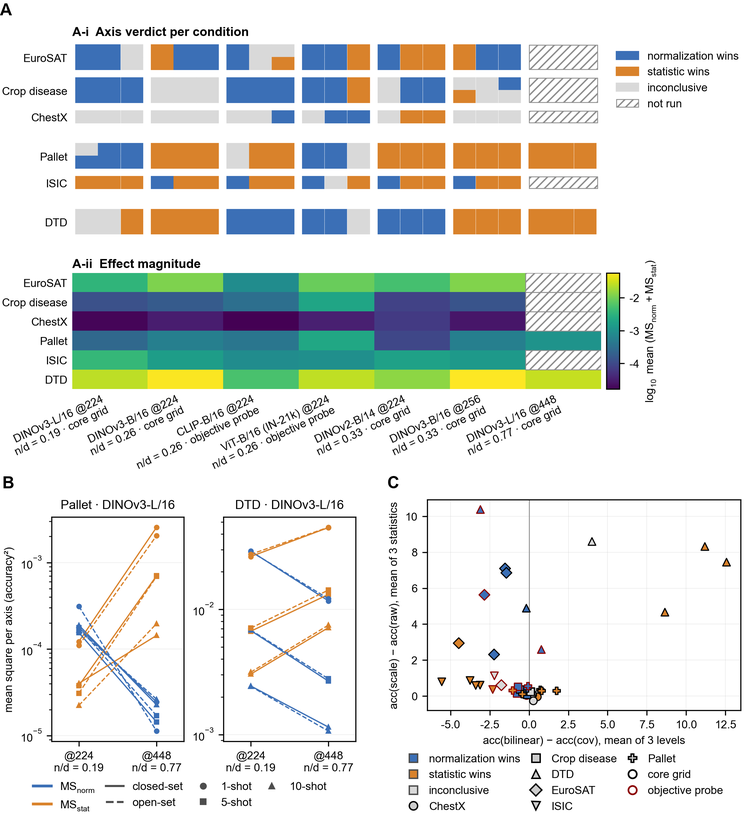

  Fig2: 2235×2097 px = 7.45×6.99 in, 0.7 MB, 1 panel


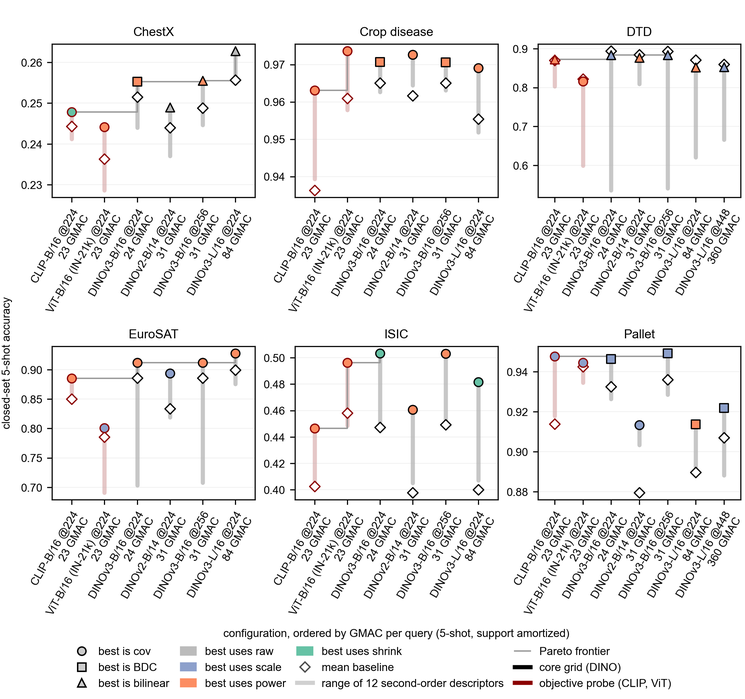

  Fig3: 2236×2514 px = 7.45×8.38 in, 1.0 MB, 2 panel, nhãn A–B


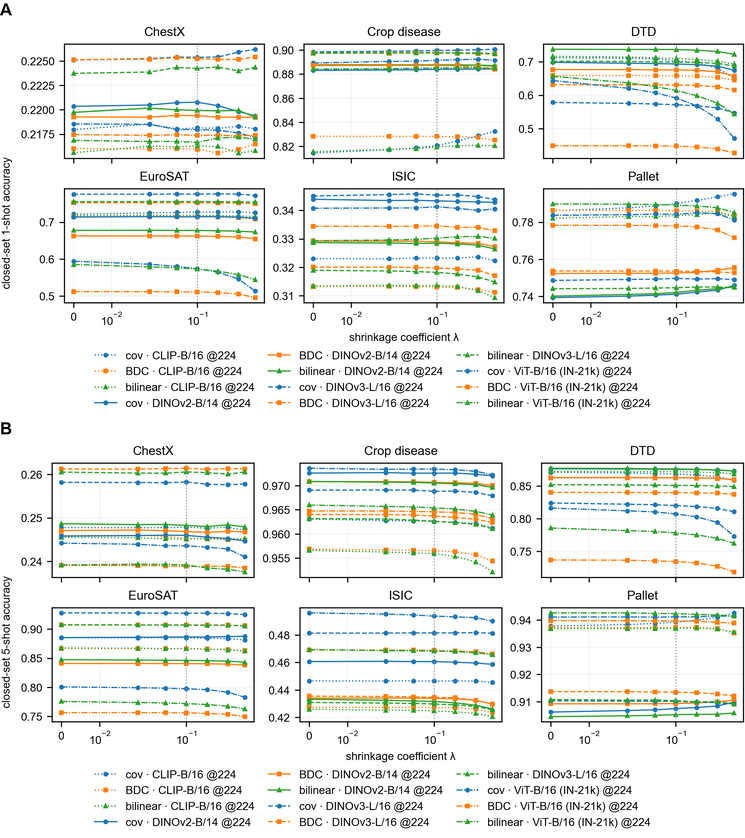

  Fig4: 2236×2514 px = 7.45×8.38 in, 0.5 MB, 2 panel, nhãn A–B


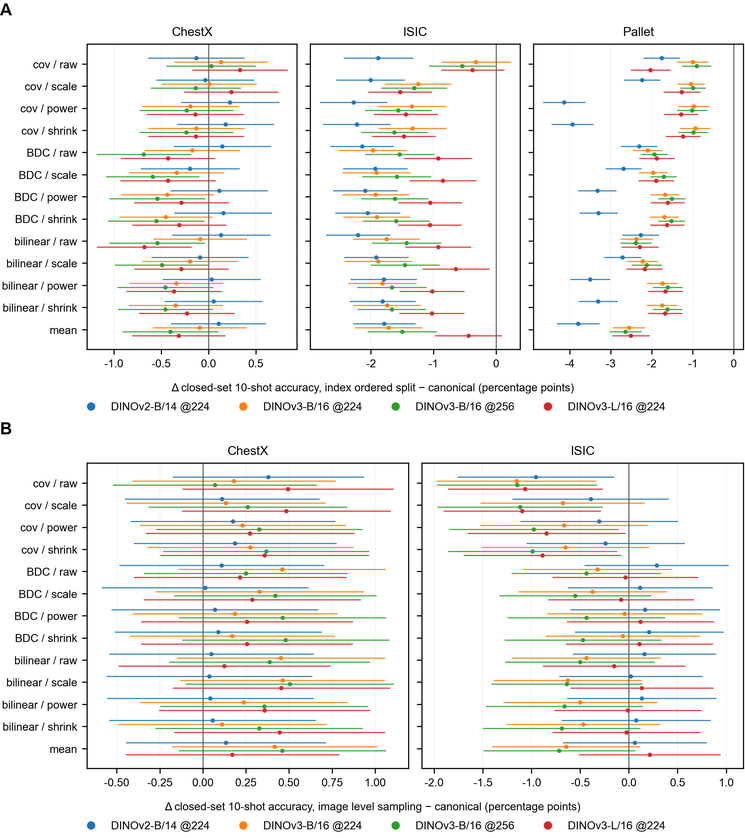

  Fig1.pdf: 7.46×8.22 in, 0.27 MB, vector
  Fig2.pdf: 7.45×6.99 in, 0.03 MB, vector
  Fig3.pdf: 7.45×8.38 in, 0.27 MB, vector
  Fig4.pdf: 7.45×8.38 in, 0.27 MB, vector
  /content/sopfsl/figures_final.zip  (5.2 MB)


PosixPath('/content/sopfsl/figures_final.zip')

In [ ]:
#@title §9.15 Combine panels into the PLOS submission figures (TIFF 300 dpi + PNG for Overleaf)
"""Reads results/figs/manifest.json (gate H5 of §8.6) and pastes the panels of FIG_COMBOS
pixel for pixel into one file per figure, so font sizes stay as checked at H4.
H6a each panel size matches the manifest.
H6b combined file ≤ 2250 × 2625 px.
H6c TIFF reopens as RGB at 300 dpi and is below 10 MB (PLOS limit per figure).
H6d A/B/C labels use true Arial Bold.
H6e each vector PDF panel matches its PNG size within ±0.05 in.
"""
from PIL import Image, ImageDraw, ImageFont
from matplotlib import font_manager
from matplotlib.font_manager import FontProperties

try:
    import fitz                                  # PyMuPDF
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pymupdf"], check=True)
    import fitz

FINAL_DIR = FIG_DIR / "final"
FINAL_DIR.mkdir(exist_ok=True)
LABEL_PT = 12                                   # panel label, PLOS allows 8–12 pt


def _arial_bold_path() -> str:
    """Resolve the Arial Bold file registered in §8.6."""
    p = font_manager.findfont(FontProperties(family="Arial", weight="bold"),
                              fallback_to_default=False)
    name = Path(p).name.lower()
    if "arial" not in name or not any(t in name for t in ("bold", "bd")):
        raise AssertionError(f"H6d: findfont returned {p}, not Arial Bold. "
                             "Check _setup_fonts in §8.6.")
    return p

def _load_or_build_manifest() -> dict:
    """Prefer the manifest written by gate H5, otherwise rebuild it from the PNGs on disk."""
    p = FIG_DIR / "manifest.json"
    if p.exists():
        return json.loads(p.read_text())
    print("  manifest.json missing, rebuilding from the PNGs on disk")
    combos = globals().get("FIG_COMBOS") or {
        "Fig1": [["fig1a_boundary_map"],
                 ["fig1b_resolution_mechanism", "fig1c_axis_contrasts_5shot"]],
        "Fig2": [["fig2_pareto_5shot"]],
        "Fig3": [["fig3_lambda_1shot"], ["fig3_lambda_5shot"]],
        "Fig4": [["fig4_sensitivity_by_index_10shot"], ["fig4_sensitivity_no_groups_10shot"]],
    }
    dpi = DPI
    label, gap = int(round(LABEL_H_IN * dpi)), int(round(GAP_IN * dpi))
    panels, out = {}, {}
    for fig_name, rows in combos.items():
        for n in (n for r in rows for n in r):
            f = FIG_DIR / f"{n}.png"
            assert f.exists(), f"missing {f.name}, run §9.14 first"
            panels[n] = list(Image.open(f).size)
        h = sum(label + max(panels[n][1] for n in r) for r in rows)
        w = max(sum(panels[n][0] for n in r) + gap * (len(r) - 1) for r in rows)
        out[fig_name] = {"rows": rows, "px": [w, h]}
    mf = {"dpi": dpi, "panels": panels, "combos": out}
    p.write_text(json.dumps(mf, indent=2))
    return mf

def combine_all(show: bool = True) -> dict:
    mf = _load_or_build_manifest()
    assert mf and "combos" in mf, "manifest.json missing, run §9.14 first"
    dpi = mf["dpi"]
    label_h = int(round(LABEL_H_IN * dpi))
    gap = int(round(GAP_IN * dpi))
    max_w, max_h = int(round(FULL_W * dpi)), int(round(MAX_H * dpi))
    font = ImageFont.truetype(_arial_bold_path(), int(round(LABEL_PT / 72 * dpi)))
    out = {}
    for fig_name, combo in mf["combos"].items():
        rows = combo["rows"]
        multi = sum(len(r) for r in rows) > 1
        W, H = combo["px"]
        canvas = Image.new("RGB", (W, H), "white")
        draw = ImageDraw.Draw(canvas)
        y, letter = 0, ord("A")
        for row in rows:
            ims = []
            for n in row:
                im = Image.open(FIG_DIR / f"{n}.png").convert("RGB")
                exp = tuple(mf["panels"][n])
                if im.size != exp:                                            # H6a
                    raise AssertionError(f"H6a: {n}.png is {im.size}, manifest says {exp}. "
                                         "§8.6 was rerun after the manifest was written, rerun §9.14.")
                ims.append(im)
            row_w = sum(im.width for im in ims) + gap * (len(ims) - 1)
            x = (W - row_w) // 2
            for im in ims:
                if multi:
                    draw.text((x, y), chr(letter), fill="black", font=font)
                    letter += 1
                canvas.paste(im, (x, y + label_h))
                x += im.width + gap
            y += label_h + max(im.height for im in ims)
        assert canvas.size == (W, H), f"{fig_name}: built {canvas.size}, manifest {W}×{H}"
        assert W <= max_w and H <= max_h, f"H6b: {fig_name} {W}×{H} px exceeds {max_w}×{max_h}"

        tif = FINAL_DIR / f"{fig_name}.tiff"
        png = FINAL_DIR / f"{fig_name}.png"
        canvas.save(tif, format="TIFF", dpi=(dpi, dpi), compression="tiff_lzw")
        canvas.save(png, format="PNG", dpi=(dpi, dpi))                       # copy for Overleaf

        chk = Image.open(tif)                                                 # H6c
        got_dpi = tuple(int(round(v)) for v in chk.info.get("dpi", (0, 0)))
        mb = tif.stat().st_size / 1e6
        assert chk.mode == "RGB" and chk.size == (W, H), f"H6c: {tif.name} reopens with wrong mode/size"
        assert got_dpi == (dpi, dpi), f"H6c: {tif.name} stores dpi {got_dpi}, need {dpi}"
        assert mb < 10, f"H6c: {tif.name} is {mb:.1f} MB, PLOS limit is 10 MB"
        out[fig_name] = dict(px=(W, H), inch=(W / dpi, H / dpi), mb=mb,
                             panels=[n for r in rows for n in r])
        print(f"  {fig_name}: {W}×{H} px = {W / dpi:.2f}×{H / dpi:.2f} in, "
              f"{mb:.1f} MB, {len(out[fig_name]['panels'])} panel(s)"
              + (f", labels A–{chr(letter - 1)}" if multi else ""))
        if show:
            from IPython.display import display
            display(canvas.resize((W // 3, H // 3), Image.LANCZOS))   # preview only, not saved
    return out

def combine_pdf() -> dict:
    """Combine the vector PDF panels into Fig*.pdf with the TIFF layout, page size from the
    manifest in points (72/in)."""
    mf = _load_or_build_manifest()
    dpi, PT = mf["dpi"], 72.0
    label_pt, gap_pt = LABEL_H_IN * PT, GAP_IN * PT
    font_path = _arial_bold_path()
    out = {}
    for fig_name, combo in mf["combos"].items():
        rows = combo["rows"]
        multi = sum(len(r) for r in rows) > 1
        W_pt, H_pt = combo["px"][0] / dpi * PT, combo["px"][1] / dpi * PT
        srcs = {n: fitz.open(FIG_DIR / f"{n}.pdf") for r in rows for n in r}
        for n, d in srcs.items():                                             # H6e
            got = (d[0].rect.width / PT, d[0].rect.height / PT)
            exp = (mf["panels"][n][0] / dpi, mf["panels"][n][1] / dpi)
            if abs(got[0] - exp[0]) > 0.05 or abs(got[1] - exp[1]) > 0.05:
                raise AssertionError(f"H6e: {n}.pdf is {got[0]:.2f}×{got[1]:.2f} in, "
                                     f"PNG is {exp[0]:.2f}×{exp[1]:.2f} in. Rerun §9.14.")
        doc = fitz.open()
        page = doc.new_page(width=W_pt, height=H_pt)
        y, letter = 0.0, ord("A")
        for row in rows:
            ws = [srcs[n][0].rect.width for n in row]
            hs = [srcs[n][0].rect.height for n in row]
            x = (W_pt - (sum(ws) + gap_pt * (len(row) - 1))) / 2
            for n, w, h in zip(row, ws, hs):
                if multi:
                    page.insert_text((x, y + LABEL_PT), chr(letter), fontsize=LABEL_PT,
                                     fontname="ArialBold", fontfile=font_path)
                    letter += 1
                page.show_pdf_page(fitz.Rect(x, y + label_pt, x + w, y + label_pt + h),
                                   srcs[n], 0)
                x += w + gap_pt
            y += label_pt + max(hs)
        assert y <= H_pt + 1.0, f"{fig_name}: PDF content height {y:.0f} pt > page {H_pt:.0f} pt"
        pdf = FINAL_DIR / f"{fig_name}.pdf"
        doc.save(pdf, garbage=3, deflate=True)
        doc.close()
        for d in srcs.values():
            d.close()
        out[fig_name] = pdf.stat().st_size / 1e6
        print(f"  {fig_name}.pdf: {W_pt / PT:.2f}×{H_pt / PT:.2f} in, {out[fig_name]:.2f} MB, vector")
    return out

def zip_final() -> Path:
    """Zip TIFF + PNG for download (TIFF for PLOS, PNG for Overleaf/figs)."""
    import shutil
    z = shutil.make_archive(str(WORK / "figures_final"), "zip", FINAL_DIR)
    print(f"  {z}  ({Path(z).stat().st_size / 1e6:.1f} MB)")
    return Path(z)


summary = combine_all(show=True)
combine_pdf()
zip_final()